# Qué conservan los embeddings cuando una canción habla de miedo

**Cuaderno en español · 120 canciones seleccionadas · comparación común: 40 canciones / 4 encoders · corte: 11 de octubre de 2026.**

Lejos de criticar o alabar una época, me interesa comprender qué sentimientos perduran entre décadas, cómo se desarrolla la historia que cuenta una canción y qué considera valioso proteger su voz. Esta vez sigo canciones sobre el miedo mediante embeddings, subtemas y arcos argumentales. El tiempo histórico compara publicaciones; el tiempo argumental sigue pasos dentro de una letra.

Una canción puede nombrar el miedo y negarlo, prestar su voz a un personaje o volver a un estribillo sin resolver nada. La revisión anual uniforme reúne dos lecturas por cada una de las 120 letras: 53 referencias apoyadas, 37 ausencias y 30 casos inciertos. Los resultados anteriores del panel de 40 se conservan como fase histórica, sin mezclarlos con los nuevos votos. La comparación entre cuatro encoders usa exactamente las mismas 40 canciones; la expansión local constituye una cohorte separada.

Las tablas y conclusiones se calculan desde los recibos de las corridas guardadas. La revisión interpretativa añade votos de un panel automatizado con procedencia y evidencia por ID. Los resultados describen el corpus seleccionado; las diferencias entre períodos pueden reflejar artistas, versiones, idiomas y decisiones de selección.

In [1]:
from pathlib import Path
import json, os, sys, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, SVG, Markdown

# Soporta tanto el repositorio como un paquete descargado con estructura plana.
candidates = [Path.cwd(), *Path.cwd().parents]
STUDY = next((d for p in candidates for d in [p/'research/fear-lyrics', p]
              if (d/'analyze.py').exists() and (d/'corpus-manifest.json').exists()), None)
if STUDY is None:
    raise FileNotFoundError('Extrae el paquete completo y abre el notebook junto a sus scripts y resultados.')
ROOT = STUDY.parents[1] if STUDY.parent.name == 'research' else STUDY.parent
RESULTS = STUDY/'results'
FIGURES = STUDY/'figures'
PRIVATE = Path(os.environ.get('FEAR_PRIVATE_CACHE', ROOT/'.research-cache/fear-lyrics'))
read = lambda p: json.loads(Path(p).read_text(encoding='utf-8'))
full_manifest = pd.DataFrame(read(STUDY/'corpus-manifest.json'))
common_ids = set(pd.read_csv(RESULTS/'section_inventory.csv').song_id)
manifest = full_manifest[full_manifest.song_id.isin(common_ids)].copy()
EXPANDED = STUDY/'expanded'
EXPANDED_RESULTS = EXPANDED/'results'
expanded_modeldirs = sorted(p for p in EXPANDED_RESULTS.iterdir() if p.is_dir() and (p/'model_manifest.json').exists()) if EXPANDED_RESULTS.exists() else []
PANEL = next((p for p in [STUDY/'pilot-comparison/results/arc-panel', RESULTS/'arc-panel']
              if (p/'panel_votes.json').exists()), RESULTS/'arc-panel')
diag = read(RESULTS/'corpus_diagnostics.json')
modeldirs = sorted(p for p in RESULTS.iterdir() if p.is_dir() and (p/'model_manifest.json').exists())
model_receipts = {p.name: read(p/'model_manifest.json') for p in modeldirs}

# Abrir/ejecutar las celdas lee resultados guardados. No se ejecutan experimentos.
# Para recalcular, se requieren corpus privado autorizado y embeddings locales.
RERUN_EXPERIMENTS = os.environ.get('RERUN_FEAR_EXPERIMENTS') == '1'

def frame(path):
    path = Path(path)
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

def figure(name, caption=None):
    options = [FIGURES/name, RESULTS/'bayes'/name]
    path = next((p for p in options if p.exists()), None)
    if path is None:
        display(Markdown('Figura no incluida en esta versión del paquete: `'+name+'`.'))
        return
    if path.suffix == '.svg': display(SVG(filename=str(path)))
    else: display(Image(filename=str(path)))
    if caption: display(Markdown('*'+caption+'*'))

def public_rows(value):
    if isinstance(value, list): return value
    if isinstance(value, dict):
        for key in ['rows', 'annotations', 'votes', 'records', 'models']:
            if isinstance(value.get(key), list): return value[key]
    return []

assert manifest.song_id.is_unique and modeldirs
print('Colección seleccionada:', len(full_manifest), 'canciones')
print('Comparación común:', len(manifest), 'canciones;', manifest.artist.nunique(), 'artistas')
print('Con letras recuperadas:', diag.get('songs_with_lyrics'), '| bloques únicos:', diag.get('unique_blocks'))
print('Modelos ejecutados:', ', '.join(r['encoder']['model_id'] for r in model_receipts.values()))

Colección seleccionada: 120 canciones
Comparación común: 40 canciones; 34 artistas
Con letras recuperadas: 40 | bloques únicos: 386
Modelos ejecutados: intfloat/multilingual-e5-small, openai/text-embedding-3-large, openai/text-embedding-3-small, sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


## 1. Una voz no es un artista; un vector no es una emoción

Distinguimos situación, emoción representada, postura y arco narrativo. Cada lectura necesita identificar quién habla, quién experimenta el miedo, a qué se enfrenta y qué contradice la interpretación. El oyente constituye otro objeto: este estudio no mide audio ni recepción.

La claridad de [The Illustrated Word2vec](https://jalammar.github.io/illustrated-word2vec/) inspira una explicación gradual: texto, vector, vecindad y decisiones observables. La cercanía entre vectores puede reflejar vocabulario compartido sin resolver diferencias de negación, roles o secuencia de eventos.

## 2. Corpus, períodos y versiones

La selección intencional se organiza por idioma y período: 1980s, 1990s, 2000s, 2010s y 2020–2026 parcial. La primera tabla presenta toda la colección y la segunda la cohorte común de encoders. El tamaño efectivo se presenta en la tabla; se conserva el piloto en su archivo separado y las corridas finales no se mezclan con sus denominadores.

Usamos el año de primera publicación de la grabación y distinguimos esa fecha del año de su éxito comercial. Las etiquetas iniciales orientan la selección; no entran en el índice de recuperación. El equilibrio de idiomas y períodos no iguala géneros, países o concentración por artista.

### Colección ampliada

language,Inglés,Español
decade,,
1980,12,12
1990,12,12
2000,12,12
2010,12,12
2020,12,12


### Cohorte común para comparar todos los encoders

language,Inglés,Español
decade,,
1980,4,4
1990,4,4
2000,4,4
2010,4,4
2020,4,4


,title,artist,year,language,selection_label
0,Thriller,Michael Jackson,1982,en,fear
1,Mad World,Tears for Fears,1982,en,ambiguous
2,Somebody's Watching Me,Rockwell,1983,en,fear
3,Wake Me Up Before You Go-Go,Wham!,1984,en,control
4,En algún lugar,Duncan Dhu,1987,es,ambiguous
5,Hijo de la Luna,Mecano,1986,es,ambiguous
6,Cruz de Navajas,Mecano,1986,es,ambiguous
7,Bailando,Alaska y los Pegamoides,1982,es,control
8,Enter Sandman,Metallica,1991,en,fear
9,Zombie,The Cranberries,1994,en,fear


,consultadas,disponibles
provider,,
genius,120,102
lrclib,120,119


,,pares,mediana_similitud,mínimo,idénticas
provider_a,provider_b,,,,
lrclib,genius,101,0.939693,0.34609,0


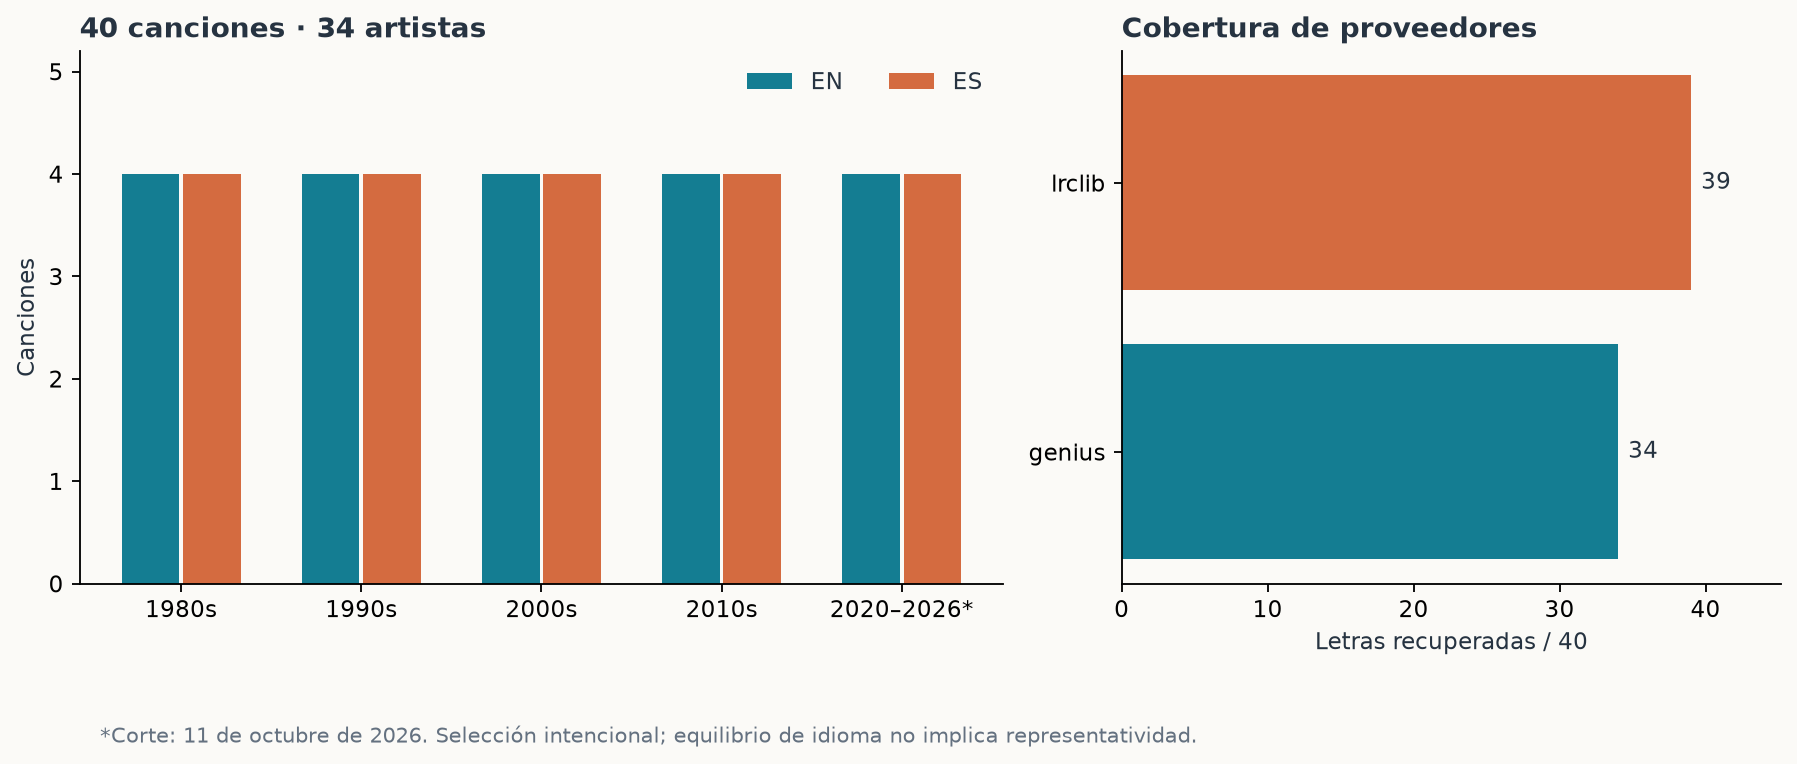

In [2]:
display(Markdown('### Colección ampliada'))
display(full_manifest.groupby(['decade','language']).size().unstack(fill_value=0).rename(columns={'en':'Inglés','es':'Español'}))
display(Markdown('### Cohorte común para comparar todos los encoders'))
display(manifest.groupby(['decade','language']).size().unstack(fill_value=0).rename(columns={'en':'Inglés','es':'Español'}))
display(manifest[['title','artist','year','language','selection_label']])
coverage = frame(STUDY/'provider-coverage.csv')
agreement = frame(STUDY/'provider-agreement.csv')
if not coverage.empty:
    display(coverage.assign(available=coverage.status.astype(str).eq('200')).groupby('provider').agg(
        consultadas=('song_id','size'), disponibles=('available','sum')))
if not agreement.empty:
    display(agreement.groupby(['provider_a','provider_b']).agg(
        pares=('song_id','size'), mediana_similitud=('sequence_similarity','median'),
        mínimo=('sequence_similarity','min'), idénticas=('normalized_exact_match','sum')))
figure('corpus-providers.png')

**Alcance de la tabla y la figura.** `provider-coverage.csv` registra las 120 canciones de la colección vigente. La figura `corpus-providers.png` corresponde a la cohorte emparejada de 40 canciones.

La procedencia forma parte de la medida. [LyricsGenius](https://lyricsgenius.readthedocs.io/en/master/how_it_works.html) usa Genius para metadatos y búsqueda, y extrae la letra de la página. Disponibilidad y acuerdo entre proveedores no certifican la edición correcta ni la independencia de las fuentes.

Las letras permanecen en caché privada. El paquete público contiene IDs, hashes, metadatos, agregados, figuras y scripts. Distinguir grabación de estudio y versión en vivo, o conservar pronombres y negaciones, cambia el objeto del análisis.

## 3. Bloques para representar; canciones para ponderar

Se preservan párrafos y orden; los segmentos largos se dividen en ventanas. Los bloques repetidos exactamente dentro de una canción se deduplican para ajustar tópicos. Las comparaciones conservan dos variantes: primera aparición y todas las repeticiones.

El ajuste global recibe cada bloque único una vez. Las proporciones temporales dan igual peso a cada canción dentro de idioma y después a los idiomas disponibles. Los intervalos bootstrap remuestrean esas canciones; no corrigen el diseño de selección.

In [3]:
keys = [k for k in ['blocks','unique_blocks','exact_repeated_blocks','cutoff','corpus_identity'] if k in diag]
display(pd.Series({k:diag[k] for k in keys}))
inventory = frame(RESULTS/'section_inventory.csv')
if not inventory.empty: assert inventory.document_id.is_unique
models = []
for directory in modeldirs:
    receipt = model_receipts[directory.name]
    encoder = receipt['encoder']
    models.append({'modelo':encoder['model_id'], 'dimensiones':encoder.get('dimensions'),
        'ventana_tokens':encoder.get('max_seq_length'), 'bloques':receipt.get('unique_documents'),
        'bloques_truncados':receipt.get('truncated_documents'),
        'segundos_corrida':receipt.get('runtime_seconds'), 'estado':receipt['results_status']})
display(pd.DataFrame(models))

blocks                                                                 461
unique_blocks                                                          386
exact_repeated_blocks                                                   75
cutoff                                                          2026-10-11
corpus_identity          d10938991b3994c9b7cd413eb5a235668523bf629311d6...
dtype: object

,modelo,dimensiones,ventana_tokens,bloques,bloques_truncados,segundos_corrida,estado
0,intfloat/multilingual-e5-small,384,512,386,0,2.40,executed
1,openai/text-embedding-3-large,1024,8192,386,0,16.07,executed
2,openai/text-embedding-3-small,1024,8192,386,0,11.17,executed
3,sentence-transformers/paraphrase-multilingual-...,384,128,386,2,12.20,executed


## 4. Modelos y contrastes de significado

Los dos modelos locales, [MiniLM multilingüe](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2) y [E5 small multilingüe](https://huggingface.co/intfloat/multilingual-e5-small), tienen tareas y ventanas diferentes. E5 distingue los prefijos `query:` y `passage:`. Los encoders OpenAI se identifican en la tabla por modelo y dimensiones realmente utilizadas.

Se usa normalización L2 dentro de cada modelo. Comparamos rankings, particiones y sensibilidad: un coseno más alto en otro espacio no significa más miedo. Los límites de tokens importan especialmente cuando el contraste aparece al final del bloque.

Las veinte tripletas originales EN/ES examinan traducción, paráfrasis, contexto, motivos, experienciador, negación, roles, repetición, orden y truncación. A no es siempre una respuesta correcta: negación y roles pueden conservar cercanía semántica mientras cambian la afirmación.

,model,id,category,related_cosine,contrast_cosine,related_minus_contrast
0,intfloat/multilingual-e5-small,negation_en,negation,0.909232,0.818072,0.091160
1,intfloat/multilingual-e5-small,negation_es,negation,0.917552,0.844038,0.073513
2,intfloat/multilingual-e5-small,role_en,role_reversal,0.989925,0.931676,0.058249
3,intfloat/multilingual-e5-small,role_es,role_reversal,0.990926,0.944916,0.046011
4,intfloat/multilingual-e5-small,translation_en_es,crosslingual,0.872449,0.749441,0.123009
...,...,...,...,...,...,...
75,sentence-transformers/paraphrase-multilingual-...,motive_es,motive_context,0.533968,0.354706,0.179263
76,sentence-transformers/paraphrase-multilingual-...,experiencer_en,experiencer,0.810538,0.765286,0.045252
77,sentence-transformers/paraphrase-multilingual-...,experiencer_es,experiencer,0.795585,0.700766,0.094819
78,sentence-transformers/paraphrase-multilingual-...,order_en,narrative_order,0.699892,0.706110,-0.006218


,model,id,related_cosine,contrast_cosine,query_tokenizer_tokens,query_exceeds_max_seq_length
18,intfloat/multilingual-e5-small,order_en,0.872257,0.870207,17,False
19,intfloat/multilingual-e5-small,long_ending_es,0.827470,0.827470,23,False
38,openai/text-embedding-3-large,order_en,0.593852,0.573098,10,False
39,openai/text-embedding-3-large,long_ending_es,0.574142,0.525621,21,False
58,openai/text-embedding-3-small,order_en,0.596489,0.566083,None,False
59,openai/text-embedding-3-small,long_ending_es,0.518865,0.452739,None,False
78,sentence-transformers/paraphrase-multilingual-...,order_en,0.699892,0.706110,15,False
79,sentence-transformers/paraphrase-multilingual-...,long_ending_es,0.430526,0.430526,21,False


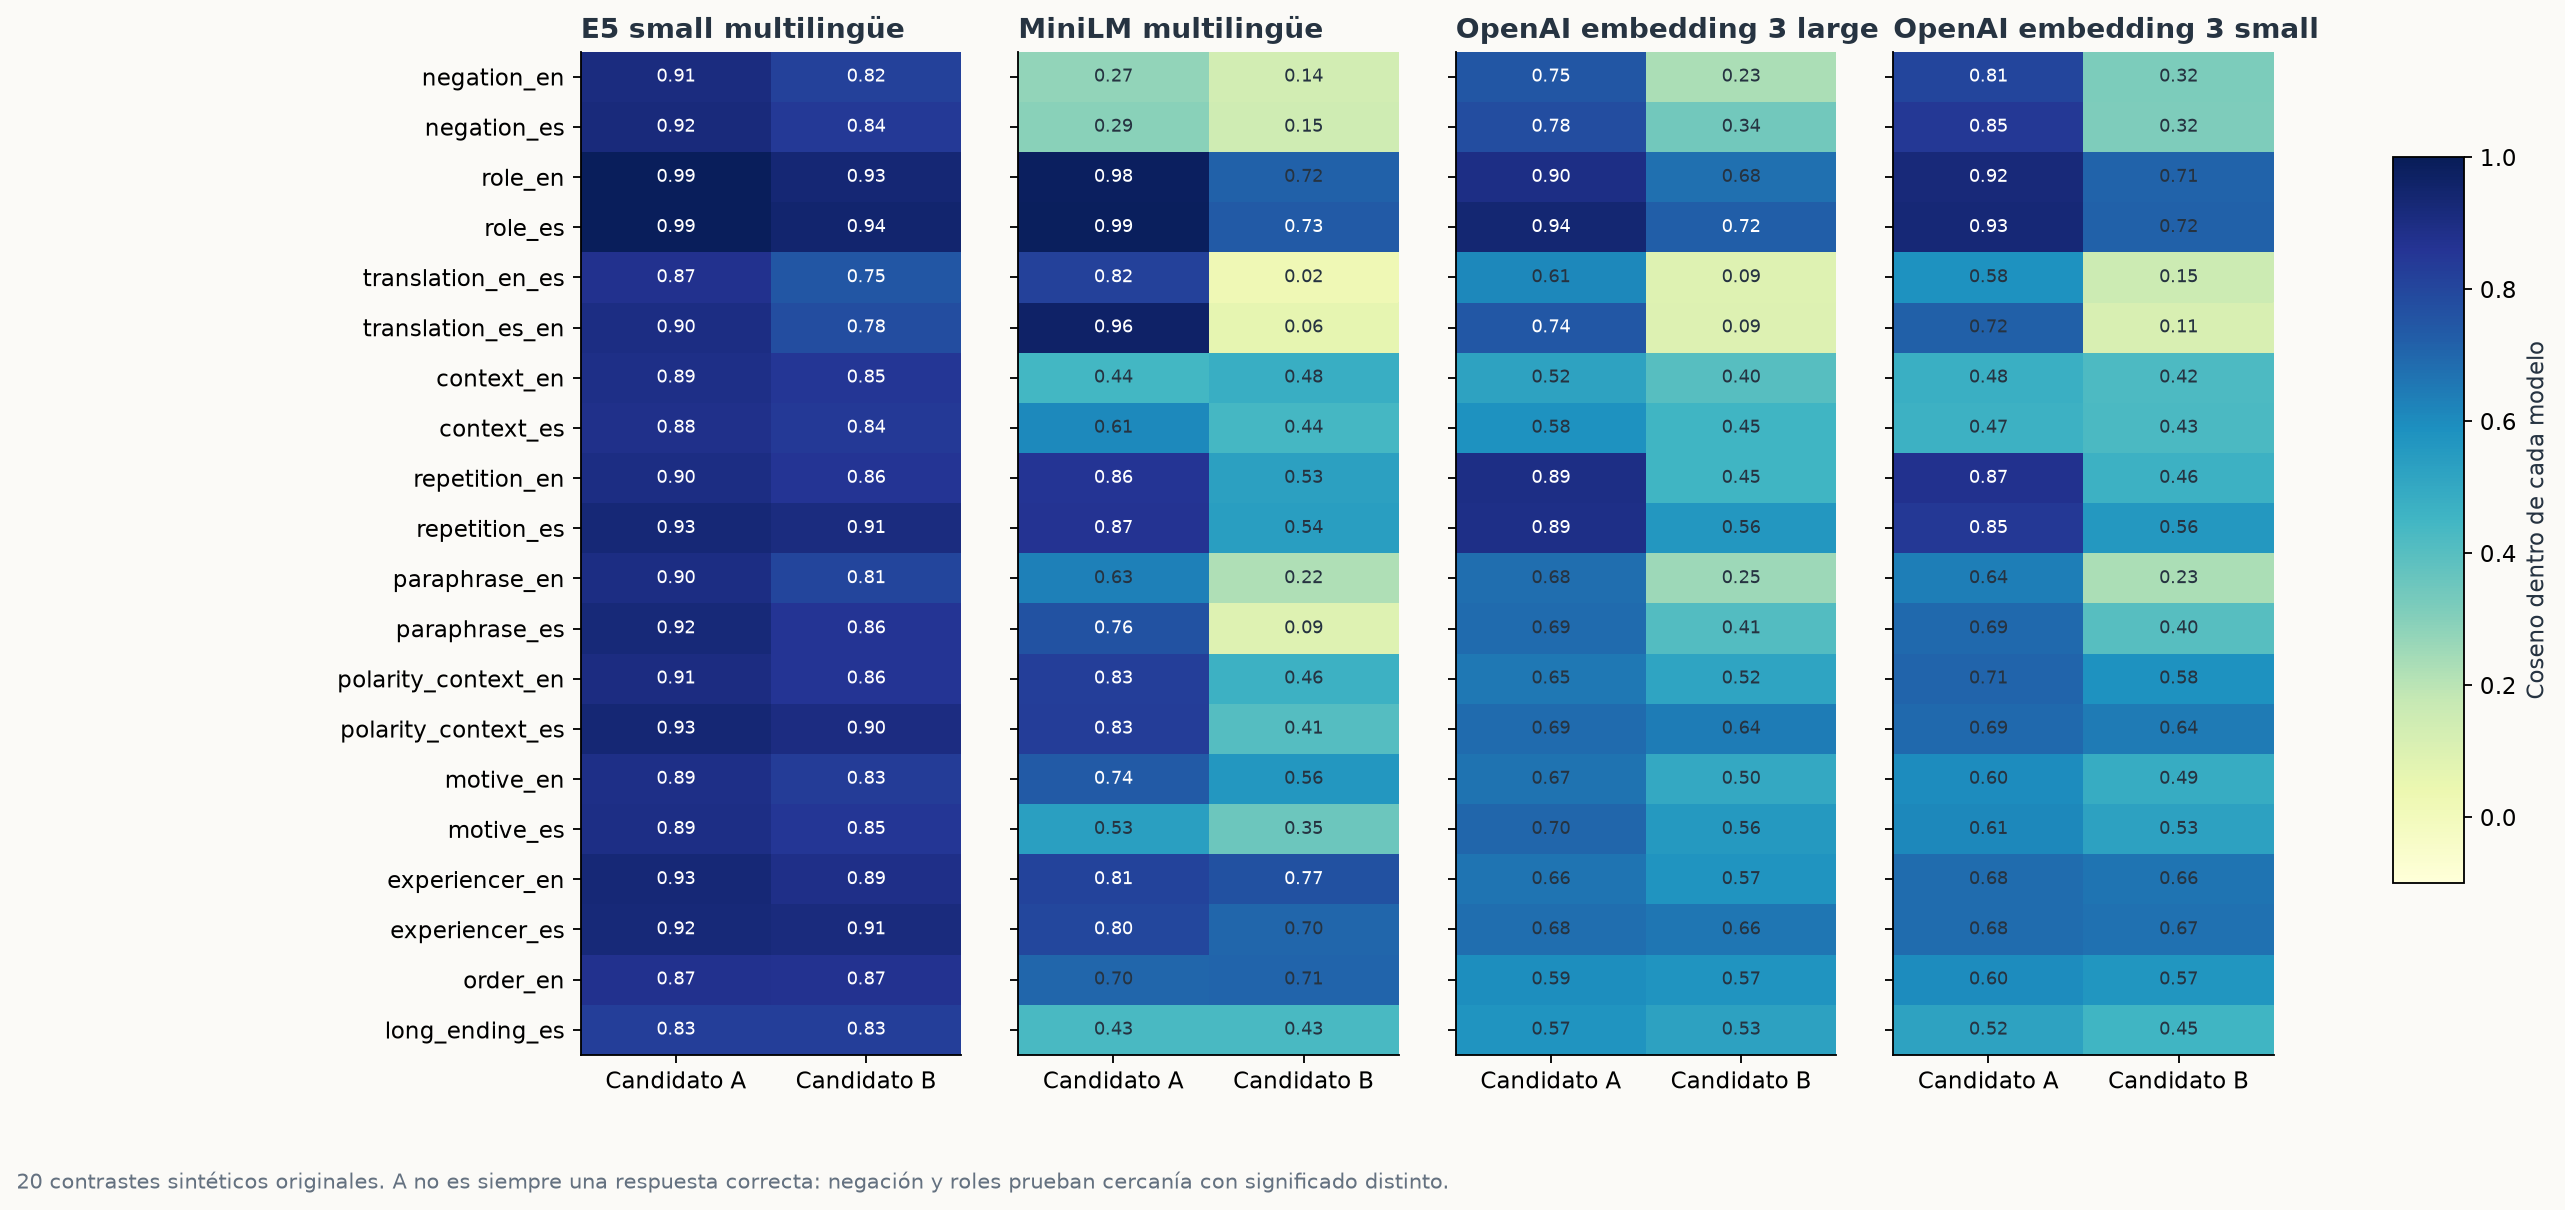

In [4]:
probe_tables = [pd.DataFrame(read(p/'semantic_probes.json')['probes']).assign(model=model_receipts[p.name]['encoder']['model_id'])
                for p in modeldirs if (p/'semantic_probes.json').exists()]
probes = pd.concat(probe_tables, ignore_index=True) if probe_tables else pd.DataFrame()
if not probes.empty:
    display(probes[['model','id','category','related_cosine','contrast_cosine','related_minus_contrast']])
    display(probes[probes.category.isin(['narrative_order','long_ending'])][
        ['model','id','related_cosine','contrast_cosine','query_tokenizer_tokens','query_exceeds_max_seq_length']])
figure('semantic-probes.png')

## 5. UMAP, PCA 3D y la varianza que queda fuera

UMAP 2D dispone bloques en una proyección exploratoria ajustada separadamente del clustering. El color corresponde al tópico local; los IDs y colores no alinean grupos entre modelos.

PCA usa una sola base global por modelo sobre todos sus bloques únicos normalizados. Un ajuste full-SVD proporciona hasta veinte componentes y el mapa usa los primeros tres de ese mismo ajuste. Las tablas separan la varianza de tres ejes del espectro acumulado. Ni los ejes PCA ni las distancias 2D/3D constituyen escalas de miedo.

Los centroides temporales se calculan en el embedding original: media de bloques dentro de canción, de canciones dentro de idioma y de los idiomas presentes. Se proyectan con la misma base PCA, sin reajustarla por año. Los puntos con menos de tres canciones se marcan como soporte escaso; las líneas sólo conectan períodos observados consecutivos con al menos tres canciones en ambos extremos. Una ausencia no se imputa como cero.

El selector anual cambia qué grabaciones observamos. Las trayectorias describen una composición cambiante, no movimiento de las mismas canciones. Los representantes de cada centroide son hasta tres canciones distintas elegidas por coseno en el espacio original, y se publican sus IDs y metadatos.

,modelo,canciones,bloques,dimensiones_origen,PC1,PC2,PC3,acumulada_3D,acumulada_hasta_20,PCs_en_recibo,SHA_corpus,semilla,solver
0,intfloat/multilingual-e5-small,40,386,384,0.114978,0.044150,0.032356,0.191483,0.454719,20,d2e4e3af3ebecf88dfc42814935ec6cc5a79d42f66e04c...,None,full
1,openai/text-embedding-3-large,40,386,1024,0.100027,0.038858,0.033051,0.171935,0.449853,20,d2e4e3af3ebecf88dfc42814935ec6cc5a79d42f66e04c...,None,full
2,openai/text-embedding-3-small,40,386,1024,0.088634,0.037352,0.032572,0.158558,0.440546,20,d2e4e3af3ebecf88dfc42814935ec6cc5a79d42f66e04c...,None,full
3,sentence-transformers/paraphrase-multilingual-...,40,386,384,0.064346,0.046005,0.041294,0.151645,0.538944,20,d2e4e3af3ebecf88dfc42814935ec6cc5a79d42f66e04c...,None,full


**intfloat/multilingual-e5-small** conserva **19.1%** de la varianza en tres dimensiones. El resto queda fuera de este mapa.

**openai/text-embedding-3-large** conserva **17.2%** de la varianza en tres dimensiones. El resto queda fuera de este mapa.

**openai/text-embedding-3-small** conserva **15.9%** de la varianza en tres dimensiones. El resto queda fuera de este mapa.

**sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2** conserva **15.2%** de la varianza en tres dimensiones. El resto queda fuera de este mapa.

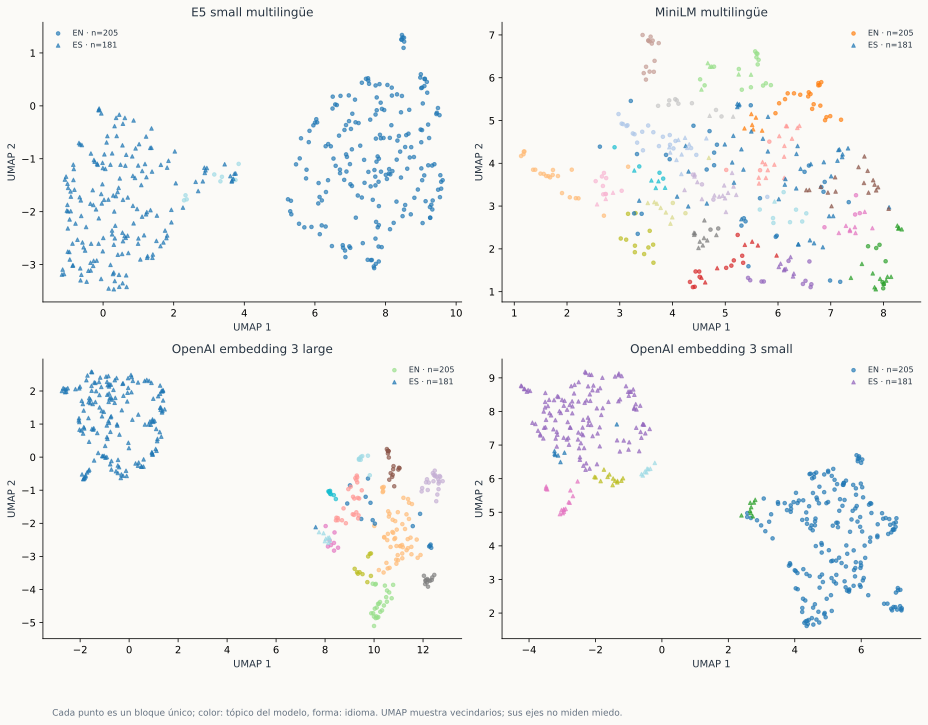

*UMAP exploratorio separado del ajuste de tópicos; no comparar distancias visuales entre modelos.*

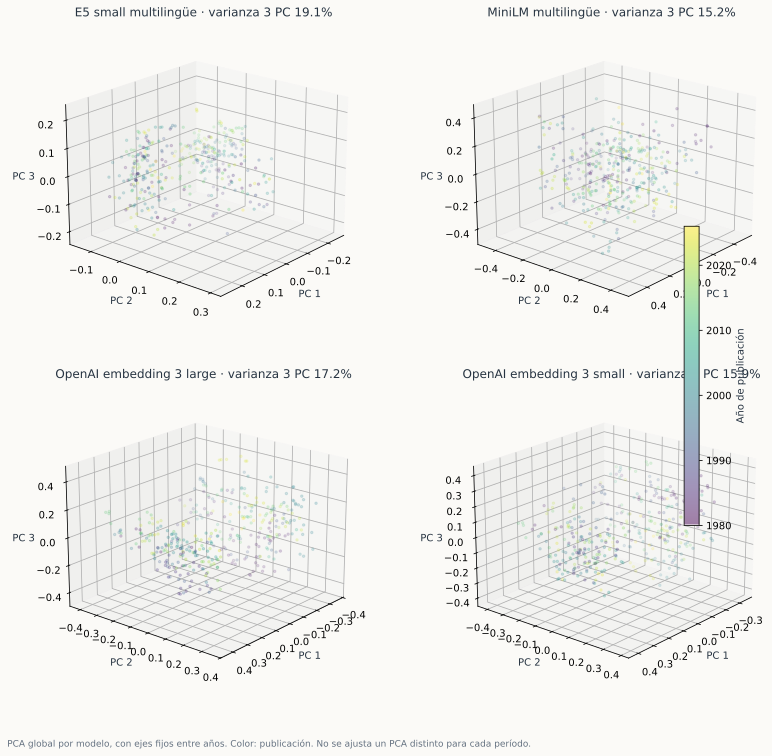

*PCA global por modelo; mismos ejes para todos los años de esa representación.*

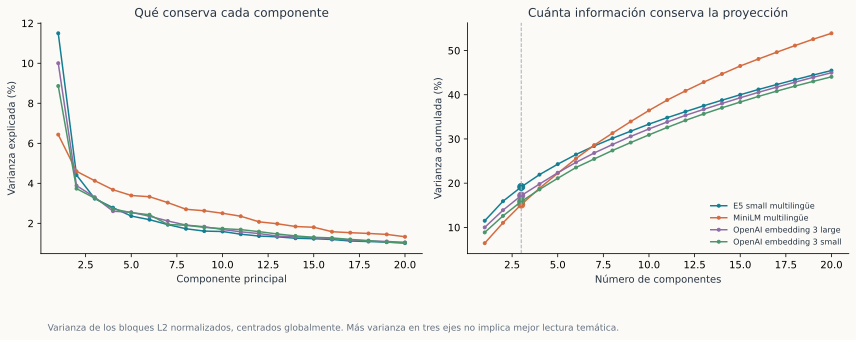

*Varianza explicada y acumulada de los componentes calculados; fracciones dentro de cada modelo.*

,modelo,PC,varianza,acumulada
0,intfloat/multilingual-e5-small,1,0.114978,0.114978
1,intfloat/multilingual-e5-small,2,0.044150,0.159127
2,intfloat/multilingual-e5-small,3,0.032356,0.191483
3,intfloat/multilingual-e5-small,4,0.027843,0.219326
4,intfloat/multilingual-e5-small,5,0.023649,0.242976
...,...,...,...,...
75,sentence-transformers/paraphrase-multilingual-...,16,0.015823,0.480850
76,sentence-transformers/paraphrase-multilingual-...,17,0.015345,0.496195
77,sentence-transformers/paraphrase-multilingual-...,18,0.014956,0.511151
78,sentence-transformers/paraphrase-multilingual-...,19,0.014485,0.525635


In [5]:
projection_receipts = []
scree = []
for directory in modeldirs:
    path = directory/'projections.json'
    if not path.exists(): continue
    p = read(path); r = p['receipt']
    a = r['explained_variance_ratio']
    spectrum = r.get('scree_explained_variance_ratio', a)
    projection_receipts.append({'modelo':r['model_id'],'canciones':r['input_songs'],
        'bloques':r['input_documents'],'dimensiones_origen':r['input_dimensions'],
        'PC1':a[0],'PC2':a[1],'PC3':a[2], 'acumulada_3D':r['explained_variance_total'],
        'acumulada_hasta_20':sum(spectrum),'PCs_en_recibo':len(spectrum),
        'SHA_corpus':r['corpus_sha256'], 'semilla':r['seed'],'solver':r['solver']})
    scree.extend({'modelo':r['model_id'],'PC':i+1,'varianza':value,'acumulada':sum(spectrum[:i+1])}
                 for i,value in enumerate(spectrum))
    assert len(p['points']) == r['input_documents']
    assert all(c['line_eligible'] == (c['songs'] >= 3) and not c['imputed'] for c in p['centroids'])
projection_table = pd.DataFrame(projection_receipts)
display(projection_table)
if not projection_table.empty:
    for r in projection_receipts:
        display(Markdown('**'+r['modelo']+'** conserva **'+f"{r['acumulada_3D']:.1%}"+
            '** de la varianza en tres dimensiones. El resto queda fuera de este mapa.'))
figure('embeddings-umap-all.svg', 'UMAP exploratorio separado del ajuste de tópicos; no comparar distancias visuales entre modelos.')
figure('embeddings-pca3-all.svg', 'PCA global por modelo; mismos ejes para todos los años de esa representación.')
figure('embedding-variance.svg', 'Varianza explicada y acumulada de los componentes calculados; fracciones dentro de cada modelo.')
display(pd.DataFrame(scree))

## 6. BERTopic, palabras y nombres interpretativos

[BERTopic](https://arxiv.org/abs/2203.05794) combina embeddings, UMAP, HDBSCAN y descriptores c-TF-IDF. Cada modelo se ajusta globalmente; los parámetros y semillas se registran con sus resultados. El ruido `-1` permanece visible.

La [jerarquía de tópicos](https://maartengr.github.io/BERTopic/getting_started/hierarchicaltopics/hierarchicaltopics.html) conserva fusiones por similitud. Los nombres propuestos por un modelo lector son otra capa: no cambian las asignaciones ni reemplazan las palabras c-TF-IDF. Su procedencia, muestras e IDs permiten examinar interpretaciones y contralecturas.

### intfloat/multilingual-e5-small

,tópico,bloques,canciones,palabras,nombre_propuesto,modelo_lector
0,0,196,20,like · it's · wanna · now · got · don't,,
1,1,190,26,no · mama · mama mama · uh · mal · matador,,


,seed,documents,umap_neighbors,umap_components,umap_min_dist,umap_metric,hdbscan_metric,min_cluster_size,min_samples,cluster_selection_method,ctfidf_reduce_frequent_words,ngram_range,topic_reduction,fit_weight,lexical_preprocessing_language,lexical_accents_preserved,descriptor_repair
0,17,386,15,5,0.0,cosine,euclidean_in_umap_space,8,3,eom,True,"[1, 2]",none,one_per_unique_song_block,multilingual,True,Fixed original clustering labels; only multili...


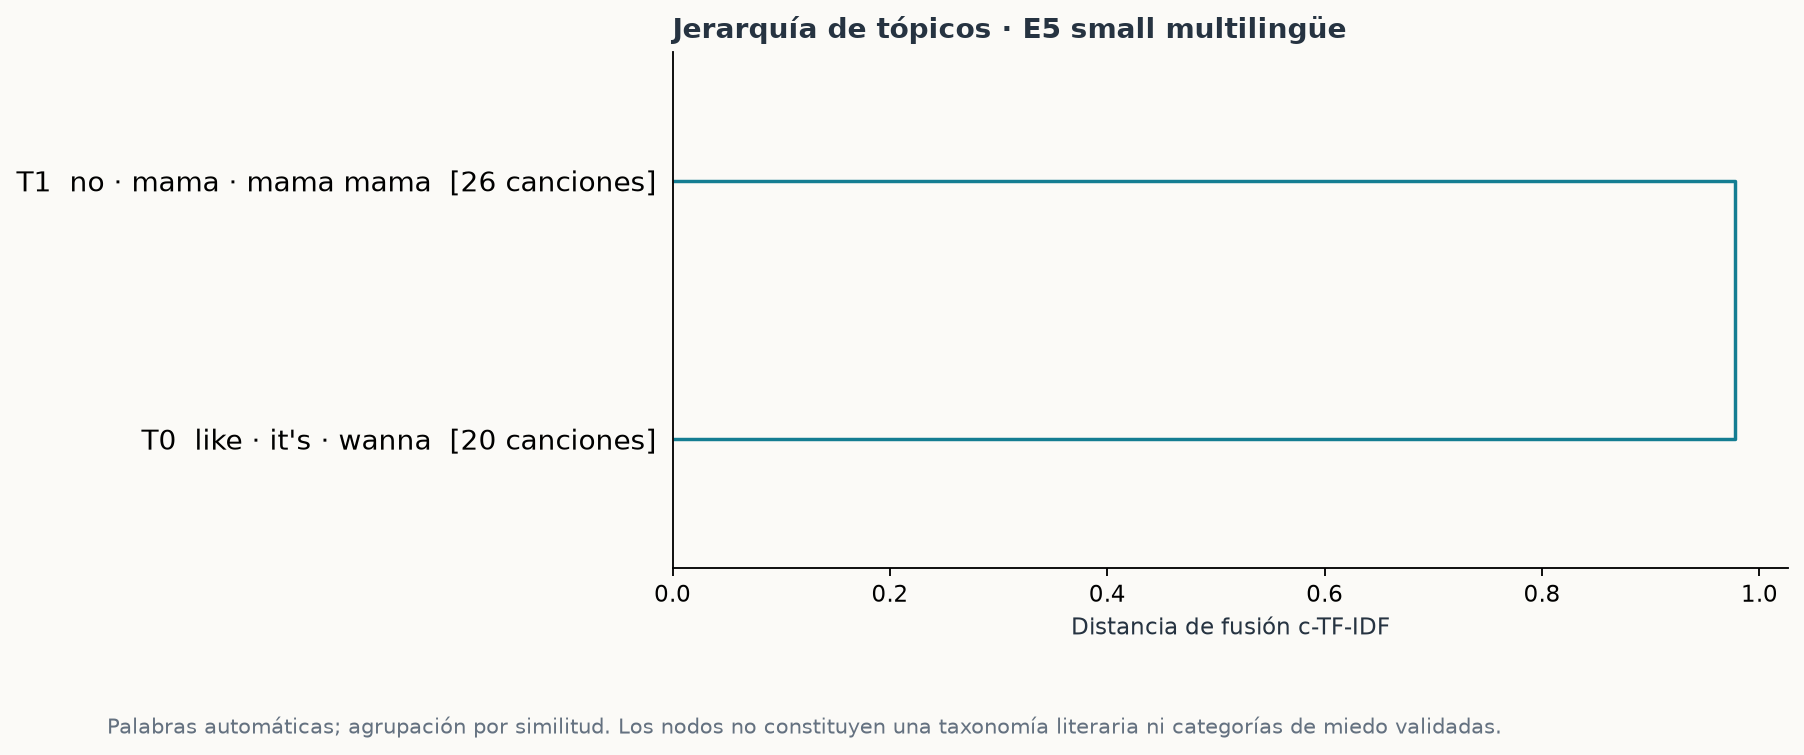

### openai/text-embedding-3-large

,tópico,bloques,canciones,palabras,nombre_propuesto,modelo_lector
0,-1,14,6,hi · problem it's · problem · it's hi · agrees...,,
1,0,173,20,mama mama · mama · no · mal · matador · mu,Dolor amoroso y desvelo,gpt-5.4-mini
2,1,55,13,head · belong · belong together · zombie · wis...,"Malestar, culpa y autoimagen",gpt-5.4-mini
3,2,26,4,thriller · thriller night · night · disturbia ...,Amenaza nocturna y miedo,gpt-5.4-mini
4,3,24,3,crazy · got · looking crazy · got looking · lo...,Amor y euforia desbordada,gpt-5.4-mini
5,4,22,1,shit · hope · slim · about · man · stan,Admiración y reclamo íntimo,gpt-5.4-mini
6,5,17,2,yet · clear · clear yet · woods · yet clear · ...,Recuerdos y ruptura,gpt-5.4-mini
7,6,16,12,bum · bum bum · dum bum · dum · bum dum · doo,Vocalizaciones repetitivas,gpt-5.4-mini
8,7,12,1,watching · always feel · like somebody's · som...,Vigilancia y desconfianza,gpt-5.4-mini
9,8,10,2,never · off never · we're off · never never · ...,Viaje nocturno y advertencia,gpt-5.4-mini


,seed,documents,umap_neighbors,umap_components,umap_min_dist,umap_metric,hdbscan_metric,min_cluster_size,min_samples,cluster_selection_method,ctfidf_reduce_frequent_words,lexical_preprocessing_language,lexical_accents_preserved,ngram_range,topic_reduction,fit_weight
0,17,386,15,5,0.0,cosine,euclidean_in_umap_space,8,3,eom,True,multilingual,True,"[1, 2]",none,one_per_unique_song_block


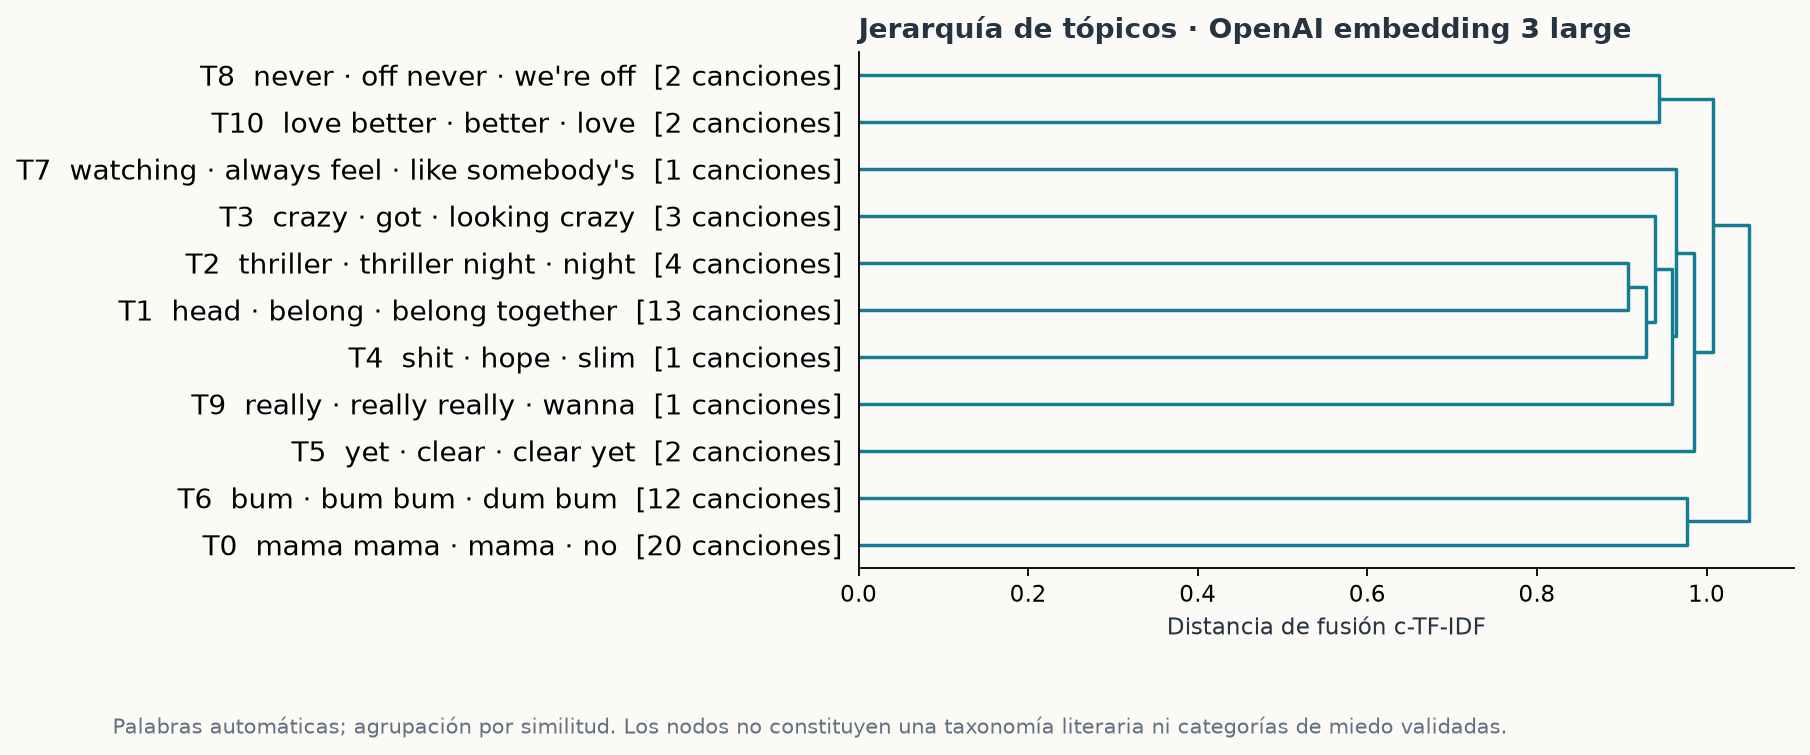

### openai/text-embedding-3-small

,tópico,bloques,canciones,palabras,nombre_propuesto,modelo_lector
0,-1,7,2,negra · tengo · camisa · camisa negra · tengo ...,,
1,0,213,27,like · bum · it's · wanna · now · got,,
2,1,129,18,no · puedo · vida · voy · uh · quiero,,
3,2,16,2,matador · mal · mu · mu mal · mal mu · malamente,,
4,3,13,2,ah ah · luna · ah · niño · hijo · mujer,,
5,4,8,2,mama mama · mama · loi · loi loi · mamá · mamá...,,


,seed,documents,umap_neighbors,umap_components,umap_min_dist,umap_metric,hdbscan_metric,min_cluster_size,min_samples,cluster_selection_method,ctfidf_reduce_frequent_words,lexical_preprocessing_language,lexical_accents_preserved,ngram_range,topic_reduction,fit_weight
0,17,386,15,5,0.0,cosine,euclidean_in_umap_space,8,3,eom,True,multilingual,True,"[1, 2]",none,one_per_unique_song_block


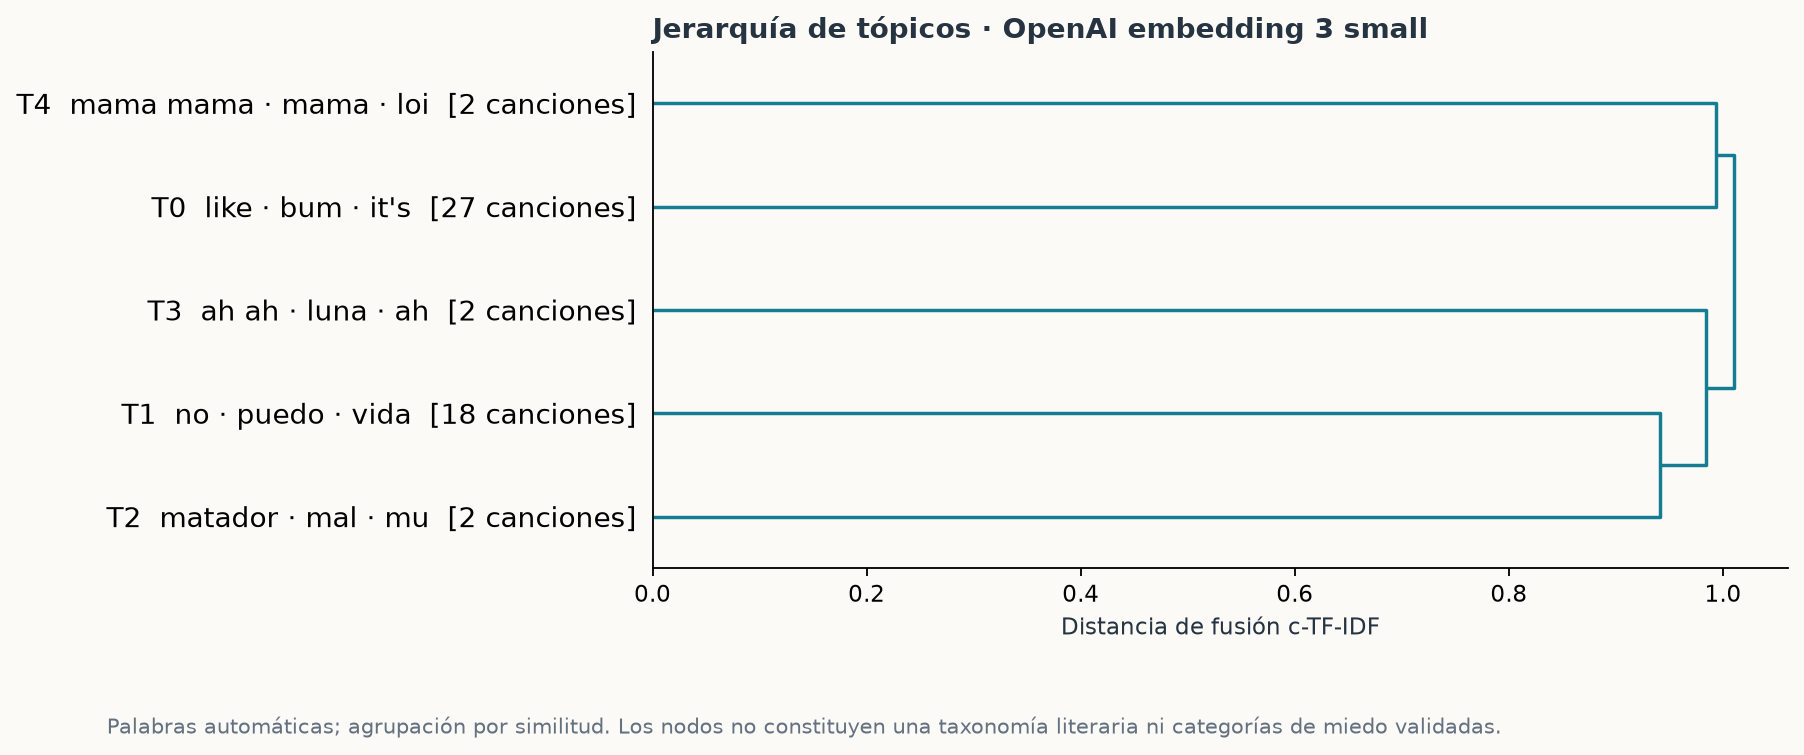

### sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2

,tópico,bloques,canciones,palabras,nombre_propuesto,modelo_lector
0,-1,75,29,muevo · go · mad world · ansiedad · world · mario,,
1,0,31,12,didn't · miedo · shit · verte · no verte · ver...,Temor al abandono amoroso,gpt-5.4-mini
2,1,26,8,thriller · disturbia · thriller thriller · ton...,Tensión nocturna y deseo,gpt-5.4-mini
3,2,21,3,watching · always · always feel · like somebod...,Inseguridad y autojuicio,gpt-5.4-mini
4,3,21,13,mama mama · mama · bum · bum bum · dum · bum dum,Vocalizaciones sin palabras,gpt-5.4-mini
5,4,21,10,never · we're off · off never · never never · ...,Huida hacia lo oscuro,gpt-5.4-mini
6,5,19,5,love better · better · happy · better love · l...,Celebración y autosuficiencia,gpt-5.4-mini
7,6,19,9,luna · ah ah · ah · niño · mujer · hijo,"Noches, deseo y presagios",gpt-5.4-mini
8,7,18,6,really · really really · wanna · voy · hey wan...,"Baile, alegría y cercanía",gpt-5.4-mini
9,8,18,11,saber no · duele · pena · piense · olvida · du...,Dolor amoroso y desahogo,gpt-5.4-mini


,seed,documents,umap_neighbors,umap_components,umap_min_dist,umap_metric,hdbscan_metric,min_cluster_size,min_samples,cluster_selection_method,ctfidf_reduce_frequent_words,ngram_range,topic_reduction,fit_weight,lexical_preprocessing_language,lexical_accents_preserved,descriptor_repair
0,17,386,15,5,0.0,cosine,euclidean_in_umap_space,8,3,eom,True,"[1, 2]",none,one_per_unique_song_block,multilingual,True,Fixed original clustering labels; only multili...


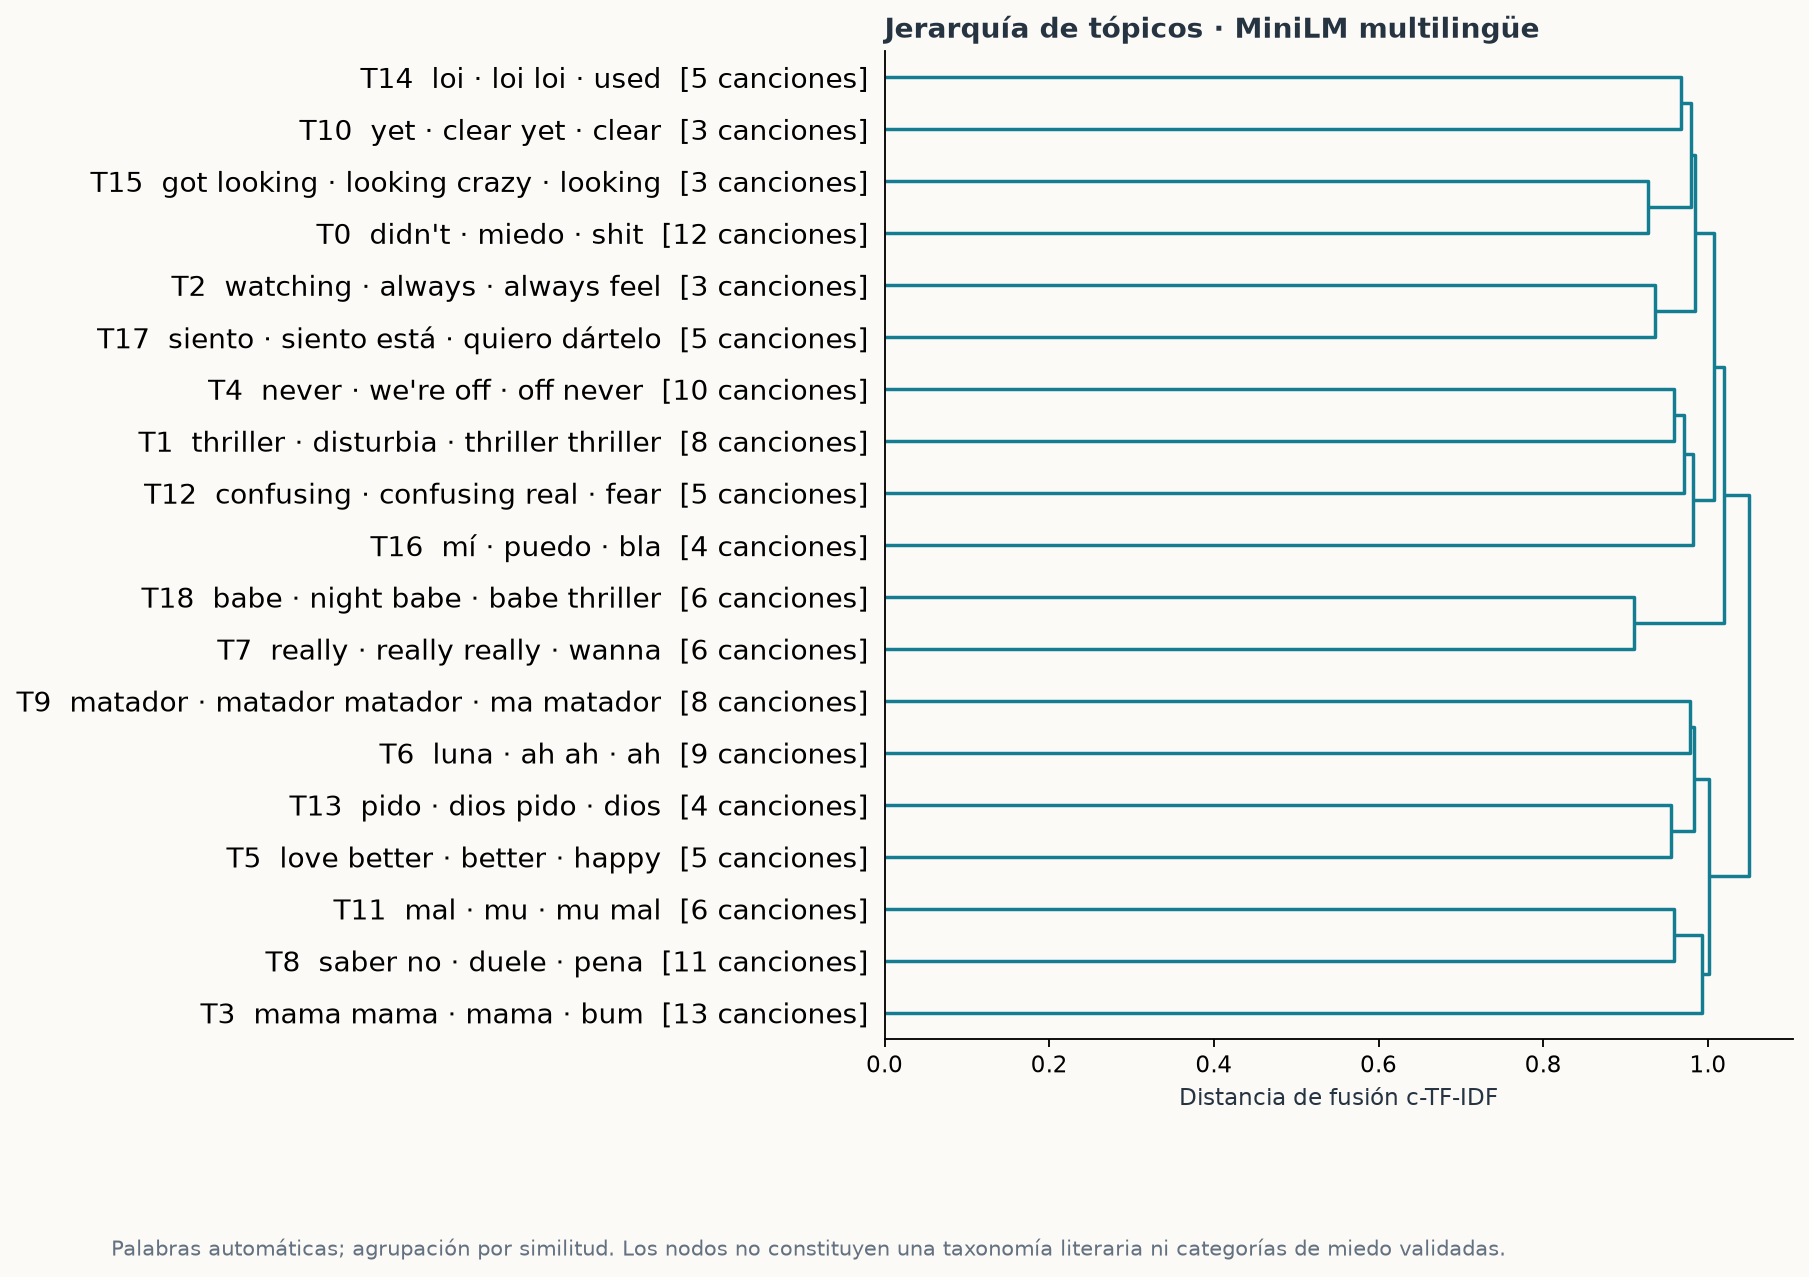

,canción,situación_propuesta,contralectura
0,Thriller,Horror escenificado y amenaza sobrenatural,"No se incorporan el cortometraje, la interpret..."
1,Somebody's Watching Me,Vigilancia cotidiana y pérdida de privacidad,"La instrumentación, los cambios de voz y el hu..."
2,Zombie,"Violencia colectiva, duelo y persistencia del ...",La metáfora del título no debe equipararse a l...
3,Miedo,"Ruptura, culpa y temor a la ausencia o al reen...",Las explicaciones posteriores de los composito...
4,Crawling,Pérdida de control y extrañeza del propio cuerpo,No se leen como evidencia diagnóstica ni la bi...
5,Out Of The Woods,Inseguridad relacional y búsqueda reiterada de...,No se usa el videoclip para decidir la direcci...
6,Malamente,"Presagio adverso, incertidumbre y afirmación d...","Se trata de la letra de esta canción, no del a..."
7,La Puerta Violeta,"Opresión, silencio impuesto y reconstrucción d...",La contextualización pública de la canción com...
8,Color Esperanza,Respuesta al temor mediante exhortación y posi...,La etiqueta de selección fear solo conservó el...
9,Your Power,"Asimetría de poder, vulnerabilidad y responsab...",No se identifica al destinatario con una perso...


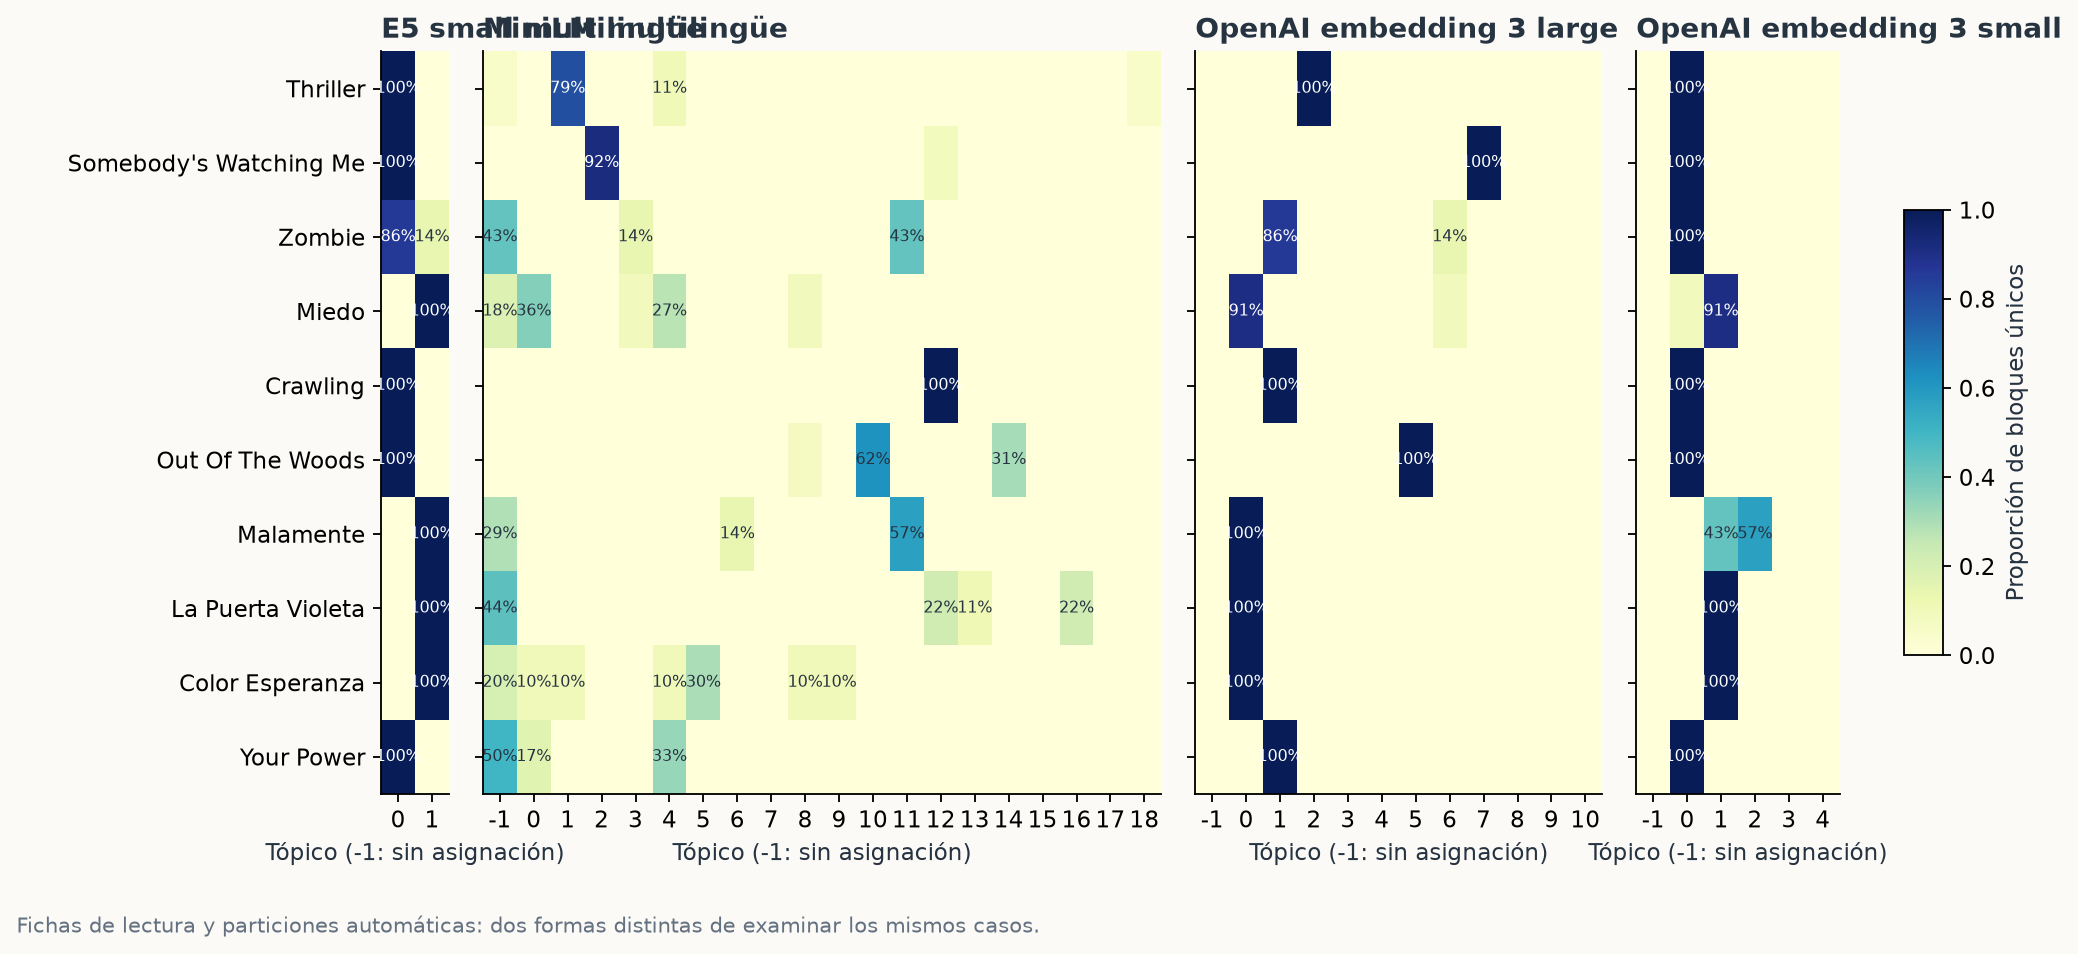

In [6]:
labels = read(RESULTS/'topic_labels.json') if (RESULTS/'topic_labels.json').exists() else []
labels = public_rows(labels)
for directory in modeldirs:
    model_id = model_receipts[directory.name]['encoder']['model_id']
    topic_payload = read(directory/'topics.json')
    names = {int(t['topic_id']):t for t in labels if t.get('model_id') == model_id}
    table = pd.DataFrame([{'tópico':t['topic_id'],'bloques':t['unique_blocks'],'canciones':t['songs'],
        'palabras':' · '.join(x['term'] for x in t['terms'][:6]),
        'nombre_propuesto':names.get(t['topic_id'],{}).get('label',''),
        'modelo_lector':names.get(t['topic_id'],{}).get('labeler_model','')}
        for t in topic_payload['topics']])
    display(Markdown('### '+model_id)); display(table)
    display(pd.DataFrame([topic_payload.get('parameters',{})]))
    if (FIGURES/(directory.name+'-hierarchy.png')).exists(): figure(directory.name+'-hierarchy.png')
cards_path = STUDY/'interpretive-cards.json'
if cards_path.exists():
    cards = read(cards_path)['cards']
    display(pd.DataFrame([{'canción':c['title'],'situación_propuesta':c['proposed_subtopic']['label'],
        'contralectura':c['interpretive_limit']} for c in cards]))
    figure('reading-cases.png')

## 7. Estabilidad, artistas e idioma

El adjusted Rand index describe acuerdo entre semillas sobre los mismos bloques. Se presenta también la fracción asignada en ambas corridas. Un acuerdo alto sobre un único grupo, sobre idioma o sobre ruido necesita lectura de composición.

Las comparaciones entre encoders se hacen con particiones, no con igualdad de IDs. La concentración por artista y la retirada de un artista describen cuánto depende un tópico de unos pocos intérpretes; esa retirada no equivale a reentrenar el clustering.

### intfloat/multilingual-e5-small

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...
1,17,73,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...
2,42,73,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...


,topic_id,artist_hhi,largest_artist,largest_artist_share,contributing_artists,total_song_normalized_mass,limitation
0,0,0.061319,billie eilish,0.104801,18,19.083816,Artist concentration within this selected corp...
1,1,0.064378,mecano,0.095620,22,20.916184,Artist concentration within this selected corp...


### openai/text-embedding-3-large

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,0.946182,0.896373,361,0.935233,0.971119,0.947368,0.036269,0.038860,11,12,High agreement on a single/noise cluster is no...
1,17,73,386,0.942085,0.906736,362,0.937824,0.967595,0.941989,0.036269,0.049223,11,11,High agreement on a single/noise cluster is no...
2,42,73,386,0.942873,0.865285,355,0.919689,0.978205,0.932394,0.038860,0.049223,12,11,High agreement on a single/noise cluster is no...


...

### sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,0.584913,0.766839,288,0.746114,0.791172,0.843750,0.194301,0.196891,19,19,High agreement on a single/noise cluster is no...
1,17,73,386,0.538644,0.769430,303,0.784974,0.750385,0.851485,0.194301,0.121762,19,16,High agreement on a single/noise cluster is no...
2,42,73,386,0.515860,0.730570,297,0.769430,0.797425,0.835017,0.196891,0.121762,19,16,High agreement on a single/noise cluster is no...


,topic_id,artist_hhi,largest_artist,largest_artist_share,contributing_artists,total_song_normalized_mass,limitation
14,13,0.533511,juanes,0.708661,4,1.411111,Artist concentration within this selected corp...
16,15,0.519204,beyoncé feat. jay-z,0.684524,3,0.730435,Artist concentration within this selected corp...
13,12,0.484615,linkin park,0.670290,5,1.491891,Artist concentration within this selected corp...
18,17,0.432958,amaia,0.626947,5,1.329193,Artist concentration within this selected corp...
17,16,0.410845,carla morrison,0.585854,4,1.024145,Artist concentration within this selected corp...
12,11,0.357647,rosalía,0.518655,5,1.583766,Artist concentration within this selected corp...
7,6,0.317995,mecano,0.518129,7,1.930022,Artist concentration within this selected corp...
15,14,0.339725,twenty one pilots,0.512277,5,1.301379,Artist concentration within this selected corp...


,model,diagnostic,nmi_topic_language,documents,interpretation
0,intfloat--multilingual-e5-small,posthoc_language_association,0.863072,386,"Confound diagnostic, not thematic validity."
1,openai--text-embedding-3-large,posthoc_language_association,0.508323,386,"Confound diagnostic, not thematic validity."
2,openai--text-embedding-3-small,posthoc_language_association,0.675559,386,"Confound diagnostic, not thematic validity."
3,sentence-transformers--paraphrase-multilingual...,posthoc_language_association,0.112719,386,"Confound diagnostic, not thematic validity."


,left_model,right_model,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,intfloat--multilingual-e5-small,openai--text-embedding-3-large,386,0.475189,0.590674,372,0.963731,0.508898,0.612903,0.000000,0.036269,2,11,High agreement on a single/noise cluster is no...
1,intfloat--multilingual-e5-small,openai--text-embedding-3-small,386,0.659434,0.841969,379,0.981865,0.682562,0.857520,0.000000,0.018135,2,5,High agreement on a single/noise cluster is no...
2,intfloat--multilingual-e5-small,sentence-transformers--paraphrase-multilingual...,386,0.032632,0.106218,311,0.805699,0.043237,0.131833,0.000000,0.194301,2,19,High agreement on a single/noise cluster is no...
3,openai--text-embedding-3-large,openai--text-embedding-3-small,386,0.231406,0.476684,365,0.945596,0.277370,0.504110,0.036269,0.018135,11,5,High agreement on a single/noise cluster is no...
4,openai--text-embedding-3-large,sentence-transformers--paraphrase-multilingual...,386,0.105848,0.313472,299,0.774611,0.122552,0.397993,0.036269,0.194301,11,19,High agreement on a single/noise cluster is no...
5,openai--text-embedding-3-small,sentence-transformers--paraphrase-multilingual...,386,0.023734,0.155440,308,0.797927,0.038327,0.181818,0.018135,0.194301,5,19,High agreement on a single/noise cluster is no...


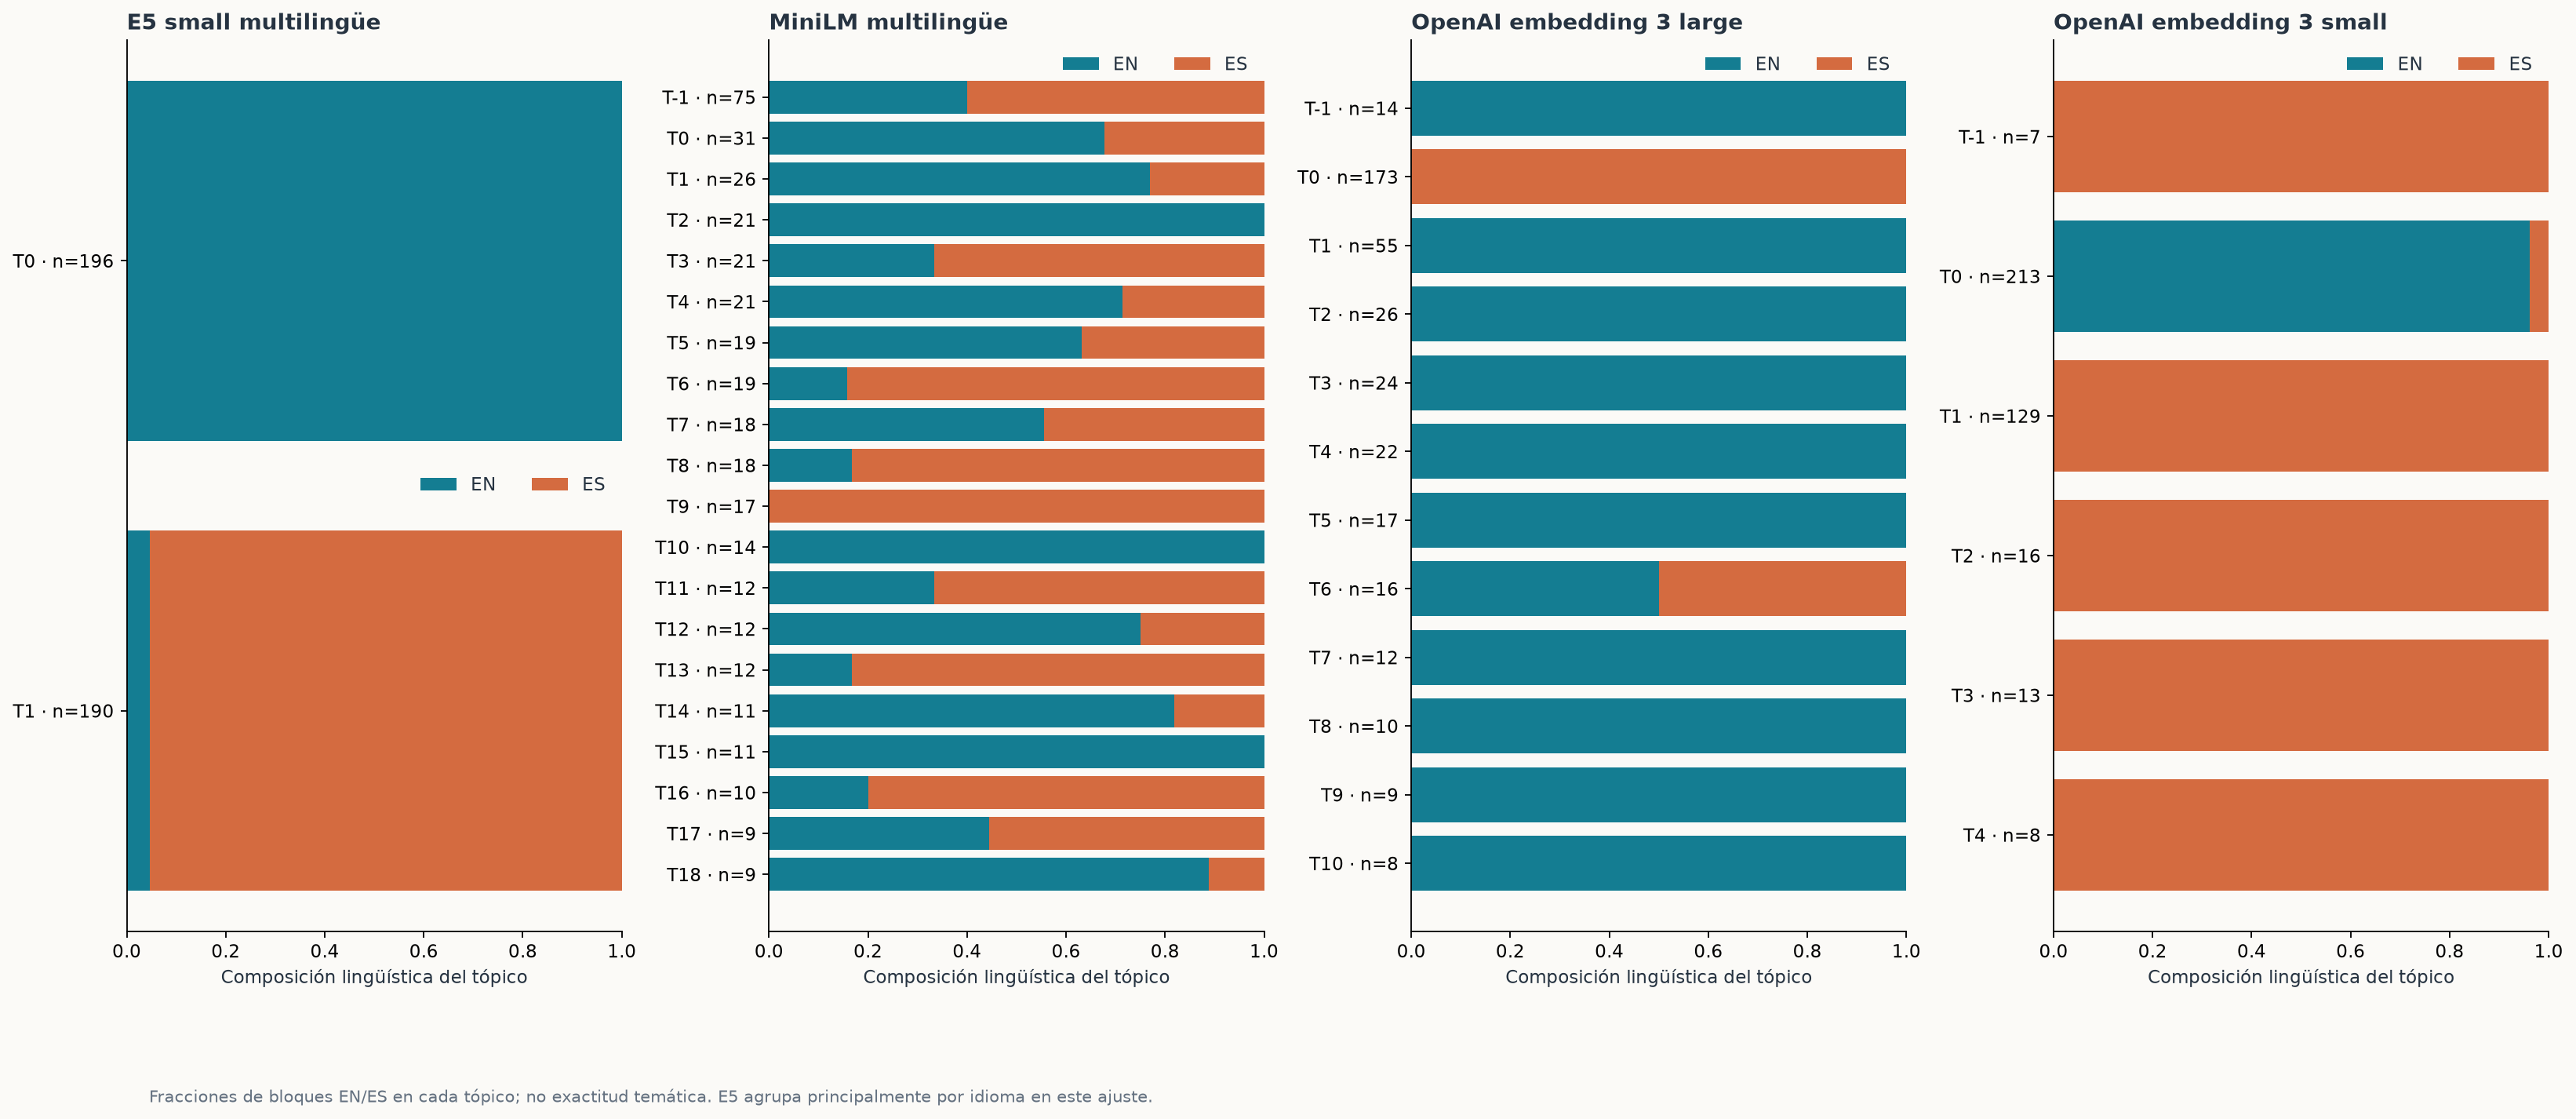

In [7]:
for directory in modeldirs:
    display(Markdown('### '+model_receipts[directory.name]['encoder']['model_id']))
    display(frame(directory/'seed_stability.csv'))
    concentration = frame(directory/'artist_concentration.csv')
    if not concentration.empty: display(concentration.sort_values('largest_artist_share',ascending=False).head(8))
for filename in ['topic_language_association.csv','embedding_model_cluster_agreement.csv']:
    table = frame(RESULTS/filename)
    if not table.empty: display(table)
figure('language-confound.png')

## 8. Proporciones de bloques y presencia de canciones

Las proporciones temporales usan los tópicos globales, con igual peso por canción y luego por idioma. Las curvas representan composición de bloques en los casos seleccionados. Se comparan primera aparición y repeticiones con intervalos bootstrap pareados.

La presencia binaria pregunta algo distinto: ¿cuántas canciones contienen al menos un bloque del tópico? Una canción puede contener varios tópicos; esas tasas no suman uno. El denominador es el número efectivo de canciones de cada celda, que aparece como `k/n`.

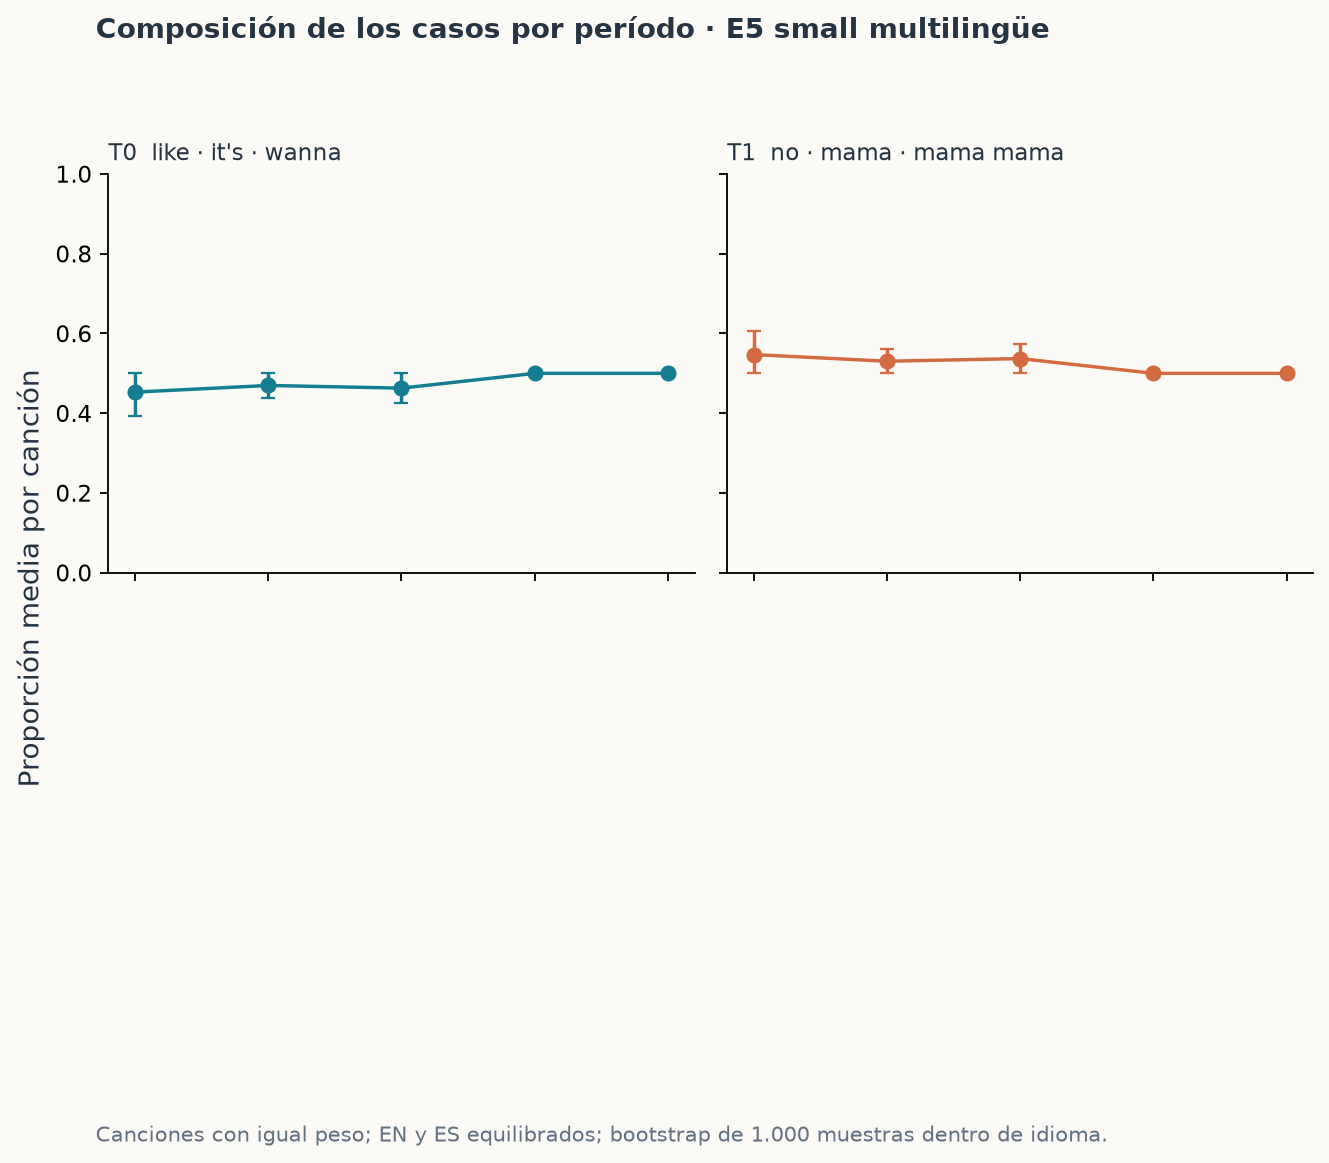

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
12,2000,en,0,0.925824,0.916667,-0.009158,-0.034615,0.007143,True,0.009158
13,2000,en,1,0.074176,0.083333,0.009158,-0.007143,0.034615,True,0.009158
16,2000,balanced_available_languages,0,0.462912,0.458333,-0.004579,-0.017308,0.003571,True,0.004579
17,2000,balanced_available_languages,1,0.537088,0.541667,0.004579,-0.003571,0.017308,True,0.004579
1,1980,en,1,0.094156,0.094231,0.000075,-0.010490,0.010714,True,0.000075


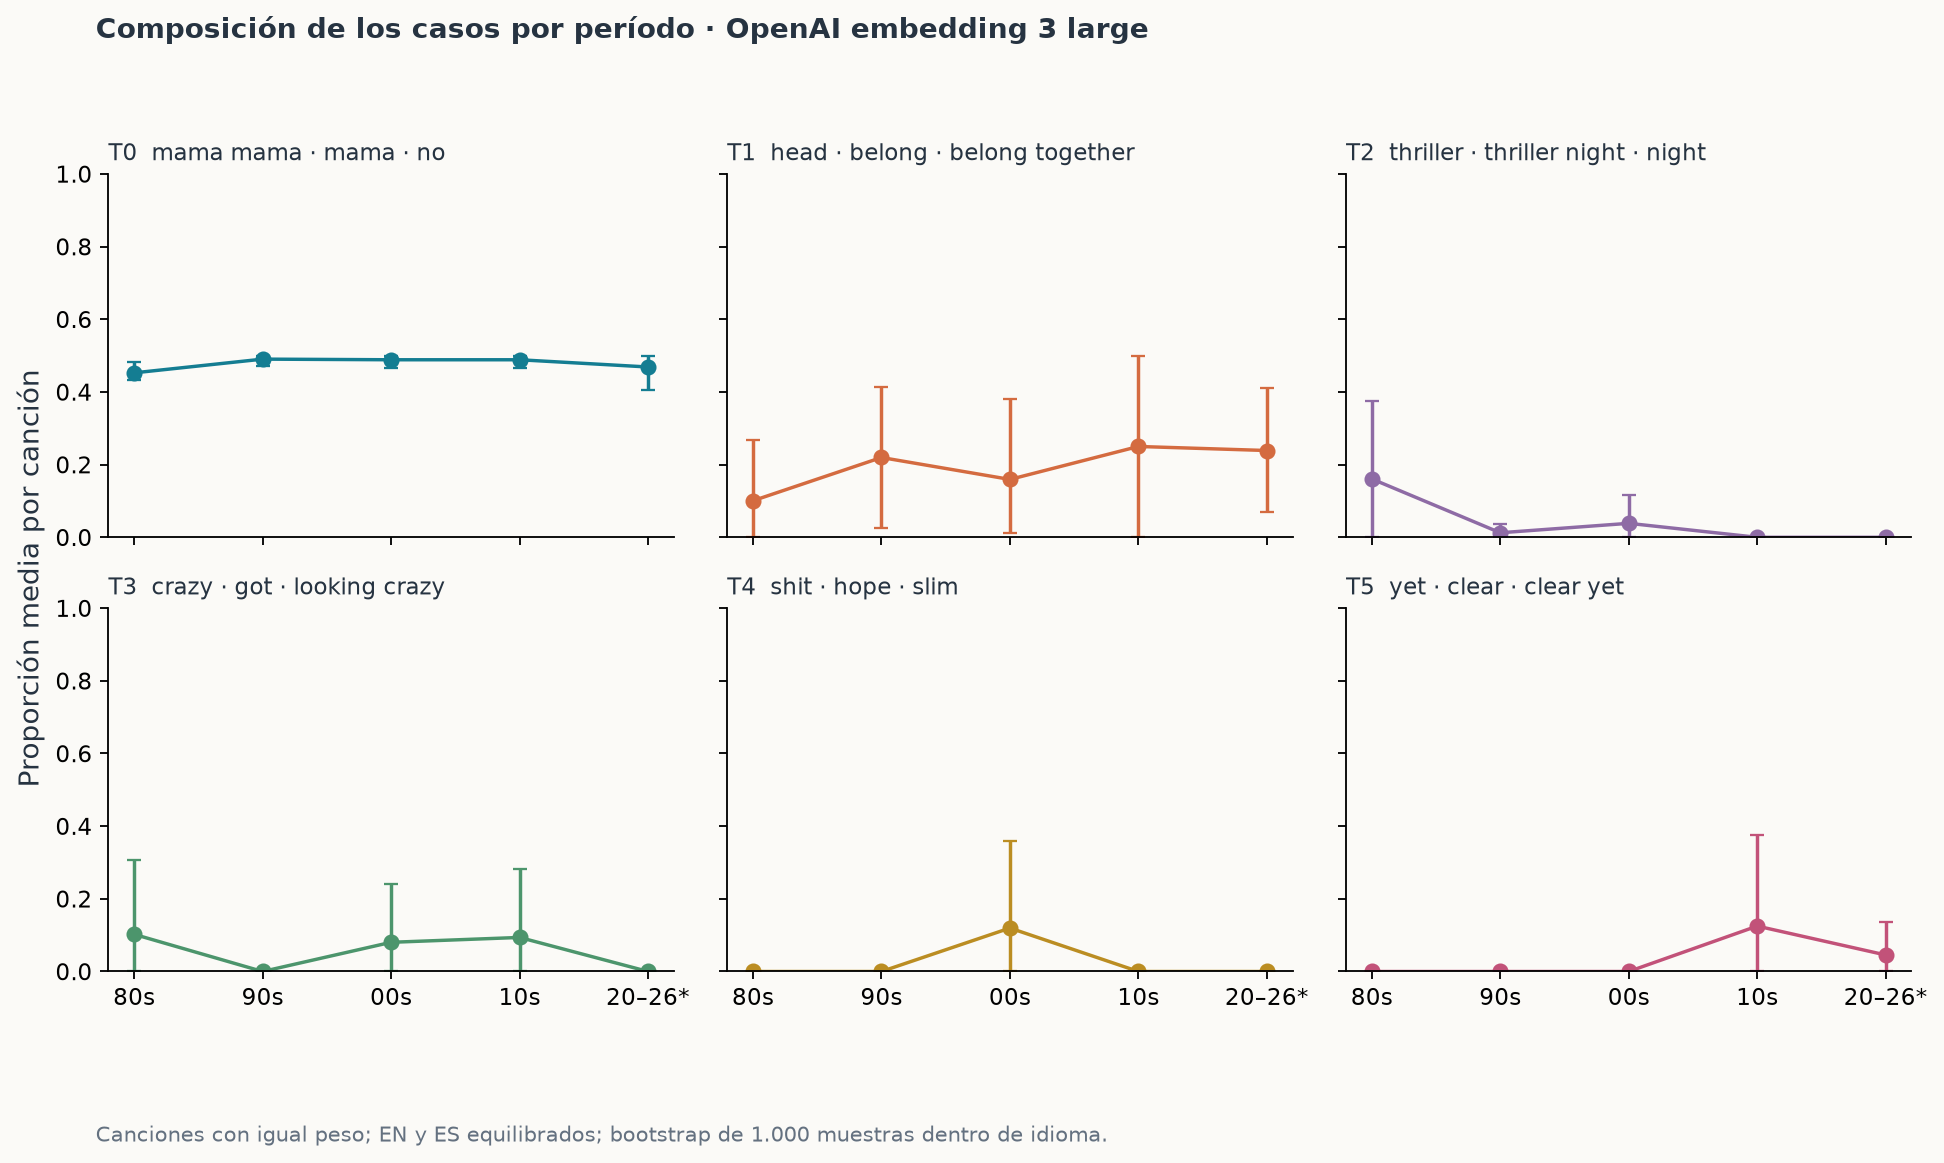

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
77,2000,en,4,0.239130,0.203704,-0.035427,-0.106280,0.000000,True,0.035427
74,2000,en,1,0.318562,0.346296,0.027734,-0.023077,0.106280,True,0.027734
101,2000,balanced_available_languages,4,0.119565,0.101852,-0.017713,-0.053140,0.000000,True,0.017713
19,1980,es,6,0.094742,0.077778,-0.016964,-0.034921,-0.005503,True,0.016964
13,1980,es,0,0.905258,0.922222,0.016964,0.005503,0.034921,True,0.016964


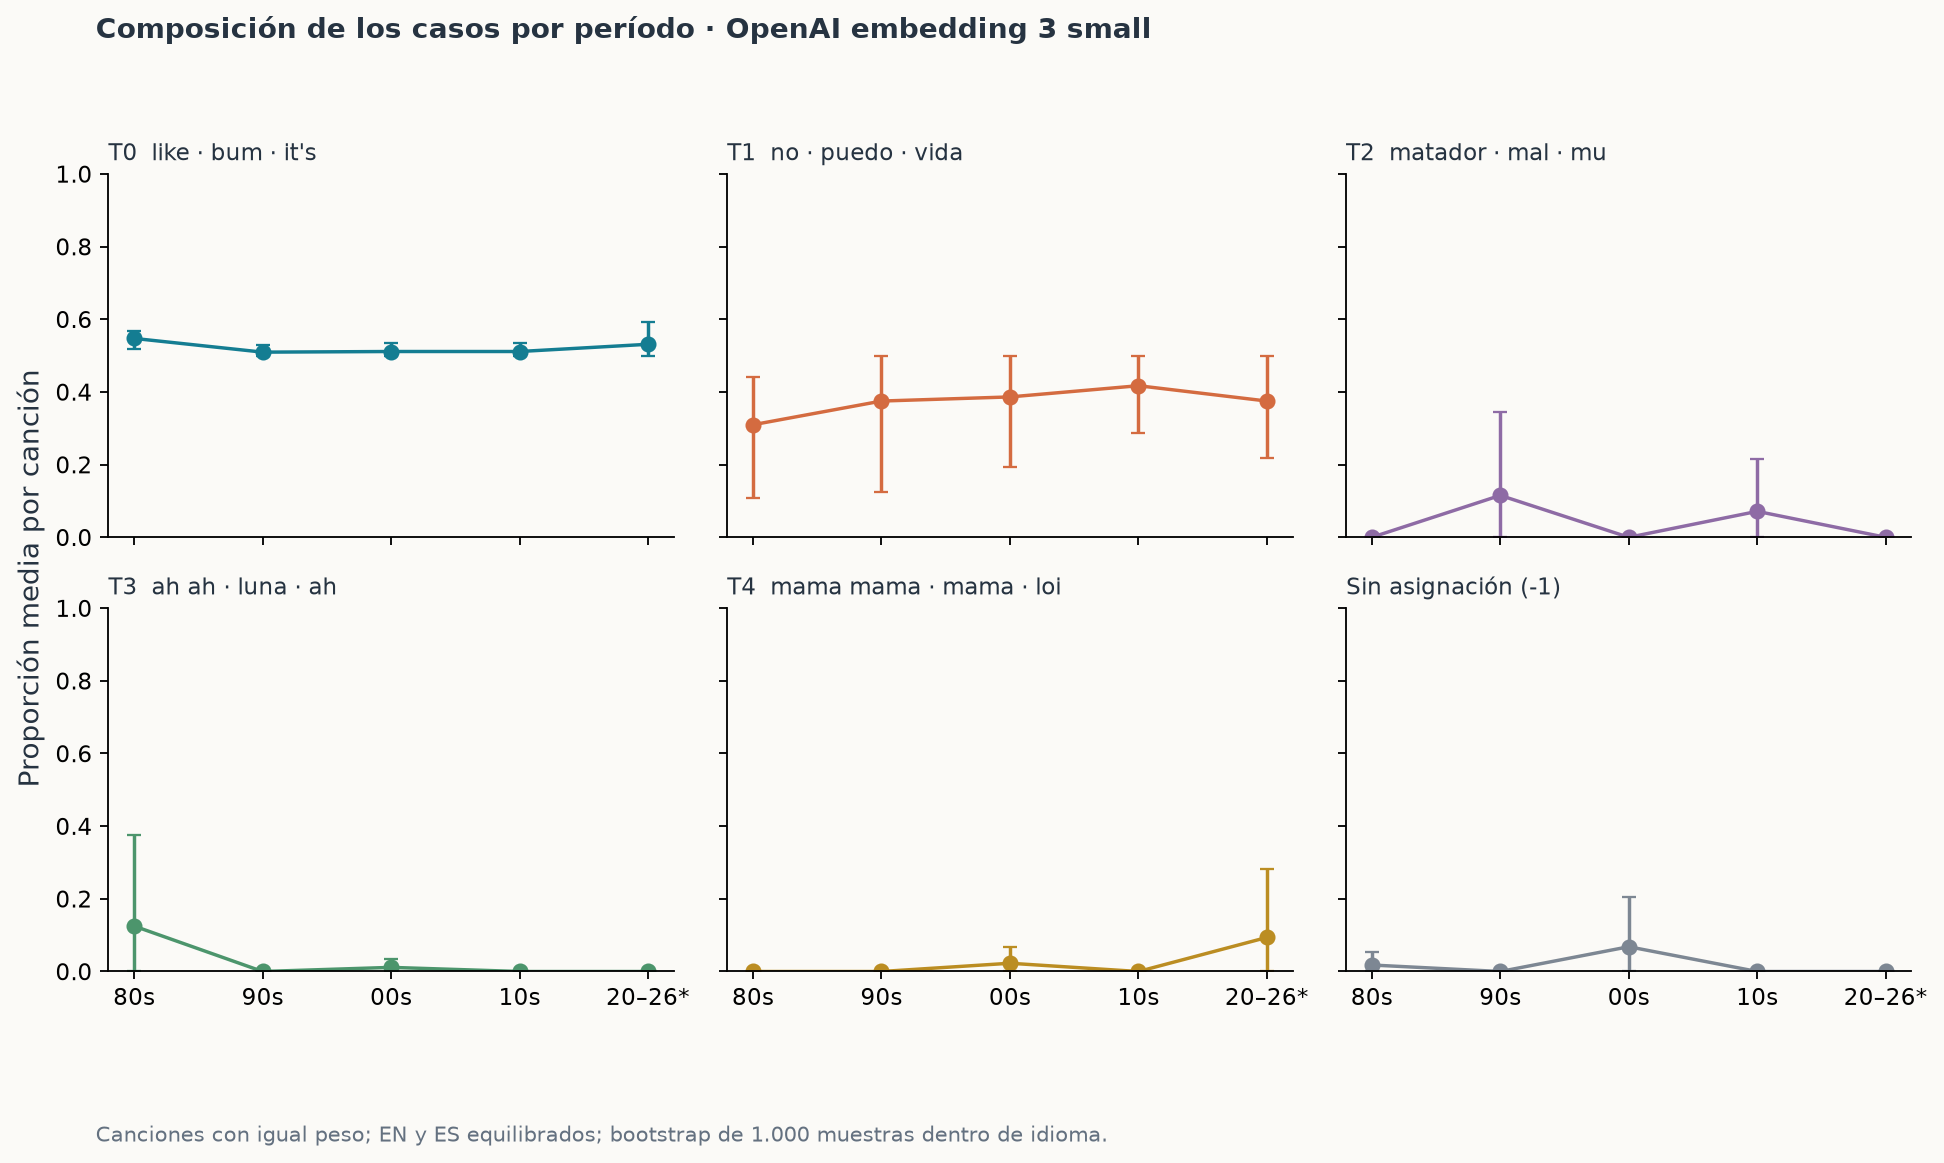

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
7,1980,es,0,0.094742,0.077778,-0.016964,-0.034921,-0.005503,True,0.016964
62,2010,es,1,0.834416,0.817669,-0.016746,-0.050239,0.000000,True,0.016746
61,2010,es,0,0.022727,0.039474,0.016746,0.000000,0.050239,True,0.016746
27,1990,es,2,0.230769,0.214286,-0.016484,-0.049451,0.000000,True,0.016484
25,1990,es,0,0.019231,0.035714,0.016484,0.000000,0.049451,True,0.016484


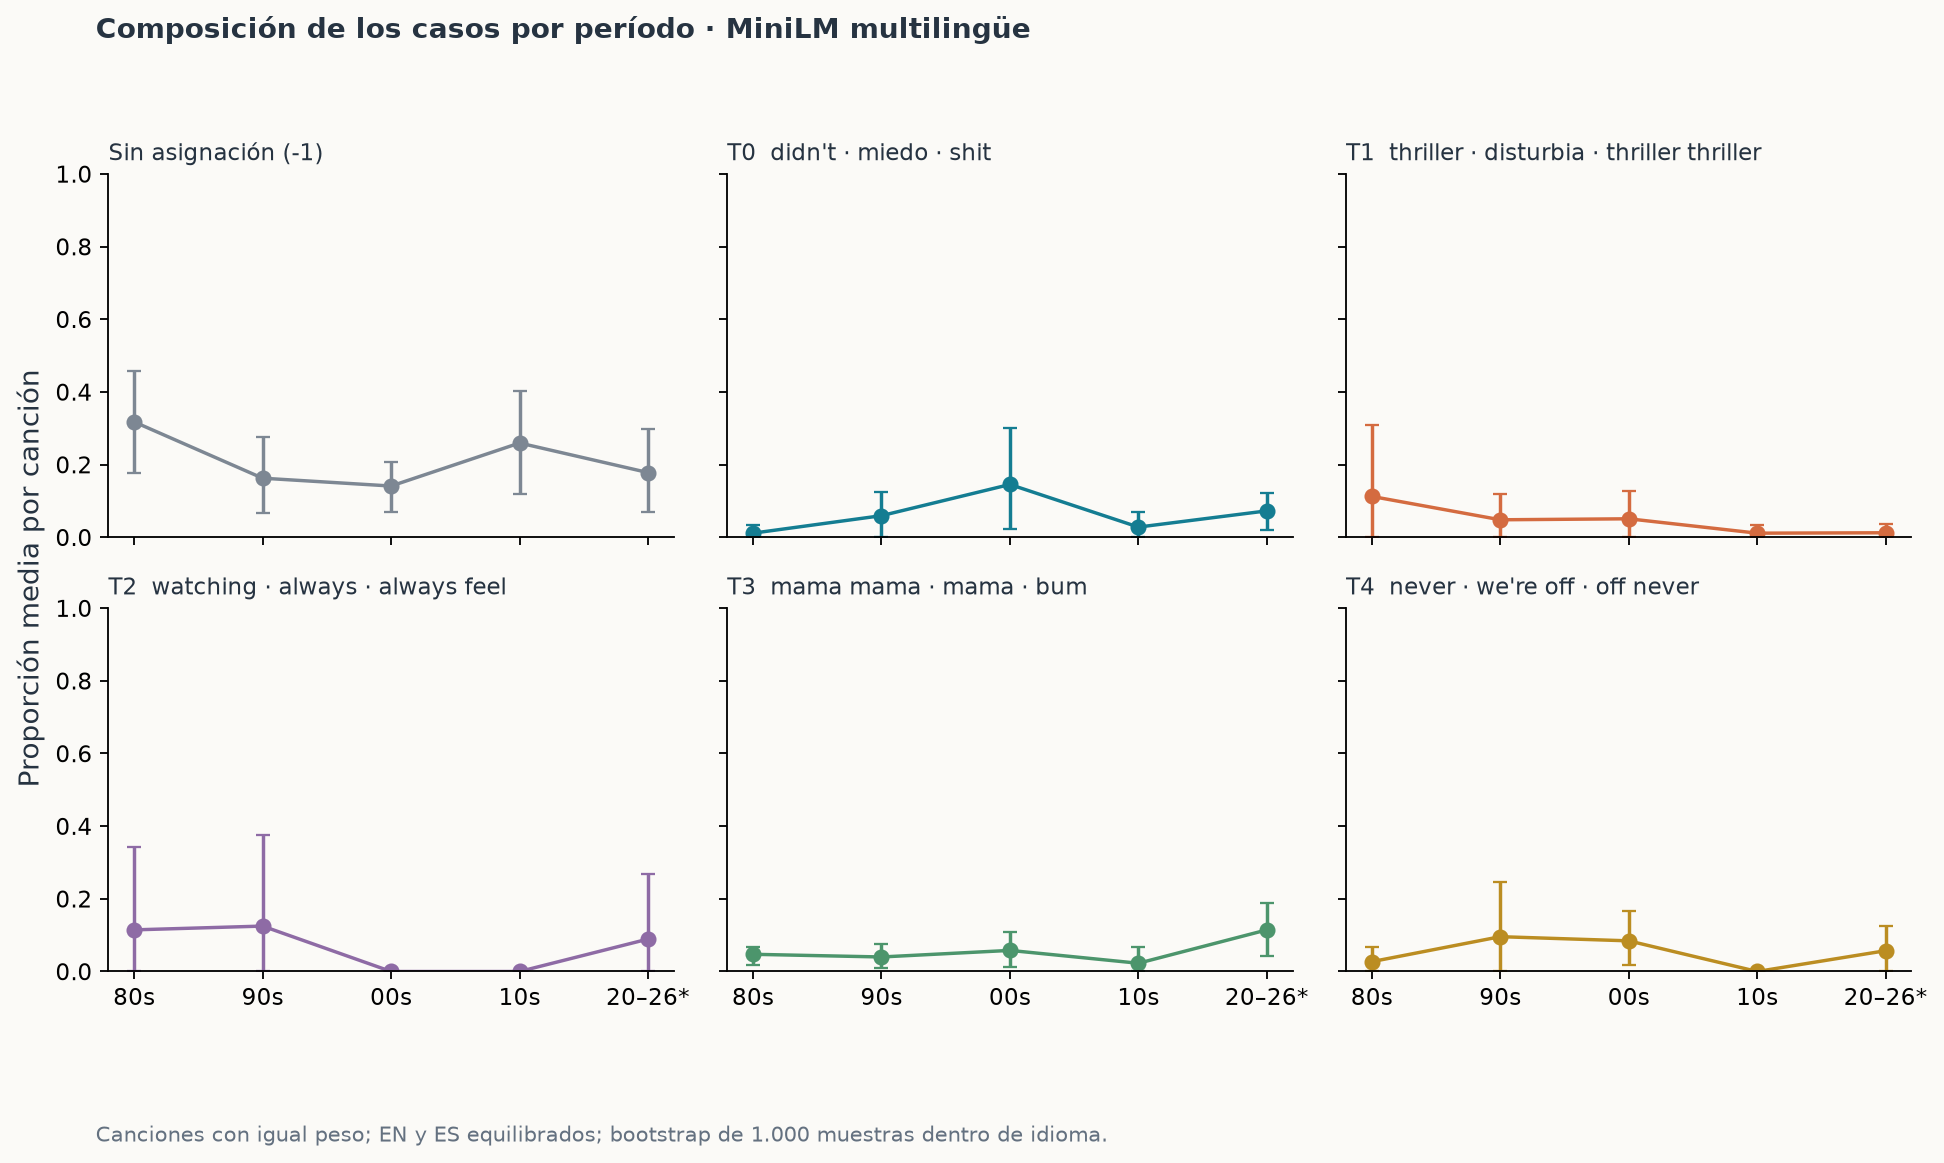

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
140,2000,es,-1,0.186364,0.240833,0.054469,-0.008021,0.171429,True,0.054469
141,2000,es,0,0.138636,0.179845,0.041208,0.000000,0.103571,True,0.041208
160,2000,balanced_available_languages,-1,0.141139,0.181527,0.040388,-0.007802,0.100271,True,0.040388
18,1980,en,17,0.035714,0.075000,0.039286,0.000000,0.117857,True,0.039286
146,2000,es,5,0.075000,0.035714,-0.039286,-0.117857,0.000000,True,0.039286


In [8]:
for directory in modeldirs:
    figure(directory.name+'-decades.png')
    refrains = frame(directory/'repeated_refrain_sensitivity.csv')
    if not refrains.empty:
        display(refrains.assign(magnitud=refrains.repeated_minus_unique.abs()).sort_values('magnitud',ascending=False).head(5))

## 8.1 El contraste bayesiano

[Julia Silge, Bayesian Blues](https://juliasilge.com/blog/bayesian-blues/) inspira la comparación entre tasas observadas, pooling y posteriores. Aquí los ensayos son canciones: `y_g | θ_g ~ Binomial(n_g, θ_g)` y `θ_g ~ Beta(α,β)`. El posterior condicional es `Beta(α+y_g, β+n_g−y_g)`.

Empirical Bayes estima α y β y sus intervalos plug-in condicionan a esa estimación. La integración jerárquica propaga incertidumbre de hiperparámetros bajo hiperpriors explícitos. El protocolo fija priors, límites, resolución e idioma del pooling; se contrastan Jeffreys y uniforme, pooling por idioma, retirada de una celda, perfiles de concentración y resolución numérica.

El gráfico no mezcla esos posteriores con proporciones de bloques. Los resultados condicionan a las asignaciones y al corpus seleccionado. La unidad canción evita contar versos como ensayos independientes, pero no elimina concentración por artista o dependencia de la elección de representación.

,model,topic_id,decade,language,method,prior_context,songs,successes,raw_rate,posterior_mean,credible_low,credible_high,identifiability
1260,intfloat/multilingual-e5-small,1,1980,en,Jeffreys,fixed,4,2,0.5,0.500000,0.122754,0.877246,fixed_prior_not_fitted
1270,intfloat/multilingual-e5-small,1,1980,en,uniform,fixed,4,2,0.5,0.500000,0.146633,0.853367,fixed_prior_not_fitted
1280,intfloat/multilingual-e5-small,1,1980,en,EB_plugin,pooled_languages,4,2,0.5,0.521332,0.126329,0.899472,interior_fit_not_proof_of_identifiability
1281,intfloat/multilingual-e5-small,1,1980,en,hierarchical_grid,pooled_languages,4,2,0.5,0.532163,0.138985,0.895548,interior_fit_not_proof_of_identifiability


**Celda descriptiva:** intfloat/multilingual-e5-small · T1 · 1980s · EN · 2/4 canciones.

Jeffreys (fixed): media **0.500**; intervalo creíble **[0.123, 0.877]**.

uniform (fixed): media **0.500**; intervalo creíble **[0.147, 0.853]**.

EB_plugin (pooled_languages): media **0.521**; intervalo creíble **[0.126, 0.899]**.

hierarchical_grid (pooled_languages): media **0.532**; intervalo creíble **[0.139, 0.896]**.

,model,topic_id,prior_context,successes,songs,main_mu_nodes,main_kappa_nodes,comparison_mu_nodes,comparison_kappa_nodes,mean_absolute_difference,low_absolute_difference,high_absolute_difference
0,sentence-transformers/paraphrase-multilingual-...,0,pooled_languages,0,4,64,81,96,121,3.330669e-16,2.602085e-18,1.831868e-15
1,sentence-transformers/paraphrase-multilingual-...,0,pooled_languages,1,4,64,81,96,121,3.330669e-16,4.857226e-17,2.664535e-15
2,sentence-transformers/paraphrase-multilingual-...,0,pooled_languages,2,4,64,81,96,121,3.330669e-16,4.163336e-17,2.553513e-15
3,sentence-transformers/paraphrase-multilingual-...,0,pooled_languages,3,4,64,81,96,121,3.330669e-16,1.110223e-16,1.776357e-15
4,sentence-transformers/paraphrase-multilingual-...,0,language_en,0,4,64,81,96,121,1.110223e-16,8.456777e-18,3.885781e-15
5,sentence-transformers/paraphrase-multilingual-...,0,language_en,1,4,64,81,96,121,3.330669e-16,6.938894e-17,4.107825e-15
6,sentence-transformers/paraphrase-multilingual-...,0,language_en,3,4,64,81,96,121,5.551115e-16,1.665335e-16,2.553513e-15
7,sentence-transformers/paraphrase-multilingual-...,0,language_es,0,4,64,81,96,121,1.387779e-16,7.453890e-20,1.332268e-15
8,sentence-transformers/paraphrase-multilingual-...,0,language_es,1,4,64,81,96,121,1.665335e-16,0.000000e+00,1.110223e-15
9,sentence-transformers/paraphrase-multilingual-...,0,language_es,2,4,64,81,96,121,1.665335e-16,0.000000e+00,1.110223e-15


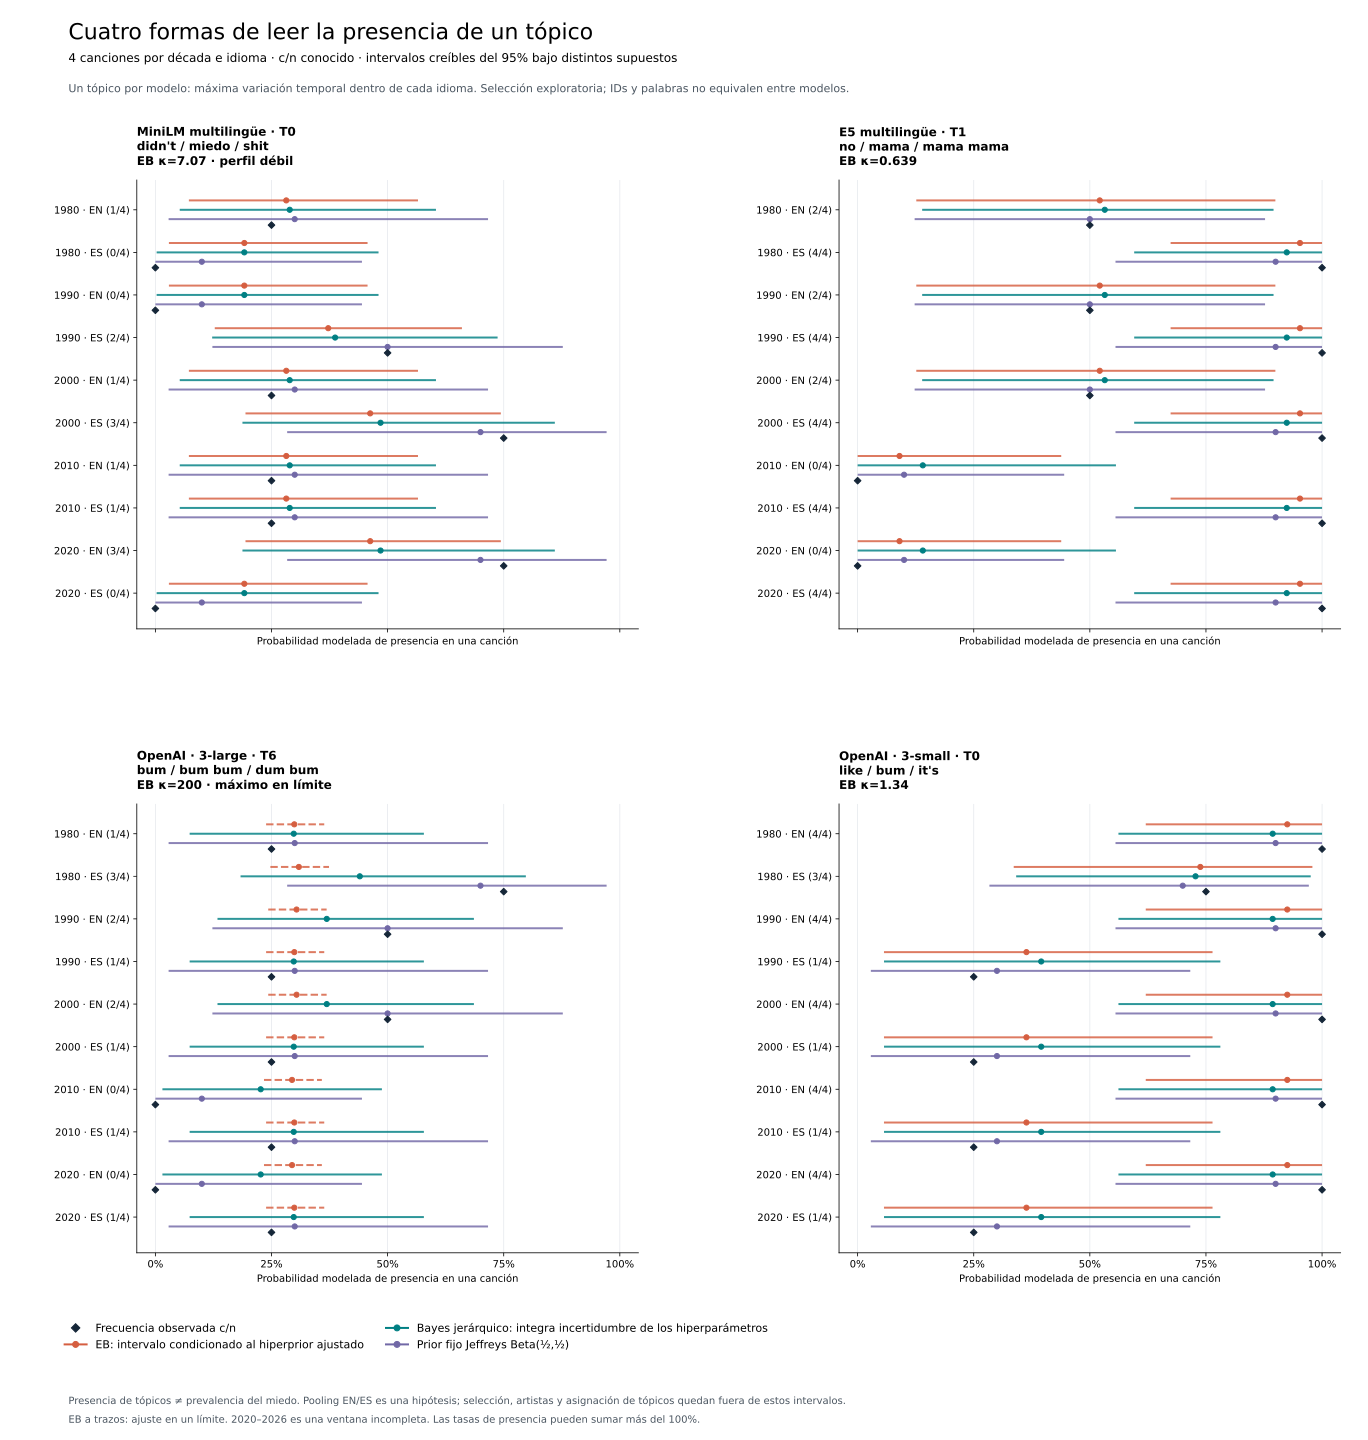

In [9]:
bayesdir = RESULTS/'bayes'
posterior = frame(bayesdir/'posterior_rates.csv')
if not posterior.empty:
    # Regla descriptiva fijada: primera celda intermedia en orden modelo/tópico/período/idioma.
    pooled = posterior[(posterior.method == 'hierarchical_grid') & (posterior.prior_context == 'pooled_languages')]
    intermediate = pooled[(pooled.successes > 0) & (pooled.successes < pooled.songs)]
    candidate = (intermediate if not intermediate.empty else pooled).sort_values(['model','topic_id','decade','language']).iloc[0]
    same = posterior[(posterior.model == candidate.model) & (posterior.topic_id == candidate.topic_id) &
        (posterior.decade == candidate.decade) & (posterior.language == candidate.language) &
        posterior.prior_context.isin(['pooled_languages','fixed'])]
    display(same[['model','topic_id','decade','language','method','prior_context','songs','successes',
                  'raw_rate','posterior_mean','credible_low','credible_high','identifiability']])
    display(Markdown('**Celda descriptiva:** '+candidate.model+' · T'+str(candidate.topic_id)+
        ' · '+str(candidate.decade)+'s · '+candidate.language.upper()+' · '+
        str(candidate.successes)+'/'+str(candidate.songs)+' canciones.'))
    for r in same.itertuples():
        display(Markdown(r.method+' ('+r.prior_context+'): media **'+f'{r.posterior_mean:.3f}'+
            '**; intervalo creíble **'+f'[{r.credible_low:.3f}, {r.credible_high:.3f}]'+ '**.'))
    display(frame(bayesdir/'grid_resolution.csv'))
    figure('beta_binomial_presence.svg')
else: display(Markdown('Esta versión no incluye posteriores guardados.'))

**Lectura del contraste.** Un intervalo plug-in estrecho no recibe más confianza por ser estrecho: condiciona a hiperparámetros estimados. Cambiar de método puede cambiar la media además del intervalo, porque introduce supuestos distintos. Los diagnósticos de límites y sensibilidad se conservan en los archivos. Las bandas no incluyen incertidumbre de selección histórica ni errores de asignación de tópicos.

## 8.2 Qué cambia al ampliar el corpus

La ampliación local se conserva en `expanded/results`. Compara la cohorte común y el corpus completo con los mismos dos encoders locales. Las corridas remotas que no cubren el corpus ampliado no se presentan como resultados de esa cohorte.

Se vuelve a ajustar el clustering y la base PCA sobre todos los bloques de la nueva cohorte. Por eso cambian los IDs de tópicos y los ejes geométricos: T0 y PC1 de una cohorte no se conectan automáticamente con T0 y PC1 de la otra. Comparamos número de grupos, soporte, ruido, idioma y varianza, además de situaciones concretas.

Cohorte ampliada: 120 canciones; 1137 bloques únicos


language,en,es
decade,,
1980,12,12
1990,12,12
2000,12,12
2010,12,12
2020,12,12


,cohorte,modelo,canciones,bloques,tópicos,ruido,varianza_3D,varianza_PC20
0,Común,intfloat/multilingual-e5-small,40,386,2,0,0.191483,0.454719
1,Común,sentence-transformers/paraphrase-multilingual-...,40,386,19,75,0.151645,0.538944
2,Ampliada local,intfloat/multilingual-e5-small,120,1137,28,123,0.168326,0.382562
3,Ampliada local,sentence-transformers/paraphrase-multilingual-...,120,1137,51,350,0.137763,0.479766


**intfloat/multilingual-e5-small**: 2 → 28 tópicos al pasar de 40 a 120 canciones.

**sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2**: 19 → 51 tópicos al pasar de 40 a 120 canciones.

,model,topic_id,decade,language,songs,successes,raw_rate,posterior_mean,credible_low,credible_high
21,sentence-transformers/paraphrase-multilingual-...,-1,1980,en,12,7,0.583333,0.701637,4.617973e-01,0.869136
23,sentence-transformers/paraphrase-multilingual-...,-1,1980,es,12,10,0.833333,0.822121,6.429347e-01,0.949138
25,sentence-transformers/paraphrase-multilingual-...,-1,1990,en,12,12,1.000000,0.902443,7.513145e-01,0.997024
27,sentence-transformers/paraphrase-multilingual-...,-1,1990,es,12,9,0.750000,0.781959,5.825470e-01,0.920945
29,sentence-transformers/paraphrase-multilingual-...,-1,2000,en,12,8,0.666667,0.741798,5.218644e-01,0.893833
...,...,...,...,...,...,...,...,...,...,...
4831,intfloat/multilingual-e5-small,27,2000,es,12,0,0.000000,0.014463,1.701134e-20,0.089616
4833,intfloat/multilingual-e5-small,27,2010,en,12,0,0.000000,0.014463,1.701134e-20,0.089616
4835,intfloat/multilingual-e5-small,27,2010,es,12,0,0.000000,0.014463,1.701134e-20,0.089616
4837,intfloat/multilingual-e5-small,27,2020,en,12,0,0.000000,0.014463,1.701134e-20,0.089616


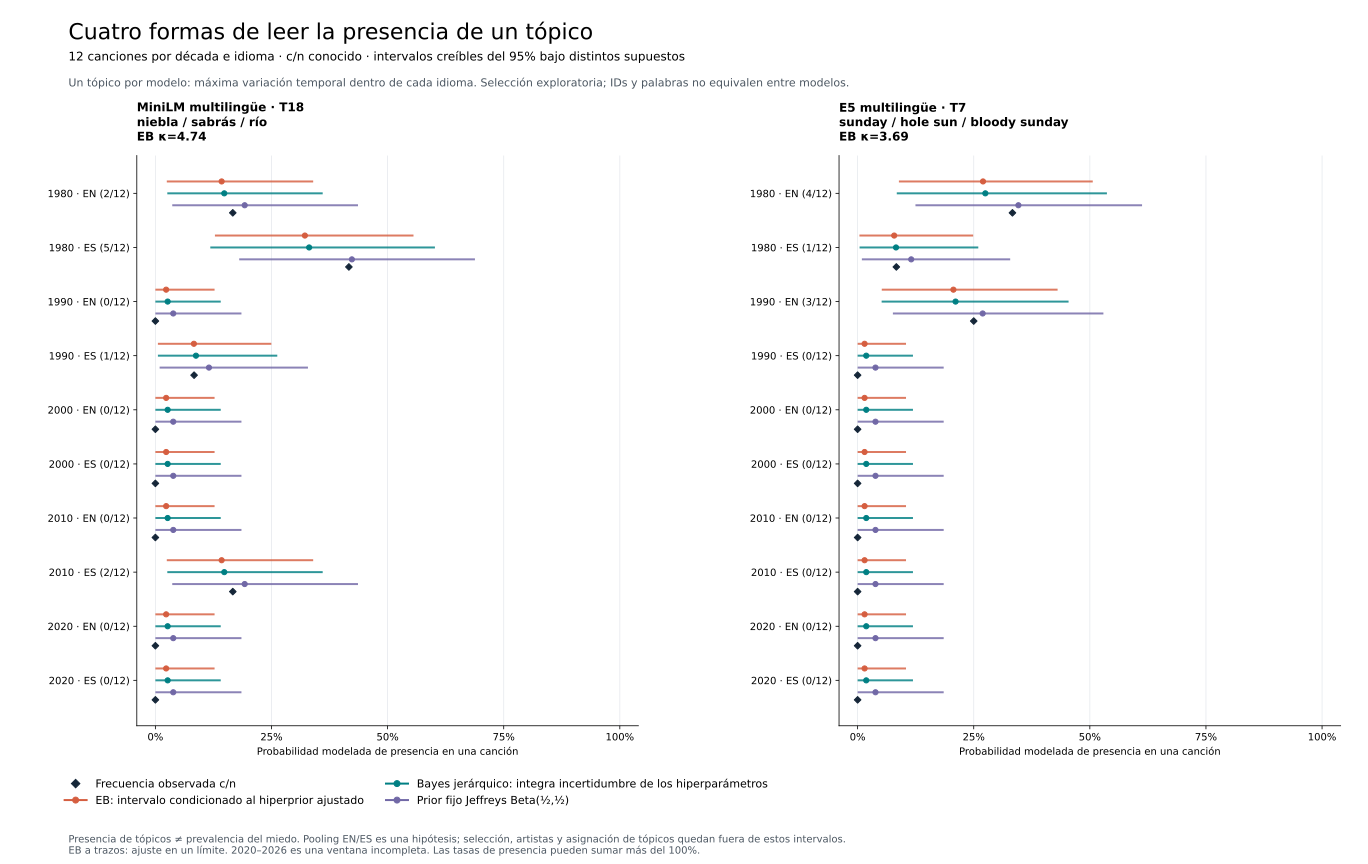

### intfloat/multilingual-e5-small · ampliación

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,1137,0.958404,0.876869,980,0.861917,0.989388,0.927551,0.108179,0.107300,28,30,High agreement on a single/noise cluster is no...
1,17,73,1137,0.959245,0.869833,982,0.863676,0.989634,0.913442,0.108179,0.109059,28,31,High agreement on a single/noise cluster is no...
2,42,73,1137,0.958241,0.898857,970,0.853122,0.997511,0.972165,0.107300,0.109059,30,31,High agreement on a single/noise cluster is no...


### sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 · ampliación

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,1137,0.452433,0.742304,699,0.614776,0.847695,0.879828,0.307828,0.278804,51,55,High agreement on a single/noise cluster is no...
1,17,73,1137,0.506911,0.754617,702,0.617414,0.877544,0.867521,0.307828,0.293755,51,49,High agreement on a single/noise cluster is no...
2,42,73,1137,0.554111,0.770449,733,0.644679,0.818958,0.858117,0.278804,0.293755,55,49,High agreement on a single/noise cluster is no...


,experimento,method,arm,language,recall_at_5,context_support_recall,negative_safe_abstention_rate
2,rag,bm25,bounded_contextual,en,0.270833,0.375000,0.50
3,rag,bm25,bounded_contextual,es,0.520833,0.416667,0.50
6,rag,bm25,one_pass,en,0.270833,0.270833,0.75
7,rag,bm25,one_pass,es,0.375000,0.375000,0.75
10,rag,dense,bounded_contextual,en,0.604167,0.375000,0.50
11,rag,dense,bounded_contextual,es,0.645833,0.333333,0.50
14,rag,dense,one_pass,en,0.520833,0.270833,1.00
15,rag,dense,one_pass,es,0.562500,0.250000,1.00
18,rag,hybrid,bounded_contextual,en,0.437500,0.375000,0.50
19,rag,hybrid,bounded_contextual,es,0.645833,0.500000,0.50


In [10]:
if expanded_modeldirs:
    expanded_diag = read(EXPANDED_RESULTS/'corpus_diagnostics.json')
    expanded_inventory = frame(EXPANDED_RESULTS/'section_inventory.csv')
    expanded_ids = set(expanded_inventory.song_id)
    expanded_manifest = full_manifest[full_manifest.song_id.isin(expanded_ids)]
    print('Cohorte ampliada:',len(expanded_manifest),'canciones;',expanded_diag['unique_blocks'],'bloques únicos')
    display(expanded_manifest.groupby(['decade','language']).size().unstack(fill_value=0))
    comparison_rows = []
    for name, cohort_dirs, cohort_diag in [('Común',modeldirs,diag),('Ampliada local',expanded_modeldirs,expanded_diag)]:
        for directory in cohort_dirs:
            receipt = read(directory/'model_manifest.json'); encoder = receipt['encoder']
            if name == 'Común' and not any(read(p/'model_manifest.json')['encoder']['model_id']==encoder['model_id'] for p in expanded_modeldirs): continue
            topics = read(directory/'topics.json')['topics']
            projection = read(directory/'projections.json')['receipt'] if (directory/'projections.json').exists() else {}
            comparison_rows.append({'cohorte':name,'modelo':encoder['model_id'],
                'canciones':cohort_diag['songs_with_lyrics'],'bloques':receipt['unique_documents'],
                'tópicos':sum(t['topic_id']!=-1 for t in topics),
                'ruido':sum(t['unique_blocks'] for t in topics if t['topic_id']==-1),
                'varianza_3D':projection.get('explained_variance_total'),
                'varianza_PC20':sum(projection.get('scree_explained_variance_ratio',[]))})
    cohort_comparison = pd.DataFrame(comparison_rows)
    display(cohort_comparison)
    for model_id, group in cohort_comparison.groupby('modelo'):
        before = group[group.cohorte.eq('Común')].iloc[0]; after = group[group.cohorte.eq('Ampliada local')].iloc[0]
        display(Markdown('**'+model_id+'**: '+str(before['tópicos'])+' → '+str(after['tópicos'])+
            ' tópicos al pasar de '+str(before['canciones'])+' a '+str(after['canciones'])+' canciones.'))
    expanded_bayes = frame(EXPANDED_RESULTS/'bayes/posterior_rates.csv')
    if not expanded_bayes.empty:
        display(expanded_bayes[expanded_bayes.method.eq('hierarchical_grid') &
            expanded_bayes.prior_context.eq('pooled_languages')][['model','topic_id','decade','language',
            'songs','successes','raw_rate','posterior_mean','credible_low','credible_high']])
    expanded_bayes_figure = EXPANDED_RESULTS/'bayes/beta_binomial_presence.svg'
    if expanded_bayes_figure.exists(): display(SVG(filename=str(expanded_bayes_figure)))
    for directory in expanded_modeldirs:
        table = frame(directory/'seed_stability.csv')
        display(Markdown('### '+read(directory/'model_manifest.json')['encoder']['model_id']+' · ampliación'))
        display(table)
    expanded_retrieval = []
    for path in sorted(EXPANDED_RESULTS.glob('rag*/summary.csv')):
        table = frame(path)
        if not table.empty: expanded_retrieval.append(table.assign(experimento=path.parent.name))
    if expanded_retrieval:
        table = pd.concat(expanded_retrieval,ignore_index=True)
        display(table[table.split.eq('test')][[c for c in ['experimento','method','arm','language',
            'recall_at_5','context_support_recall','negative_safe_abstention_rate'] if c in table]])
else: display(Markdown('Esta edición incluye únicamente la cohorte común.'))

## 9. Del perfil semántico al arco narrativo

Las curvas usan cuatro prototipos bilingües originales: miedo, amenaza, evitación y afrontamiento. El contraste `afrontamiento − (miedo + amenaza) / 2` es geométrico; su pendiente no mide intensidad emocional. Se comparan posiciones relativas de bloques, sin duración de audio.

La permutación de orden mantiene textos y prototipos y cambia su secuencia. Los valores p se ajustan por Benjamini–Hochberg dentro de cada variante. El resultado informa sobre esa representación; no demuestra por sí solo una trama. Las [formas afectivas de Reagan y colaboradores](https://link.springer.com/article/10.1140/epjds/s13688-016-0093-1) se estudiaron en libros extensos: dominio, extensión y unidad son distintos aquí.

[EmotionArcs (2024)](https://aclanthology.org/2024.latechclfl-1.7/) estudia trayectorias en novelas; [Social Story Frames (2026)](https://aclanthology.org/2026.acl-long.1934/) aborda marcos interpretativos de relatos sociales. Estos trabajos motivan distinguir situaciones, inferencias y trayectorias. Sus dominios y unidades difieren de una letra breve y repetitiva; sus resultados no validan el método sobre este corpus de canciones.

Dos lectores OpenAI examinan de forma separada bloques anónimos y ordenados, sin título, artista, año ni hipótesis de selección. Una tercera lectura de mini, acotada a desacuerdos predeclarados, reutiliza un modelo del panel; no es un tercer modelo independiente. El panel examina situaciones, voces, cambios de postura y contralecturas con evidencia por ID. El reconocimiento de letras conocidas sigue siendo posible aunque se omitan metadatos. Una distribución de votos muestra acuerdo o discrepancia entre los lectores automáticos; no convierte una curva semántica en arco narrativo.

La corrida primaria conserva su validación conjunta de categorías, IDs y cronología. El diagnóstico **posterior por campo**, calculado sin nuevas llamadas, separa validez de tipo/enum de cada categoría y validez de los anclajes argumentales. Una respuesta que falla cronología puede aportar un voto categórico de voz o situación; su arco sigue excluido. Los resultados primarios y esta lectura posterior aparecen en tablas separadas. La mayoría expresa acuerdo entre estos lectores y no exactitud semántica.

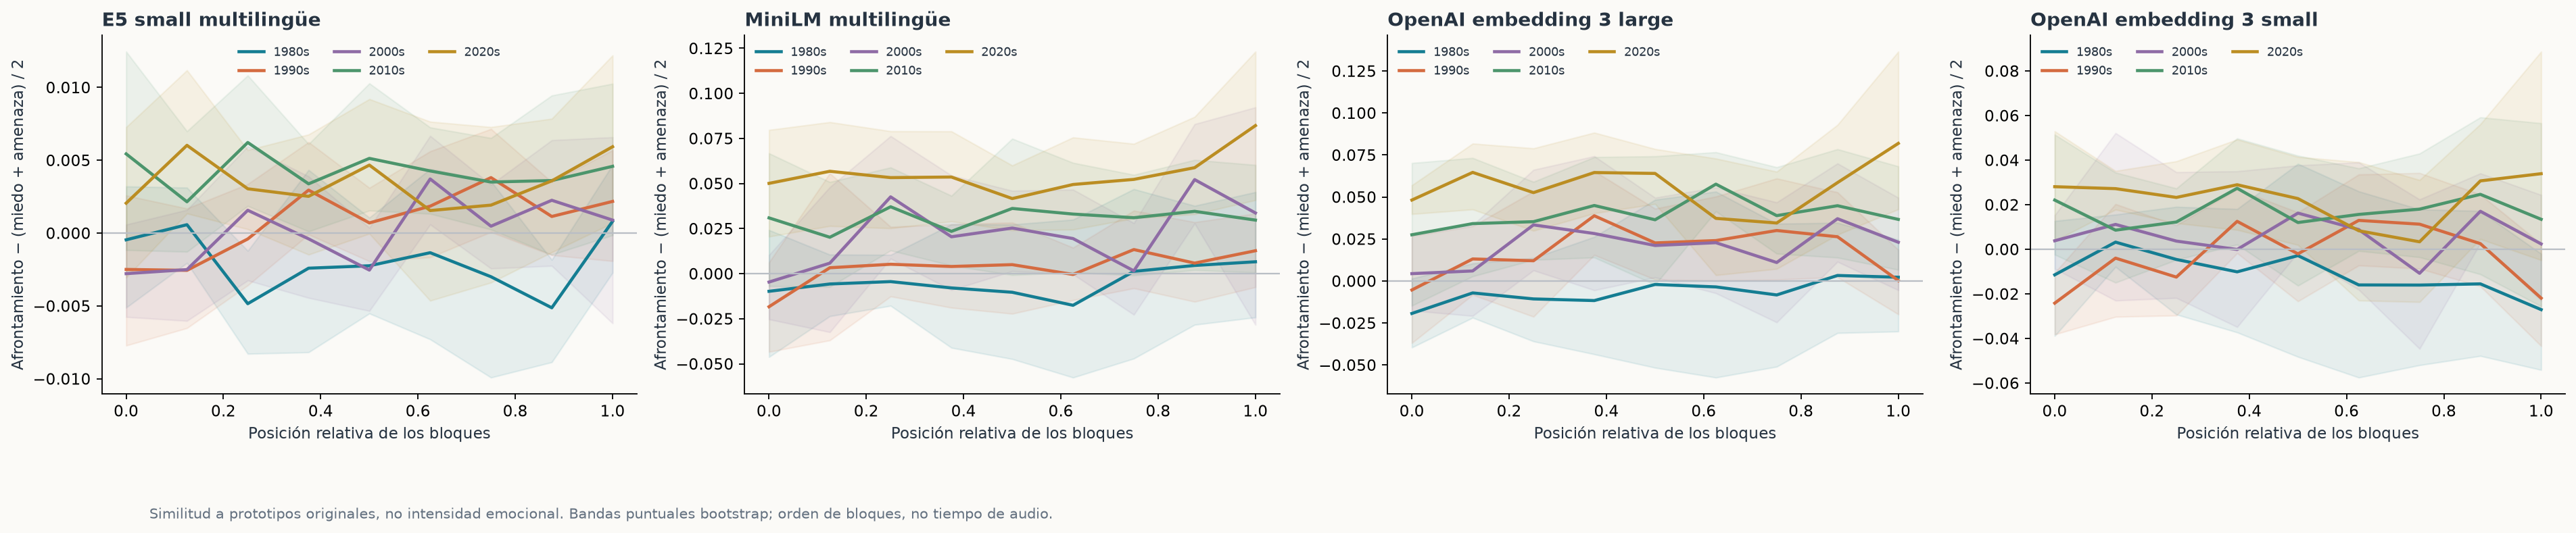

### intfloat/multilingual-e5-small

,variant,group,songs,languages_present,mean_order_slope,shuffled_mean,shuffled_ci_low,shuffled_ci_high,permutation_p_two_sided,weighting,inference,permutation_q_bh_within_variant
0,unique_first_occurrence,all_selected_songs,40,2,0.001855,-0.000017,-0.002163,0.002186,0.097902,equal_language_then_equal_song,Tests section order against exchangeability co...,0.195804
1,unique_first_occurrence,1980,8,2,-0.000681,-0.000082,-0.005314,0.005145,0.810190,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
2,unique_first_occurrence,1990,8,2,0.004850,-0.000065,-0.005010,0.004580,0.047952,equal_language_then_equal_song,Tests section order against exchangeability co...,0.170829
3,unique_first_occurrence,2000,8,2,0.004667,0.000066,-0.004618,0.004920,0.056943,equal_language_then_equal_song,Tests section order against exchangeability co...,0.170829
4,unique_first_occurrence,2010,8,2,-0.000328,-0.000014,-0.004140,0.004000,0.884116,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
5,unique_first_occurrence,2020,8,2,0.000766,0.000012,-0.005765,0.005952,0.817183,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
6,all_blocks_with_repeats,all_selected_songs,40,2,0.002137,0.000031,-0.002244,0.002026,0.051948,equal_language_then_equal_song,Tests section order against exchangeability co...,0.103896
7,all_blocks_with_repeats,1980,8,2,-0.001235,0.000039,-0.004648,0.004645,0.624376,equal_language_then_equal_song,Tests section order against exchangeability co...,0.798402
8,all_blocks_with_repeats,1990,8,2,0.005403,0.000043,-0.005080,0.004859,0.033966,equal_language_then_equal_song,Tests section order against exchangeability co...,0.101898
9,all_blocks_with_repeats,2000,8,2,0.005066,-0.000062,-0.004159,0.004243,0.019980,equal_language_then_equal_song,Tests section order against exchangeability co...,0.101898


,canciones,q_menor_005
variant,,
all_blocks_with_repeats,40,0
unique_first_occurrence,40,0


### openai/text-embedding-3-large

,variant,group,songs,languages_present,mean_order_slope,shuffled_mean,shuffled_ci_low,shuffled_ci_high,permutation_p_two_sided,weighting,inference,permutation_q_bh_within_variant
0,unique_first_occurrence,all_selected_songs,40,2,0.014766,-0.000013,-0.011404,0.011441,0.017982,equal_language_then_equal_song,Tests section order against exchangeability co...,0.107892
1,unique_first_occurrence,1980,8,2,0.017962,-0.000417,-0.026890,0.024626,0.184815,equal_language_then_equal_song,Tests section order against exchangeability co...,0.369630
2,unique_first_occurrence,1990,8,2,0.012341,0.000104,-0.025218,0.025447,0.342657,equal_language_then_equal_song,Tests section order against exchangeability co...,0.411189
3,unique_first_occurrence,2000,8,2,0.024288,-0.000176,-0.025150,0.025614,0.062937,equal_language_then_equal_song,Tests section order against exchangeability co...,0.188811
4,unique_first_occurrence,2010,8,2,0.012486,-0.000205,-0.023148,0.022106,0.291708,equal_language_then_equal_song,Tests section order against exchangeability co...,0.411189
5,unique_first_occurrence,2020,8,2,0.006753,0.000632,-0.030887,0.031254,0.714286,equal_language_then_equal_song,Tests section order against exchangeability co...,0.714286
6,all_blocks_with_repeats,all_selected_songs,40,2,0.014503,-0.000196,-0.011176,0.010206,0.009990,equal_language_then_equal_song,Tests section order against exchangeability co...,0.059940
7,all_blocks_with_repeats,1980,8,2,0.013530,-0.000115,-0.022367,0.022306,0.249750,equal_language_then_equal_song,Tests section order against exchangeability co...,0.299700
8,all_blocks_with_repeats,1990,8,2,0.015879,-0.000386,-0.024908,0.025119,0.222777,equal_language_then_equal_song,Tests section order against exchangeability co...,0.299700
9,all_blocks_with_repeats,2000,8,2,0.023916,-0.000780,-0.024647,0.023111,0.048951,equal_language_then_equal_song,Tests section order against exchangeability co...,0.146853


...

,desde,hasta,relación,lectura
0,1,2,confrontation,La amenaza pasa a cercamiento directo.
1,2,3,turn,La presión cede hacia una protección ambigua.


**openai/gpt-5.4-nano · independent_reader**: Amenaza acecha; cercanía promete control

,paso,estado,lectura,IDs_evidencia
0,1,threat,La noche anuncia acecho en la oscuridad,"[s1982-60e7787d2b2d::s000, s1982-60e7787d2b2d:..."
1,2,avoidance,Se corta la huida; surge parálisis,"[s1982-60e7787d2b2d::s004, s1982-60e7787d2b2d:..."
2,3,confrontation,"La voz ofrece abrazo, pero domina","[s1982-60e7787d2b2d::s009, s1982-60e7787d2b2d:..."


,desde,hasta,relación,lectura
0,1,2,turn,Del anuncio al bloqueo del escape
1,2,3,confrontation,De la huida imposible a la captura afectiva


,decade,language,dimension,value,songs,count,share
0,1980,en,voice,first_singular,4,1,0.25
1,1980,en,voice,first_collective,4,0,0.00
2,1980,en,voice,third_person_story,4,0,0.00
3,1980,en,voice,dialogue_or_multiple,4,1,0.25
4,1980,en,voice,impersonal,4,0,0.00
...,...,...,...,...,...,...,...
455,2020,es,subtopics,supernatural,4,0,0.00
456,2020,es,subtopics,other,4,0,0.00
457,2020,es,subtopics,none,4,0,0.00
458,2020,es,subtopics,uncertain,4,0,0.00


In [11]:
figure('semantic-trajectories.png')
for directory in modeldirs:
    display(Markdown('### '+model_receipts[directory.name]['encoder']['model_id']))
    display(frame(directory/'narrative_order_tests.csv'))
    songtests = frame(directory/'narrative_song_order_tests.csv')
    if not songtests.empty:
        tested = songtests[songtests.tested.astype(str).str.lower().eq('true')]
        display(tested.groupby('variant').agg(canciones=('song_id','size'),
            q_menor_005=('permutation_q_bh_within_variant',lambda x:int((x<.05).sum()))))

panel_dir = PANEL
votes_path = panel_dir/'panel_votes.json'
annotations_path = panel_dir/'song_annotations.json'
if votes_path.exists():
    votes = pd.DataFrame(public_rows(read(votes_path)))
    valid = votes[votes.status.eq('executed')] if 'status' in votes else pd.DataFrame()
    display(Markdown('### Corrida primaria: validación conjunta y cronología'))
    print('Lecturas solicitadas:', len(votes), '| lecturas con esquema y cronología válidos:', len(valid))
    print('La tercera lectura reutiliza mini; no es un tercer modelo independiente.')
    if (panel_dir/'summary.json').exists():
        primary_summary = read(panel_dir/'summary.json')
        display(pd.Series({k:primary_summary[k] for k in ['songs','initial_core_agreement_songs',
            'eligible_disagreements','third_reviews','unresolved_core_songs'] if k in primary_summary}))
    view = []
    for r in valid.to_dict('records'):
        reading = r.get('reading', {})
        meta = full_manifest[full_manifest.song_id.eq(r['song_id'])].iloc[0]
        view.append({'canción':meta.title, 'año':r['year'], 'idioma':r['language'],
            'modelo':r['model_id'], 'etapa':r['stage'], 'voz':reading.get('voice'),
            'postura':reading.get('stance'), 'miedo':reading.get('fear_relevance'),
            'polaridad':reading.get('fear_polarity'), 'arco':reading.get('arc'),
            'subtemas':reading.get('subtopics')})
    display(pd.DataFrame(view))
    annotations = public_rows(read(annotations_path)) if annotations_path.exists() else []
    consensus_table = pd.json_normalize(annotations)
    if not consensus_table.empty:
        display(consensus_table[['song_id','year','language','valid_votes','initial_core_agreement',
            'third_review_attempted','consensus.arc','consensus.subtopics','unresolved_fields']])
    # Caso descriptivo: primer ID con dos votos válidos. Cambia el ID para explorar otro.
    SELECTED_SONG_ID = next((r['song_id'] for r in annotations if r.get('valid_votes',0)>=2), None)
    if SELECTED_SONG_ID:
        meta = full_manifest[full_manifest.song_id.eq(SELECTED_SONG_ID)].iloc[0]
        display(Markdown('### Leer los pasos: '+meta.title+' · '+meta.artist))
        for r in valid[valid.song_id.eq(SELECTED_SONG_ID)].to_dict('records'):
            reading = r['reading']
            display(Markdown('**'+r['model_id']+' · '+r['stage']+'**: '+reading['label']))
            display(pd.DataFrame([{'paso':i+1,'estado':step['state'],
                'lectura':step['reading'],'IDs_evidencia':step.get('source_document_ids',[])}
                for i,step in enumerate(reading.get('steps',[]))]))
            display(pd.DataFrame([{'desde':link['from']+1,'hasta':link['to']+1,
                'relación':link['relation'],'lectura':link['reading']} for link in reading.get('links',[])]))
    temporal_readings = frame(panel_dir/'decade_readings.csv')
    if not temporal_readings.empty:
        display(temporal_readings)
else: display(Markdown('No se distribuyen votos narrativos ejecutados en esta versión.'))

### 9.1 Diagnóstico posterior: votos por campo y preocupaciones

Esta tabla reutiliza los votos existentes. Las categorías de la ontología permanecen congeladas y el arco exige anclajes y orden válidos en la corrida primaria. Los votos de mini en una segunda llamada comparten modelo; no aumentan el número de lectores independientes.

Una preocupación puede estar presente en un control donde el miedo está ausente. Por eso se distinguen todos los motivos, los motivos cruzados con consenso de miedo explícito/implícito y una sensibilidad que exige que los mismos dos votos sostengan ambos campos. La referencia al miedo incluye negarlo o plantearlo como hipótesis: no equivale a experimentarlo ni afirmarlo. Cada proporción conserva todas las canciones del período e idioma en el denominador, incluidos desacuerdos; los subtemas se solapan.

,field,songs,initial_agree_songs,majority_resolved_songs,unresolved_songs,validity
0,voice,40,30,37,3,Field type/enum only;not semantic correctness
1,stance,40,19,28,12,Field type/enum only;not semantic correctness
2,fear_relevance,40,20,33,7,Field type/enum only;not semantic correctness
3,fear_polarity,40,19,27,13,Field type/enum only;not semantic correctness
4,subtopics,40,10,35,5,Field type/enum only;not semantic correctness
5,arc,40,7,14,26,Whole strict chronology/anchor schema


,song_id,year,language,consensus.voice,consensus.fear_relevance,consensus.fear_polarity,consensus.subtopics,consensus.arc,unresolved_fields
0,s1982-60e7787d2b2d,1982,en,dialogue_or_multiple,unresolved,unresolved,[surveillance_pursuit],unresolved,"[stance, fear_relevance, fear_polarity, arc]"
1,s2004-641528a4ed5c,2004,es,first_singular,unresolved,unresolved,[loss_abandonment],repetition,"[stance, fear_relevance, fear_polarity]"
2,s2024-752f61769347,2024,es,first_singular,explicit,hypothetical,"[fragility_identity, uncertainty_change]",unresolved,[arc]
3,s2021-a17cc29d59f5,2021,es,first_singular,explicit,denied,"[fragility_identity, relational_coercion]",unresolved,[arc]
4,s2002-74fa275abd80,2002,es,first_singular,implied,hypothetical,"[fragility_identity, loss_abandonment]",repetition,[]
5,s2017-2c3252eb3c12,2017,es,first_singular,unresolved,mixed,[unresolved],unresolved,"[fear_relevance, subtopics, arc]"
6,s1992-92d3c88cd13e,1992,en,first_singular,unresolved,unresolved,[fragility_identity],unresolved,"[fear_relevance, fear_polarity, arc]"
7,s2013-877c19a80720,2013,es,first_singular,absent,absent,[uncertainty_change],repetition,[]
8,s2000-8ece8cb48467,2000,en,unresolved,implied,mixed,"[loss_abandonment, relational_coercion]",unresolved,"[voice, stance, arc]"
9,s2022-d221fdb58fc4,2022,es,first_singular,unresolved,unresolved,[unresolved],unresolved,"[fear_relevance, fear_polarity, subtopics, arc]"


Relevancia del miedo: {'explicit': 12, 'implied': 11, 'absent': 10, 'unresolved': 7}
Arcos con acuerdo y anclajes válidos: {'repetition': 12, 'turn': 1, 'mixed': 1}


,decade,view,label,songs,count,share
72,1980,all_concerns,Vigilancia y persecución,8,2,0.250
73,1980,all_concerns,Violencia colectiva,8,1,0.125
74,1980,all_concerns,Abandono y pérdida,8,2,0.250
75,1980,all_concerns,Fragilidad e identidad,8,1,0.125
76,1980,all_concerns,Incertidumbre y cambio,8,2,0.250
...,...,...,...,...,...,...
535,2020,fear_paired_joint_votes,Otro,8,0,0.000
536,2020,fear_paired_joint_votes,Sin motivo identificado,8,0,0.000
537,2020,fear_paired_joint_votes,Lectura incierta,8,0,0.000
538,2020,fear_paired_joint_votes,Sin referencia al miedo,8,2,0.250


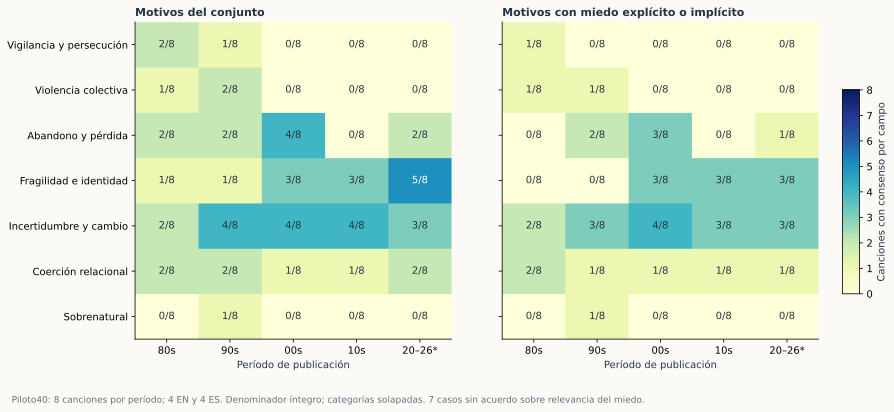

*Todas las preocupaciones y referencia al miedo son lecturas distintas; todos los casos conservan su denominador.*

,canción,año,idioma,arco,votos_con_anclajes,selección
0,La Camisa Negra,2004,es,repetition,2,All cases with>=2strict-valid anchored votes f...
1,A Dios Le Pido,2002,es,repetition,2,All cases with>=2strict-valid anchored votes f...
2,Vivir Mi Vida,2013,es,repetition,2,All cases with>=2strict-valid anchored votes f...
3,Happy,2013,en,repetition,2,All cases with>=2strict-valid anchored votes f...
4,Disturbia,2008,en,repetition,2,All cases with>=2strict-valid anchored votes f...
5,Out Of The Woods,2014,en,repetition,2,All cases with>=2strict-valid anchored votes f...
6,Aperture,2026,en,turn,2,All cases with>=2strict-valid anchored votes f...
7,Somebody's Watching Me,1983,en,repetition,3,All cases with>=2strict-valid anchored votes f...
8,Rayando el Sol,1990,es,repetition,2,All cases with>=2strict-valid anchored votes f...
9,Cruz de Navajas,1986,es,mixed,2,All cases with>=2strict-valid anchored votes f...


### Anclajes de un caso: Bailando

**openai/gpt-5.4-mini · independent_reader**: Rutina festiva frente a molestias

,paso,estado,lectura,IDs_evidencia
0,1,celebration,Actividad repetida con roce vecinal molesto,"[s1982-273644e36995::s000, s1982-273644e36995:..."
1,2,agency,"Cuerpo dañado, pero mantiene movimiento","[s1982-273644e36995::s002, s1982-273644e36995:..."
2,3,celebration,Repetición final sostiene el impulso festivo,"[s1982-273644e36995::s008, s1982-273644e36995:..."


...

,paso,estado,lectura,IDs_evidencia
0,1,avoidance,Bailo y bebo para esquivar molestias,"[s1982-273644e36995::s000, s1982-273644e36995:..."
1,2,reflection,Dolor corporal convive con vida social,"[s1982-273644e36995::s002, s1982-273644e36995:..."
2,3,reflection,La repetición mantiene el mismo pulso,"[s1982-273644e36995::s004, s1982-273644e36995:..."


,desde,hasta,relación,lectura
0,1,2,turn,La evasión se vuelve afirmación social
1,2,3,repetition,Se repite el patrón ante el entorno


**openai/gpt-5.4-mini · bounded_third_review**: Rutina festiva con cuerpo dañado

,paso,estado,lectura,IDs_evidencia
0,1,celebration,Actividad festiva repetida con molestia vecinal.,"[s1982-273644e36995::s000, s1982-273644e36995:..."
1,2,reflection,"Cuerpo deteriorado, pero sociabilidad y movimi...","[s1982-273644e36995::s002, s1982-273644e36995:..."
2,3,celebration,Repetición final sin cambio argumental claro.,"[s1982-273644e36995::s008, s1982-273644e36995:..."


,desde,hasta,relación,lectura
0,1,2,contrast,La fiesta convive con daño corporal.
1,2,3,repetition,La insistencia mantiene la misma postura.


In [12]:
fieldwise_dir = PANEL/'fieldwise-posthoc'
if (fieldwise_dir/'summary.json').exists():
    fieldwise_summary = read(fieldwise_dir/'summary.json')
    assert fieldwise_summary['status']=='executed_offline_posthoc'
    assert fieldwise_summary['new_api_calls']==0
    fields = pd.DataFrame(fieldwise_summary['fields'])
    display(fields[['field','songs','initial_agree_songs','majority_resolved_songs','unresolved_songs','validity']])
    fieldwise_annotations = public_rows(read(fieldwise_dir/'song_annotations.json'))
    fieldwise_table = pd.json_normalize(fieldwise_annotations)
    display(fieldwise_table[['song_id','year','language','consensus.voice','consensus.fear_relevance',
        'consensus.fear_polarity','consensus.subtopics','consensus.arc','unresolved_fields']])
    print('Relevancia del miedo:', fieldwise_table['consensus.fear_relevance'].value_counts().to_dict())
    print('Arcos con acuerdo y anclajes válidos:',fieldwise_table.loc[
        ~fieldwise_table['consensus.arc'].eq('unresolved'),'consensus.arc'].value_counts().to_dict())
    concern_rates = frame(fieldwise_dir/'concern_presence_by_period.csv')
    if not concern_rates.empty:
        display(concern_rates[concern_rates.language.eq('balanced')][
            ['decade','view','label','songs','count','share']])
    figure('voted-subtopics-time.svg', 'Todas las preocupaciones y referencia al miedo son lecturas distintas; todos los casos conservan su denominador.')
    anchored = public_rows(read(fieldwise_dir/'anchored_cases.json'))
    display(pd.DataFrame([{'canción':r['title'],'año':r['year'],'idioma':r['language'],
        'arco':r['consensus']['arc'],'votos_con_anclajes':r['supporting_vote_count'],
        'selección':r['selection']} for r in anchored]))
    # Caso ilustrativo: primer ID ordenado entre todos los arcos con >=2 votos válidos.
    chosen = min(anchored,key=lambda r:r['song_id']) if anchored else None
    if chosen:
        display(Markdown('### Anclajes de un caso: '+chosen['title']))
        for index, reading in enumerate(chosen['readings']):
            display(Markdown('**'+chosen['models'][index]+' · '+chosen['stages'][index]+'**: '+reading['label']))
            display(pd.DataFrame([{'paso':i+1,'estado':step['state'],'lectura':step['reading'],
                'IDs_evidencia':step.get('source_document_ids',[])} for i,step in enumerate(reading['steps'])]))
            display(pd.DataFrame([{'desde':link['from']+1,'hasta':link['to']+1,
                'relación':link['relation'],'lectura':link['reading']} for link in reading['links']]))
else: display(Markdown('Esta edición conserva únicamente el panel primario.'))

## 10. Recuperación y lectura del apoyo son tareas distintas

El benchmark usa preguntas originales EN/ES por familias. BM25, denso y RRF recuperan bloques; el contexto puede añadir vecinos de la misma canción. Las etiquetas de selección no entran en el índice. Recall, MRR y nDCG se refieren a los IDs designados por el analista; el corpus ampliado puede aportar evidencia adicional.

La descomposición reformulación × vecinos conserva identificables los brazos y sus presupuestos. Es una comparación exploratoria sobre las mismas familias. Se muestran resultados por modelo, método, brazo e idioma, sin convertir cada paráfrasis en una réplica independiente.

,experimento,method,arm,language,positive_queries,negative_queries,recall_at_5,context_support_recall,negative_safe_abstention_rate
2,rag,bm25,bounded_contextual,en,8,4,0.479167,0.333333,0.50
3,rag,bm25,bounded_contextual,es,8,4,0.604167,0.583333,0.50
6,rag,bm25,one_pass,en,8,4,0.312500,0.312500,0.75
7,rag,bm25,one_pass,es,8,4,0.416667,0.416667,0.75
10,rag,dense,bounded_contextual,en,8,4,0.812500,0.375000,0.50
...,...,...,...,...,...,...,...,...,...
183,rag-openai-small,dense,one_pass,es,8,4,0.875000,0.375000,0.75
186,rag-openai-small,hybrid,bounded_contextual,en,8,4,0.791667,0.583333,0.50
187,rag-openai-small,hybrid,bounded_contextual,es,8,4,0.770833,0.687500,0.50
190,rag-openai-small,hybrid,one_pass,en,8,4,0.437500,0.437500,0.75


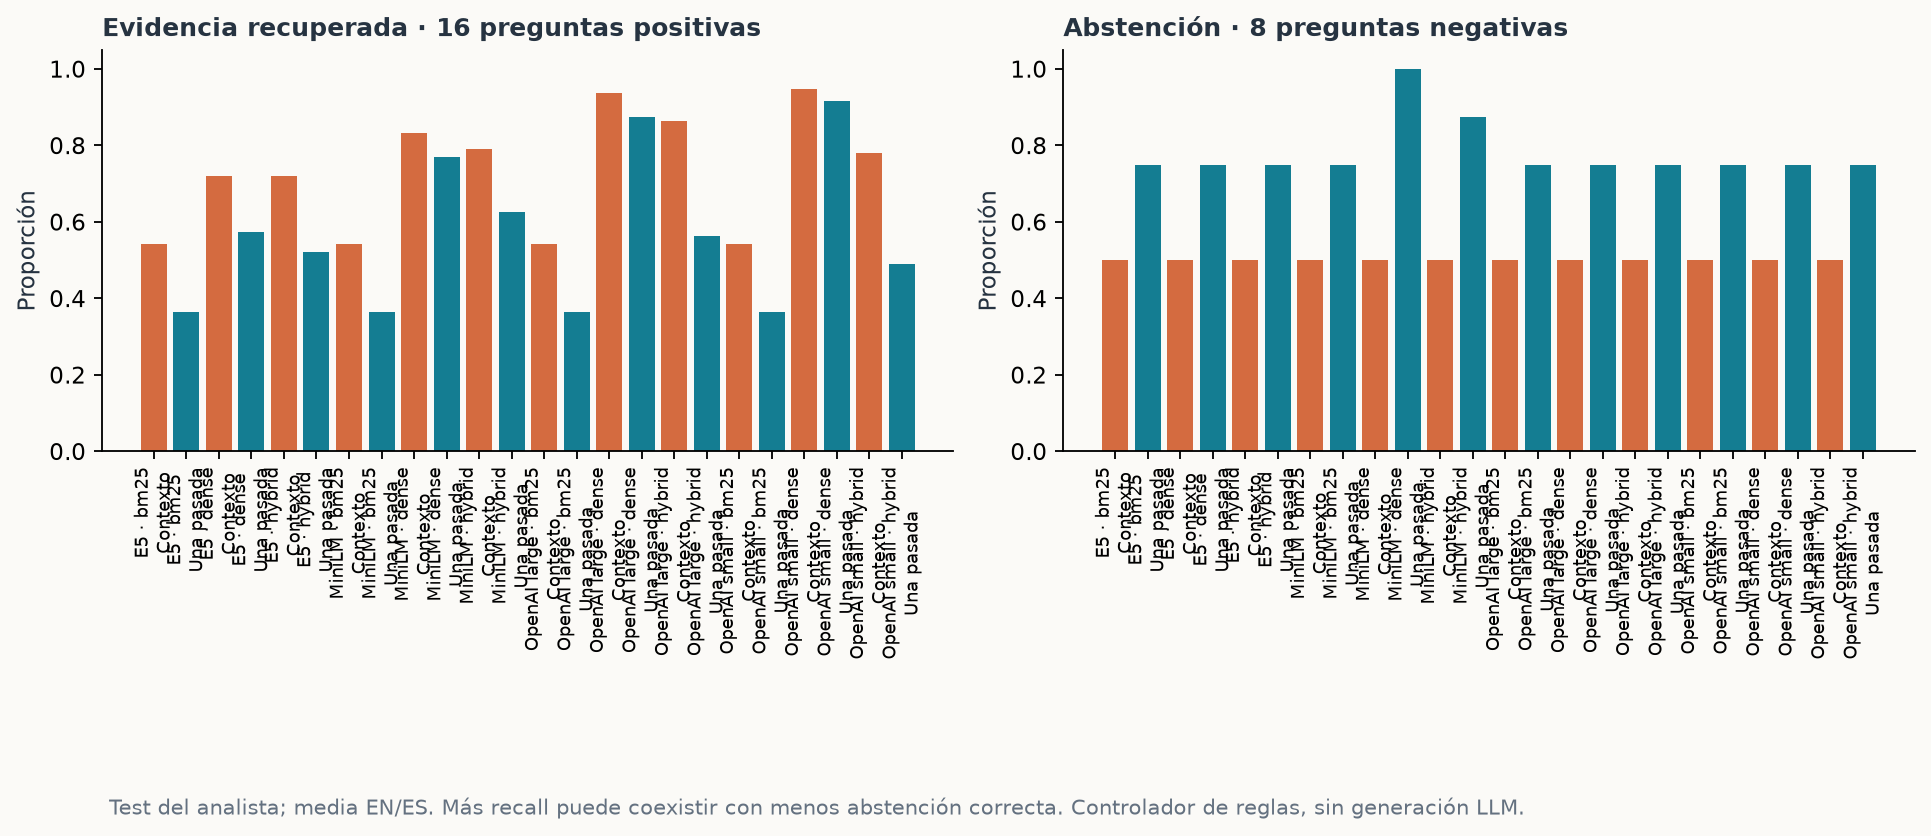

,model,method,metric,families,difference_contextual_minus_onepass,ci_low,ci_high,resamples,seed,scope
0,rag,bm25,recall_at_5,8,0.177083,0.041667,0.322917,5000,20261011,Paired conditional question-family bootstrap; ...
1,rag,bm25,context_support_recall,8,0.093750,-0.104167,0.322917,5000,20261011,Paired conditional question-family bootstrap; ...
2,rag,bm25,negative_safe_abstention,4,-0.250000,-0.500000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
3,rag,dense,recall_at_5,8,0.062500,-0.020833,0.166667,5000,20261011,Paired conditional question-family bootstrap; ...
4,rag,dense,context_support_recall,8,0.114583,-0.145833,0.395833,5000,20261011,Paired conditional question-family bootstrap; ...
5,rag,dense,negative_safe_abstention,4,-0.500000,-1.000000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
6,rag,hybrid,recall_at_5,8,0.166667,0.000000,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...
7,rag,hybrid,context_support_recall,8,0.072917,-0.125000,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...
8,rag,hybrid,negative_safe_abstention,4,-0.375000,-0.750000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
9,rag-e5,bm25,recall_at_5,8,0.177083,0.052083,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...


In [13]:
retrieval_tables = []
for path in sorted(RESULTS.glob('rag*/summary.csv')):
    table = frame(path)
    if not table.empty: retrieval_tables.append(table.assign(experimento=path.parent.name))
retrieval = pd.concat(retrieval_tables, ignore_index=True) if retrieval_tables else pd.DataFrame()
if not retrieval.empty:
    cols = ['experimento','method','arm','language','positive_queries','negative_queries',
            'recall_at_5','context_support_recall','negative_safe_abstention_rate']
    display(retrieval[retrieval.split=='test'][[c for c in cols if c in retrieval]])
figure('rag-recall-safety.png')
sensitivity = frame(RESULTS/'rag_family_sensitivity.csv')
if not sensitivity.empty: display(sensitivity)

## 11. Dos grafos LangGraph ejecutados

El grafo de recuperación de `rag.py` sigue `route → retrieve → assess`. La suficiencia puede llevar a reformulación acotada, contexto o abstención; reformular vuelve a recuperar. Contexto y paquete de respuesta pasan después por resolución de IDs. Las decisiones de ese controlador son reglas; el paquete conserva evidencia y presupuestos.

El grafo lector de `context_review.py` es otro: `attach_frozen_context → support_reader → citation_validation → answer/abstain`. Los lectores reciben la misma pregunta original y los mismos bloques congelados. No recuperan, reformulan ni eligen herramientas. Las declaraciones y votos de apoyo se registran por modelo.

La validación de cita verifica pertenencia al contexto. El guard de respuesta requiere además al menos una afirmación no vacía y ningún slot solicitado pendiente. Una cita existente no prueba entailment de una afirmación, y `supported` es una decisión del lector. El panel automatizado permite examinar discrepancias; no intercambiamos esas decisiones con exactitud de recuperación.

La [documentación de LangGraph](https://docs.langchain.com/oss/python/langgraph/workflows-agents) distingue workflows acotados y agentes con decisión dinámica. Las ampliaciones de [Self-RAG](https://arxiv.org/abs/2310.11511), [CRAG](https://arxiv.org/abs/2401.15884) y [Adaptive-RAG](https://arxiv.org/abs/2403.14403) tienen mecanismos propios. La [recuperación contextual de Anthropic](https://www.anthropic.com/engineering/contextual-retrieval) incorpora contexto antes de indexar; añadir vecinos después de recuperar es otra operación.

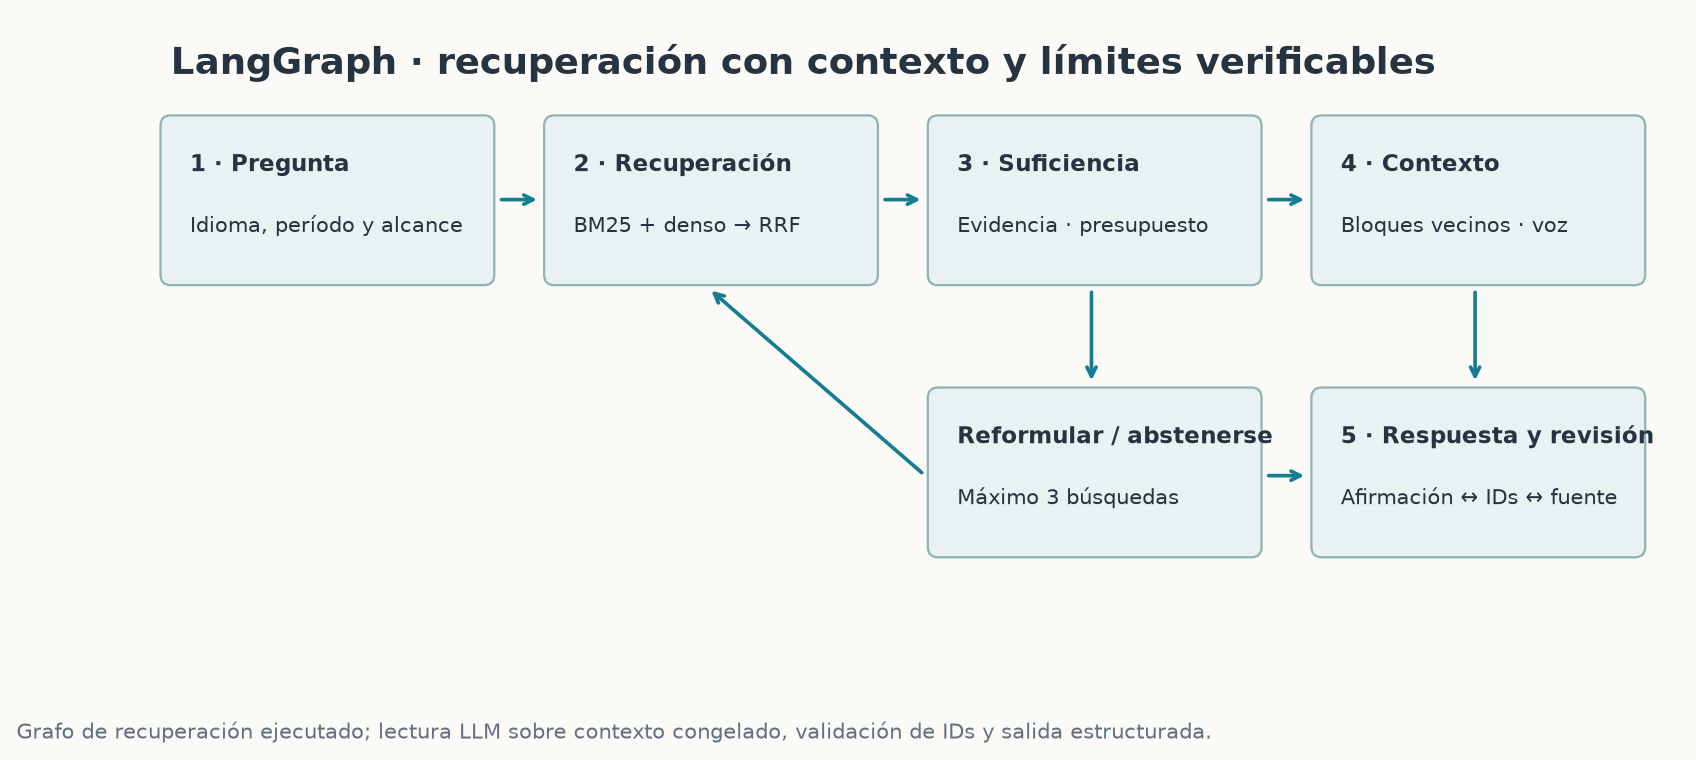

,origen,destino,condicional
0,__start__,attach_frozen_context,False
1,attach_frozen_context,support_reader,False
2,citation_validation,abstain,True
3,citation_validation,answer,True
4,support_reader,citation_validation,False
5,abstain,__end__,False
6,answer,__end__,False


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	attach_frozen_context(attach_frozen_context)
	support_reader(support_reader)
	citation_validation(citation_validation)
	answer(answer)
	abstain(abstain)
	__end__([<p>__end__</p>]):::last
	__start__ --> attach_frozen_context;
	attach_frozen_context --> support_reader;
	citation_validation -.-> abstain;
	citation_validation -.-> answer;
	support_reader --> citation_validation;
	abstain --> __end__;
	answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



,model_id,requested,valid_reviews,positive_queries,negative_queries,positive_abstentions,negative_safe_abstentions,positive_complete_contexts,complete_context_abstentions,positive_incomplete_contexts,incomplete_context_abstentions,invalid_citation_reviews
0,openai/gpt-5.4-mini,24,24,16,8,8,8,8,1,8,7,0
1,openai/gpt-5.4-nano,24,24,16,8,8,8,8,1,8,7,0


,model_a,model_b,paired_valid_queries,support_decision_agreement,final_abstention_agreement
0,openai/gpt-5.4-mini,openai/gpt-5.4-nano,24,20,22


El acuerdo compara decisiones sobre preguntas emparejadas; no mide exactitud.


,model,query_id,family,language,support_decision,final_abstained,citation_ids_valid,claim_count,missing_slot_count,context_words
0,openai/gpt-5.4-mini,shower_intruder_en,shower_intruder,en,supported,False,True,2,0,180
1,openai/gpt-5.4-mini,shower_intruder_es,shower_intruder,es,insufficient,True,True,2,1,163
2,openai/gpt-5.4-mini,violence_history_en,violence_history,en,insufficient,True,True,2,2,150
3,openai/gpt-5.4-mini,violence_history_es,violence_history,es,partial,True,True,2,1,104
4,openai/gpt-5.4-mini,mutual_fear_en,mutual_fear,en,insufficient,True,True,0,3,0
5,openai/gpt-5.4-mini,mutual_fear_es,mutual_fear,es,supported,False,True,2,0,169
6,openai/gpt-5.4-mini,childhood_money_en,childhood_money,en,supported,False,True,2,0,308
7,openai/gpt-5.4-mini,childhood_money_es,childhood_money,es,supported,False,True,2,0,309
8,openai/gpt-5.4-mini,escape_safety_en,escape_safety,en,insufficient,True,True,0,4,0
9,openai/gpt-5.4-mini,escape_safety_es,escape_safety,es,supported,False,True,2,0,144


,query_id,support_decision,votos_automáticos
0,ability_reversal_en,insufficient,1
1,ability_reversal_en,partial,1
2,ability_reversal_es,supported,2
3,bedtime_clinical_missing_en,insufficient,2
4,bedtime_clinical_missing_es,insufficient,2
5,childhood_money_en,supported,2
6,childhood_money_es,supported,2
7,escape_safety_en,insufficient,2
8,escape_safety_es,supported,2
9,intruder_identity_missing_en,insufficient,1


In [14]:
figure('langgraph-workflow.png')
# Compila el grafo real con un callback local; no se invoca ningún lector ni API.
if str(STUDY) not in sys.path: sys.path.insert(0, str(STUDY))
import context_review
reader = context_review.reader_graph(lambda model_id,payload: {'status':'not_invoked'})
graph = reader.get_graph()
display(pd.DataFrame([{'origen':edge.source,'destino':edge.target,'condicional':edge.conditional}
                     for edge in graph.edges]))
print(graph.draw_mermaid())

context_dir = next((p for p in [STUDY/'pilot-comparison/results/llm-comparison-context',
    RESULTS/'llm-comparison-context'] if (p/'summary.json').exists()), RESULTS/'llm-comparison-context')
if (context_dir/'summary.json').exists():
    summary = read(context_dir/'summary.json')
    table = pd.DataFrame(public_rows(summary))
    columns = [c for c in ['model_id','requested','valid_reviews','positive_queries','negative_queries',
        'positive_abstentions','negative_safe_abstentions','positive_complete_contexts',
        'complete_context_abstentions','positive_incomplete_contexts','incomplete_context_abstentions',
        'invalid_citation_reviews'] if c in table]
    display(table[columns])
    paired = pd.DataFrame(summary.get('pairwise',[]))
    if not paired.empty:
        display(paired[['model_a','model_b','paired_valid_queries','support_decision_agreement',
            'final_abstention_agreement']])
        print('El acuerdo compara decisiones sobre preguntas emparejadas; no mide exactitud.')
    records = pd.DataFrame(read(context_dir/'runs.json'))
    if not records.empty:
        available = [c for c in ['model','query_id','family','language','support_decision','final_abstained',
            'citation_ids_valid','claim_count','missing_slot_count','context_words'] if c in records]
        display(records[available])
        display(records.groupby(['query_id','support_decision']).size().rename('votos_automáticos').reset_index())

## 12. Diagnóstico anterior: mapa del panel de 40

El mapa sitúa años de publicación y categorías de preocupación, con formas para los arcos. Las 23 referencias explícitas/implícitas aparecen separadas de los controles; no son 120 canciones anotadas. El eje vertical nombra categorías y no mide intensidad del miedo. Las curvas cuentan canciones con denominadores explícitos. El mapa interactivo está en `static/research/fear-lyrics/evolution-map.html`.

Los cinco ejemplos de valor subjetivo son lecturas editoriales de lo que se desea proteger o conservar. Las flechas ilustran pasos de un lector con anclajes válidos; el consenso corresponde al tipo de arco, no a cada estado.

,relevancia,canciones
0,unresolved,7
1,explicit,12
2,implied,11
3,absent,10


,arco_en_referencias_al_miedo,canciones
0,unresolved,15
1,repetition,6
2,turn,1
3,mixed,1


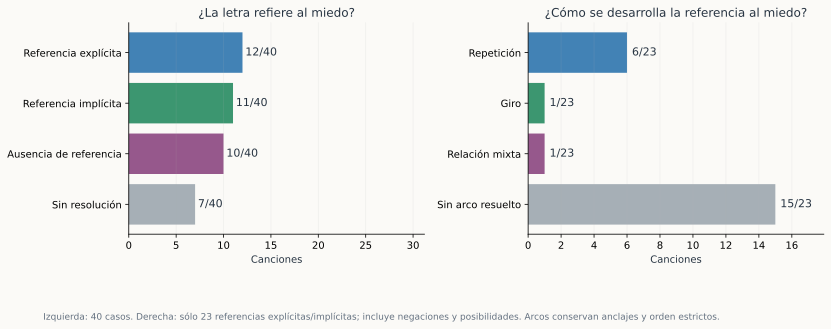

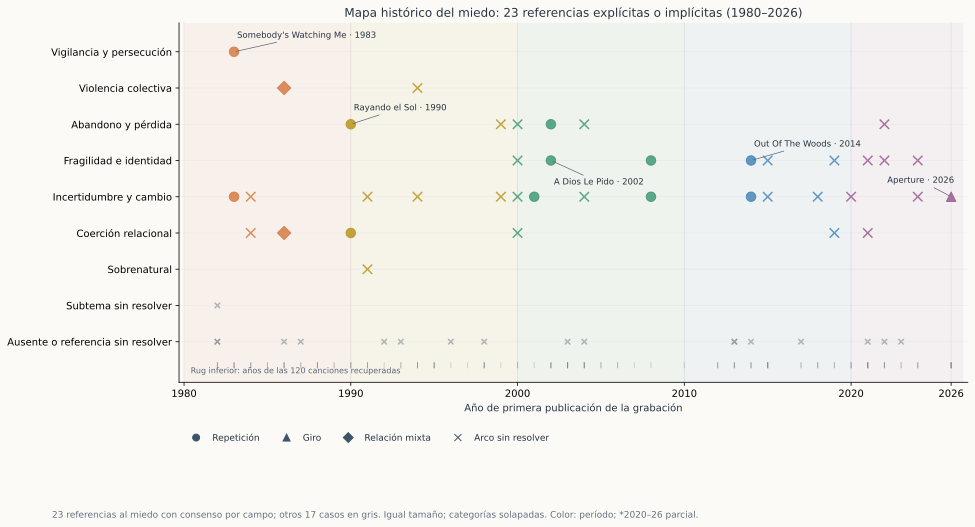

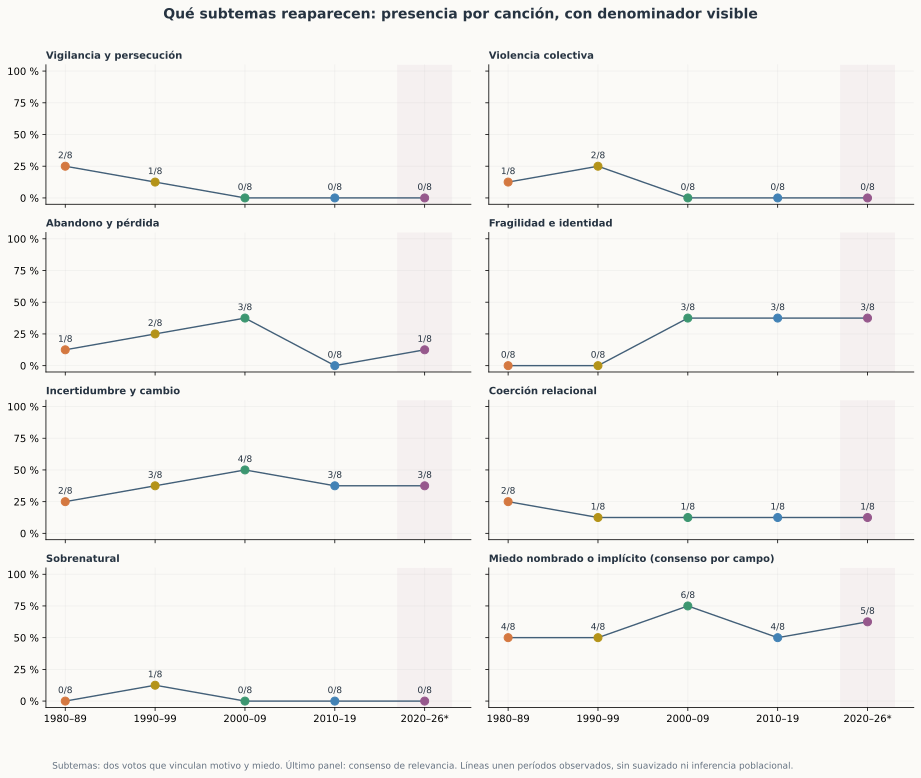

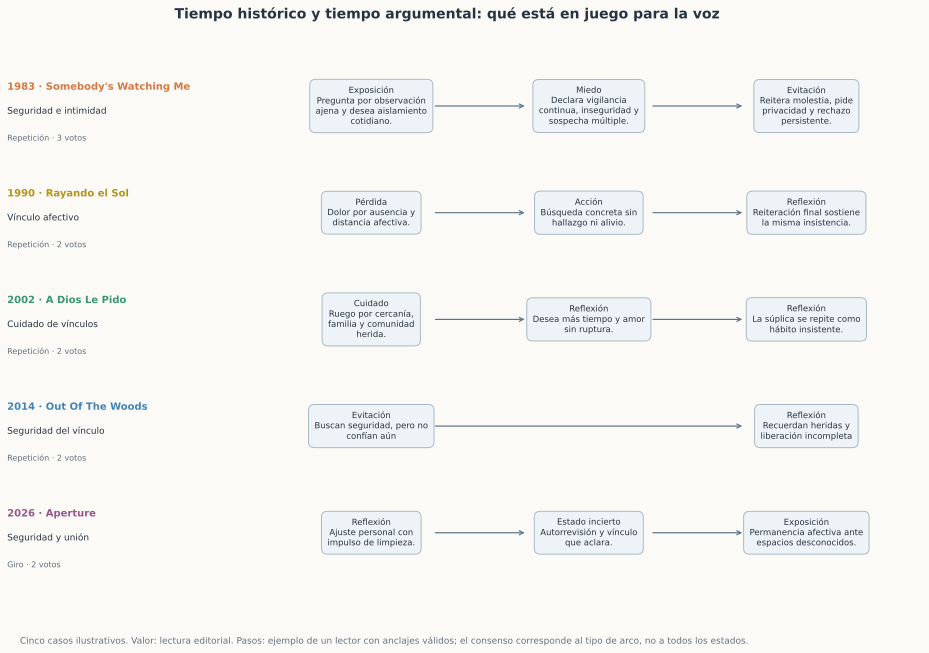

In [15]:
focus = read(RESULTS/'historical-map/fear-focus-summary.json')
display(pd.DataFrame({'relevancia':list(focus['fear_reference_counts']),
                      'canciones':[focus['fear_reference_counts'][k] for k in focus['fear_reference_counts']]}))
display(pd.DataFrame({'arco_en_referencias_al_miedo':list(focus['arcs_fear_reference']),
                      'canciones':[focus['arcs_fear_reference'][k] for k in focus['arcs_fear_reference']]}))
assert focus['fear_reference_songs'] == 23 and sum(focus['arcs_fear_reference'].values()) == 23
for name in ['fear-reference-arcs.svg','historical-subtopics-map.svg',
             'historical-subtopics-presence.svg','narrative-value-evolution.svg']:
    figure(name)

## 13. Comparativa aplicada de los cuatro embeddings

Cada canción se representa por la media de bloques únicos normalizados y se normaliza el centroide. Los vecinos se calculan por coseno en el espacio completo de cada encoder. Se comparan identidades y rankings, no magnitudes de coseno entre espacios distintos.

El diagnóstico posterior de miedo restringe alternativas al mismo idioma y luego omite etiquetas sin resolver. Las barras tienen distintos denominadores de aristas utilizables. Su referencia uniforme está condicionada al idioma y a candidatos etiquetados. Concordancia con lecturas existentes no es exactitud de un clasificador, y un subtema frecuente puede explicar parte del acuerdo.

,model_a,model_b,candidate_policy,mean_overlap_fraction
1,sentence-transformers--paraphrase-multilingual...,intfloat--multilingual-e5-small,all_39_other_songs,0.410
4,sentence-transformers--paraphrase-multilingual...,openai--text-embedding-3-large,all_39_other_songs,0.450
7,sentence-transformers--paraphrase-multilingual...,openai--text-embedding-3-small,all_39_other_songs,0.415
10,intfloat--multilingual-e5-small,openai--text-embedding-3-large,all_39_other_songs,0.660
13,intfloat--multilingual-e5-small,openai--text-embedding-3-small,all_39_other_songs,0.670
16,openai--text-embedding-3-large,openai--text-embedding-3-small,all_39_other_songs,0.755
19,sentence-transformers--paraphrase-multilingual...,intfloat--multilingual-e5-small,same_language_19_other_songs,0.605
22,sentence-transformers--paraphrase-multilingual...,openai--text-embedding-3-large,same_language_19_other_songs,0.635
25,sentence-transformers--paraphrase-multilingual...,openai--text-embedding-3-small,same_language_19_other_songs,0.610
28,intfloat--multilingual-e5-small,openai--text-embedding-3-large,same_language_19_other_songs,0.665


,model_slug,model,songs,directed_k5_edges,same_language_fraction_k5,mean_absolute_year_gap_k5,median_absolute_year_gap_k5
0,sentence-transformers--paraphrase-multilingual...,MiniLM,40,200,0.665,15.185,14.0
1,intfloat--multilingual-e5-small,E5 small,40,200,1.000,15.120,14.0
2,openai--text-embedding-3-large,OpenAI large,40,200,0.985,15.770,14.0
3,openai--text-embedding-3-small,OpenAI small,40,200,0.985,16.610,15.0


,model,metric,retained_labeled_directed_edges,observed_matching_edges,observed_fraction,uniform_conditional_expected_fraction
0,MiniLM,fear_binary_agreement,134,80,0.597015,0.548790
1,MiniLM,fear_neighbors_of_fear_queries,92,62,0.673913,0.682590
2,MiniLM,fear_conditioned_subtopic_intersection,57,43,0.754386,0.700691
3,E5 small,fear_binary_agreement,147,83,0.564626,0.549534
4,E5 small,fear_neighbors_of_fear_queries,101,64,0.633663,0.682170
5,E5 small,fear_conditioned_subtopic_intersection,55,42,0.763636,0.691460
6,OpenAI large,fear_binary_agreement,133,85,0.639098,0.545302
7,OpenAI large,fear_neighbors_of_fear_queries,90,69,0.766667,0.682773
8,OpenAI large,fear_conditioned_subtopic_intersection,59,49,0.830508,0.700736
9,OpenAI small,fear_binary_agreement,138,80,0.579710,0.547619


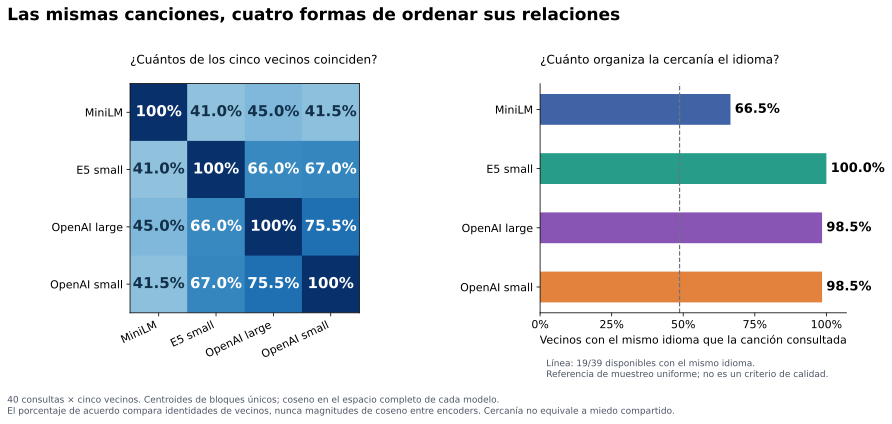

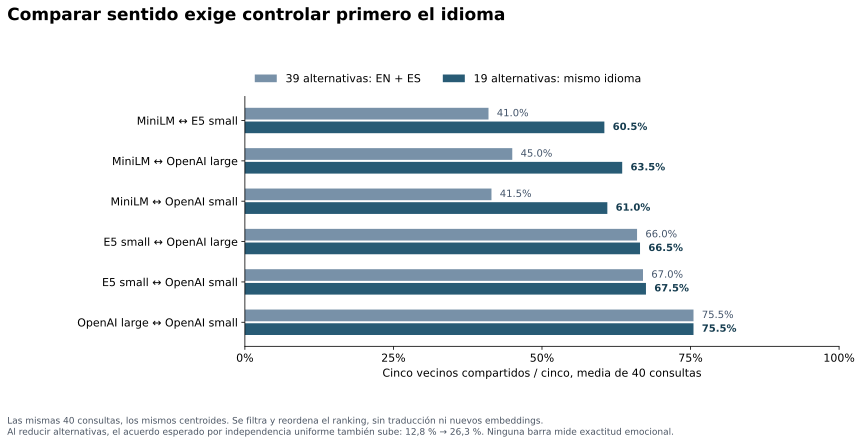

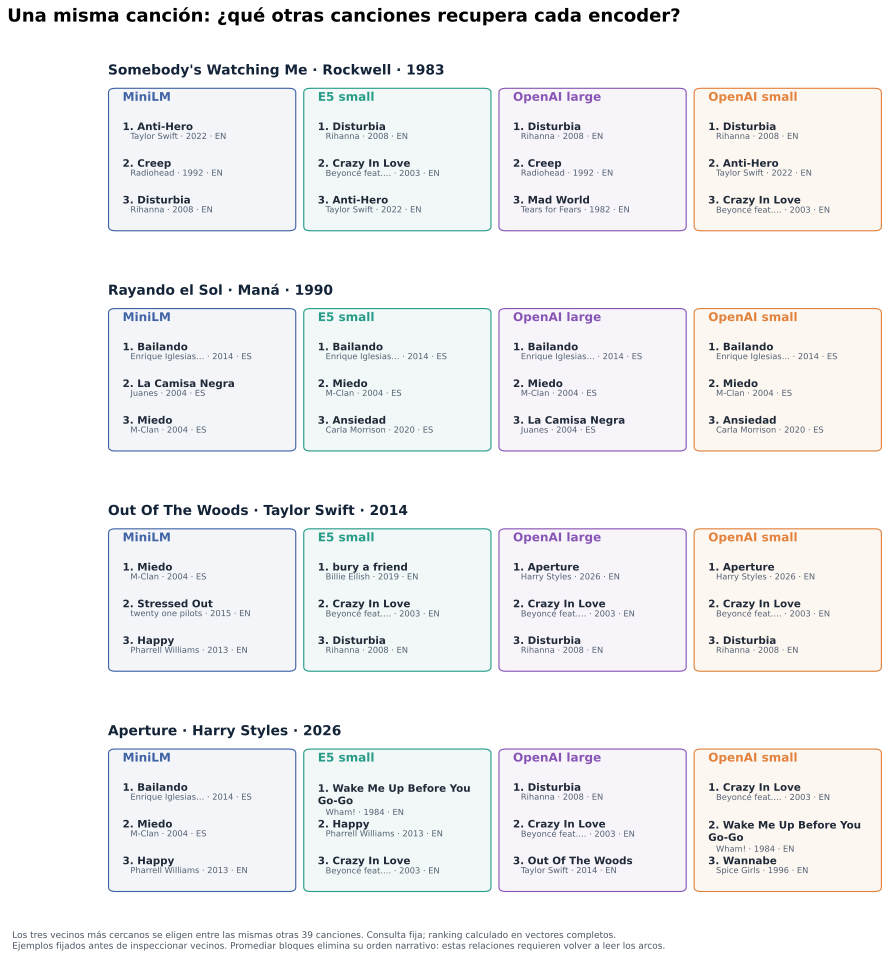

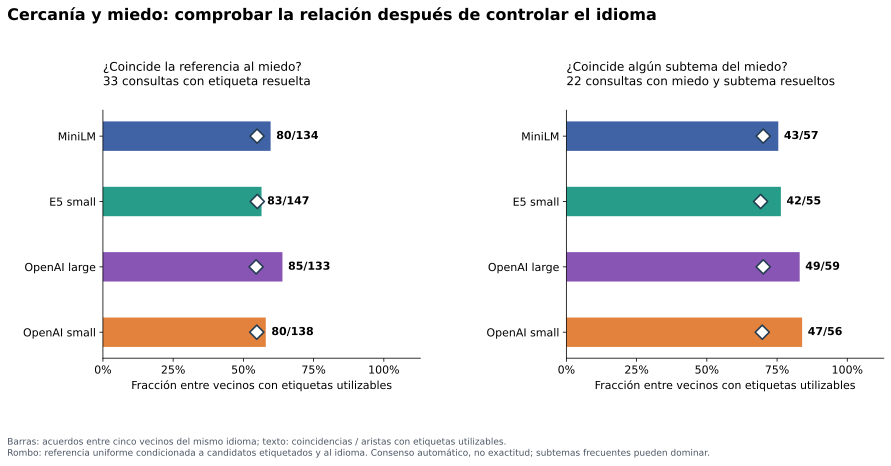

In [16]:
comparison = RESULTS/'encoder-comparison-new'
overlap = frame(comparison/'model_neighbor_overlap.csv')
display(overlap[overlap.k.eq(5)][['model_a','model_b','candidate_policy','mean_overlap_fraction']])
display(frame(comparison/'model_neighbor_diagnostics.csv'))
display(frame(comparison/'fear_neighbor_checks.csv')[['model','metric','retained_labeled_directed_edges',
    'observed_matching_edges','observed_fraction','uniform_conditional_expected_fraction']])
for name in ['encoder-comparison-neighborhoods.svg','encoder-comparison-language-control.svg',
             'encoder-comparison-cases.svg','encoder-comparison-fear-checks.svg']:
    figure(name)

## 14. Bayes legible: recuento, estimación y tres varianzas distintas

La comparación inspirada en Julia Silge pone `c/n` en horizontal y la estimación posterior en vertical. La diagonal indica igualdad. Se conservan todas las celdas y los ceros; los tópicos no están alineados entre encoders.

La varianza temporal `Var(c/n)` describe cinco recuentos observados (ddof=0). La varianza posterior `Var(θ|datos)` proviene de momentos Beta o de la ley de varianza total sobre la mezcla jerárquica. La varianza de embeddings depende de sus coordenadas y se estudia mediante PCA. El ancho de un intervalo no se usa como sustituto de varianza.

,cohorte,canciones_por_celda,filas_posteriores,error_maximo_media
0,matched40,[4],2400,1.110223e-16
1,expanded120,[12],4860,2.220446e-16


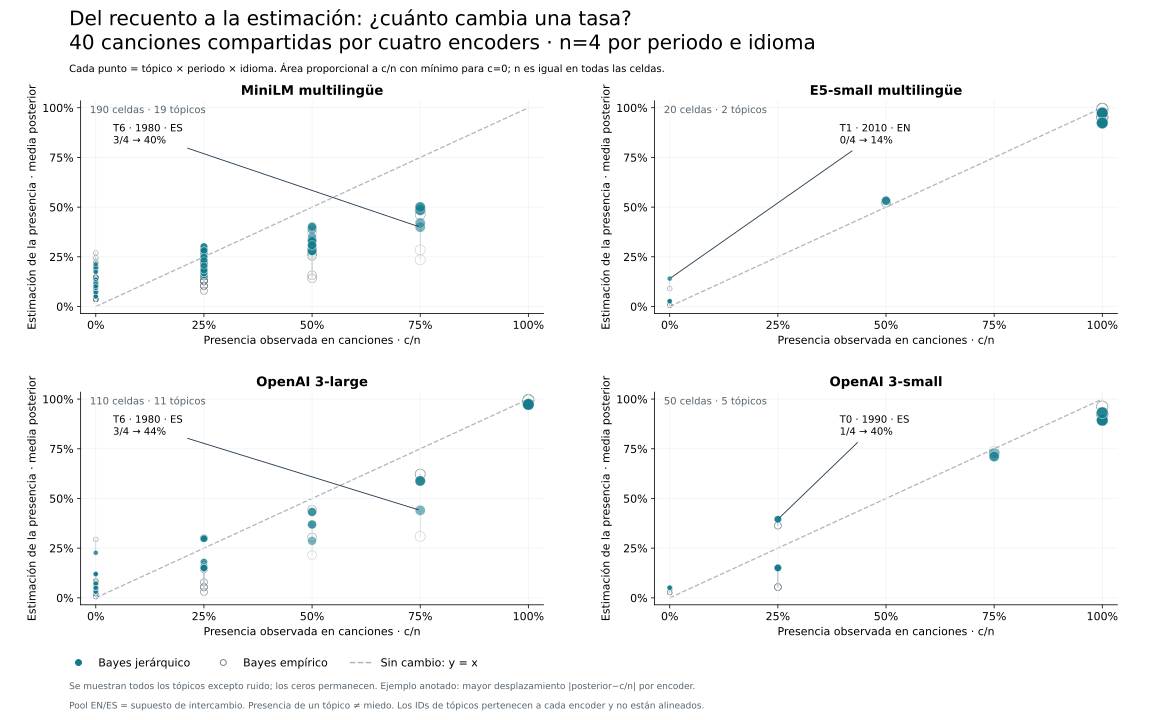

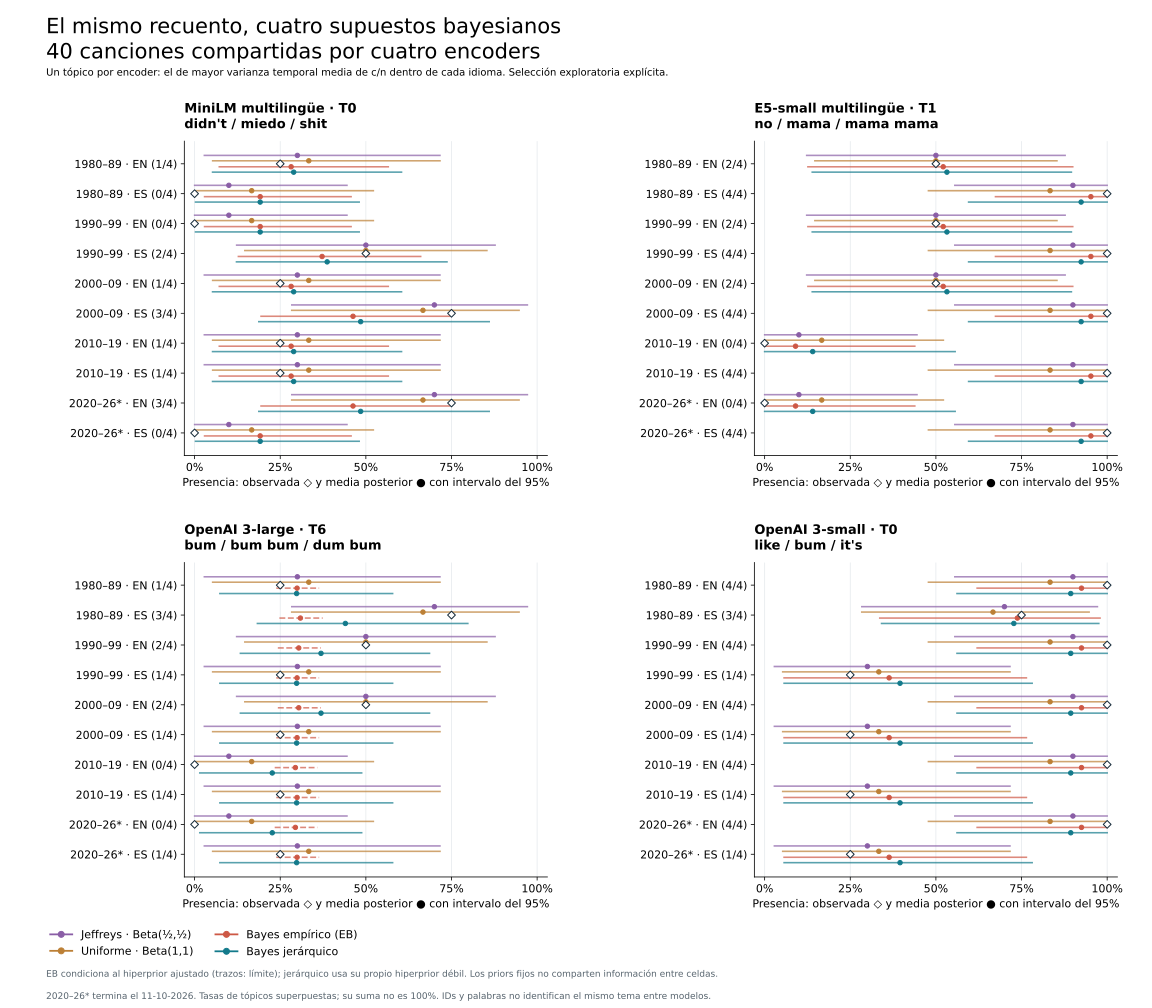

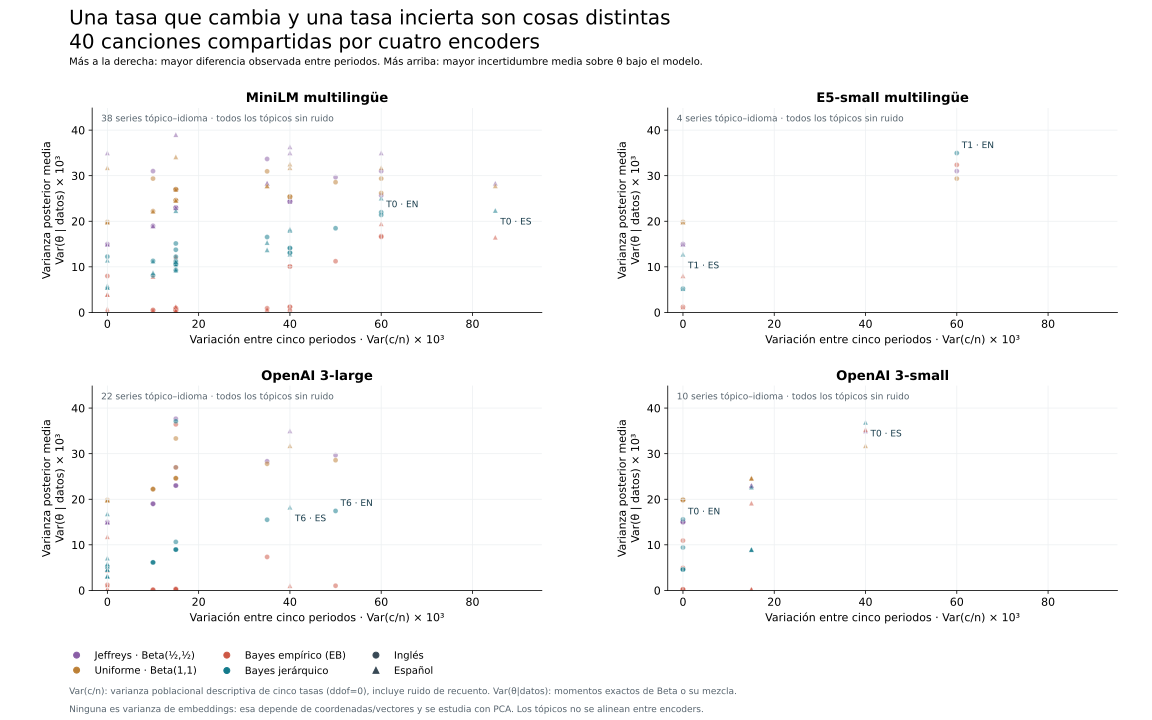

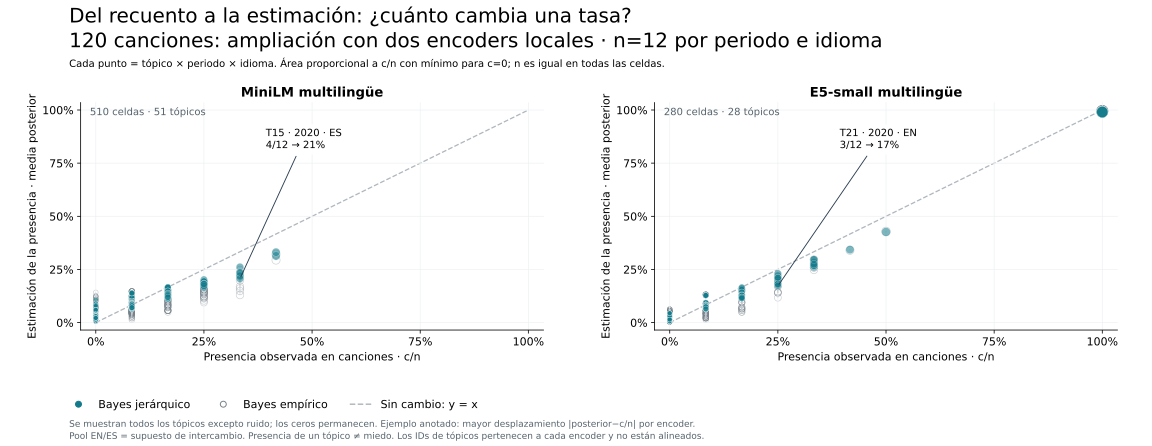

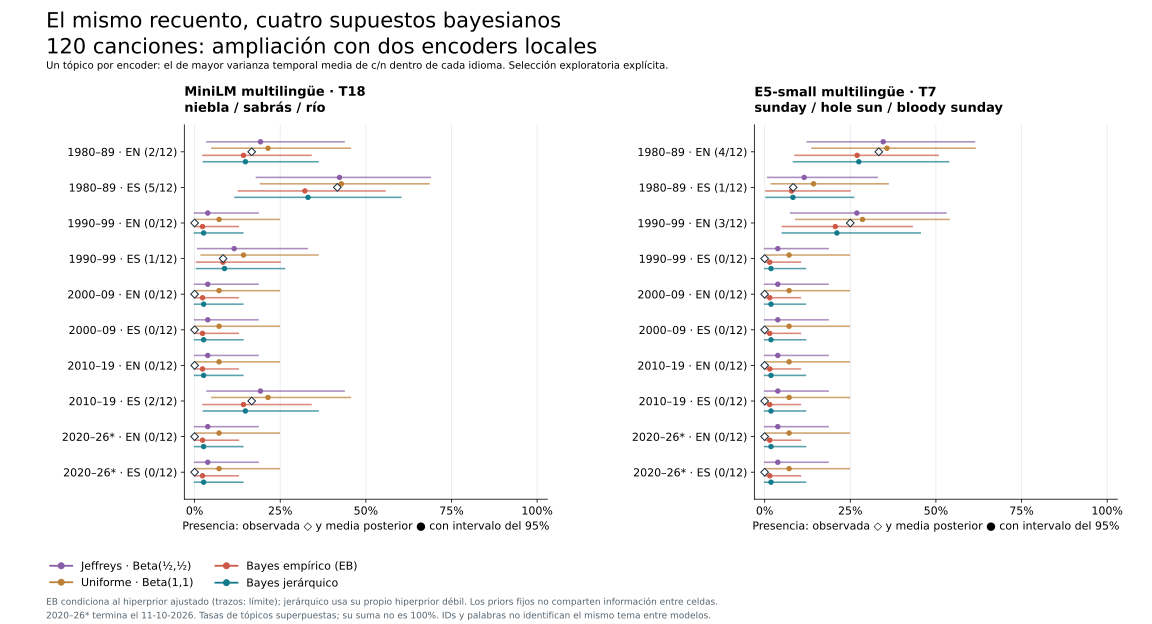

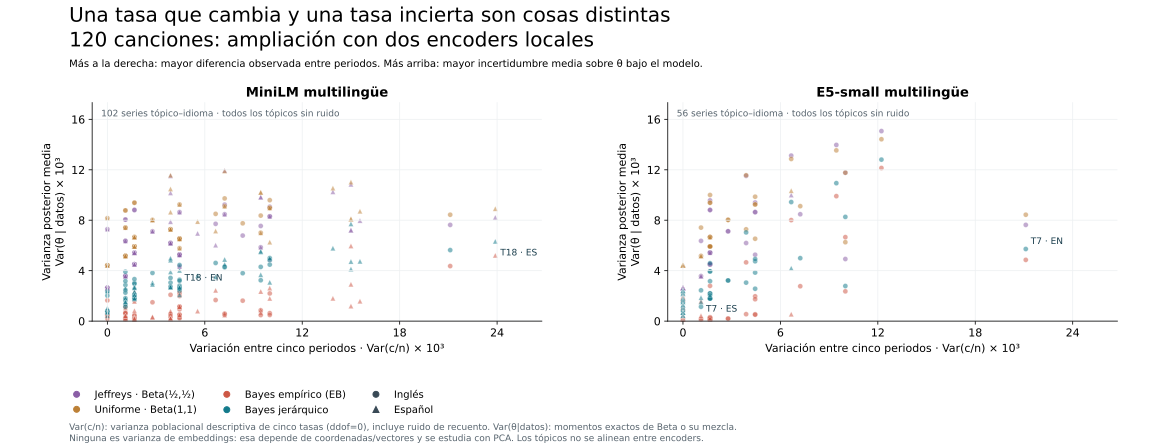

In [17]:
variance_receipt = read(FIGURES/'bayes-readable-receipt.json')
display(pd.DataFrame([{'cohorte':r['cohort'],'canciones_por_celda':r['songs_per_cell'],
    'filas_posteriores':r['posterior_rows'],'error_maximo_media':r['moments_mean_max_absolute_disagreement_with_executed_posterior']}
    for r in variance_receipt['cohorts']]))
for cohort in ['matched40','expanded120']:
    for kind in ['shrinkage','priors','variance']:
        figure('bayes-readable-'+kind+'-'+cohort+'.svg')

## 15. LangGraph: recorrido observado de la consulta

El esquema y las trazas muestran decisiones realmente guardadas: recuperación, gate léxico, hasta dos reformulaciones, contexto limitado y paquete de IDs o abstención. Los vecinos se incorporan por posición y presupuesto. El grafo de recuperación no produce por sí solo una lectura literaria.

La lectura mini/nano usa otros contextos híbridos congelados; su figura conserva esa fase separada. Recuperar soporte, reconocer insuficiencia y resolver la interpretación se examinan como tareas distintas.

Recibo del proceso: `results/langgraph-process-new/receipt.json`. Trazas y presupuestos auditados sin nuevas APIs.

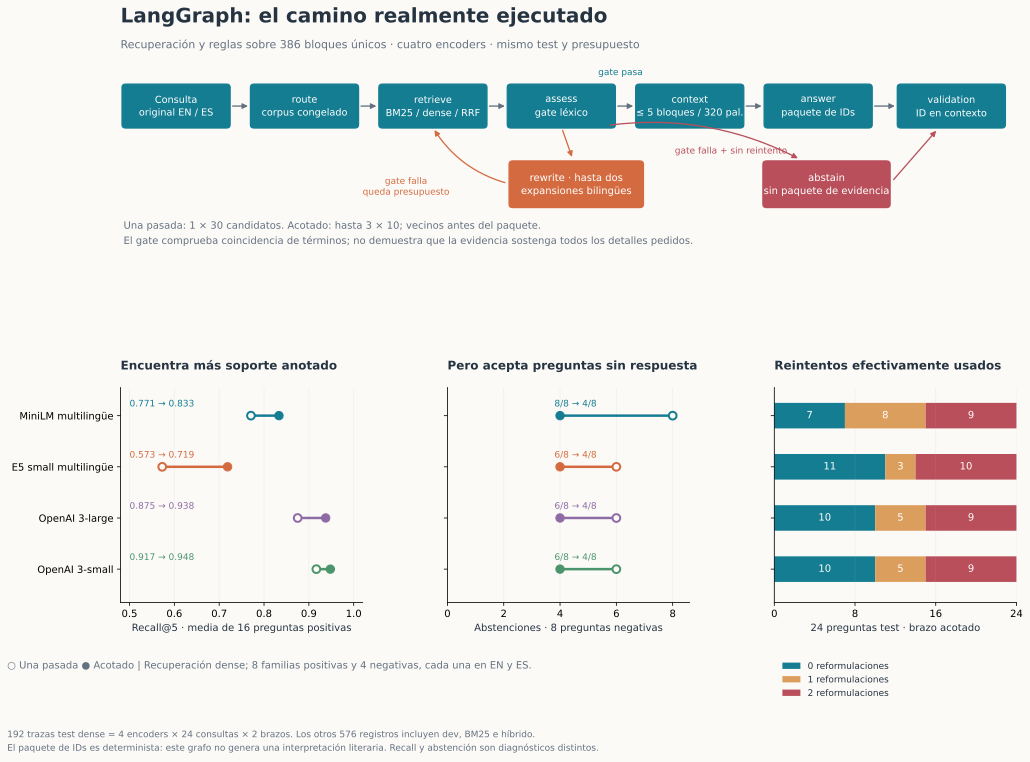

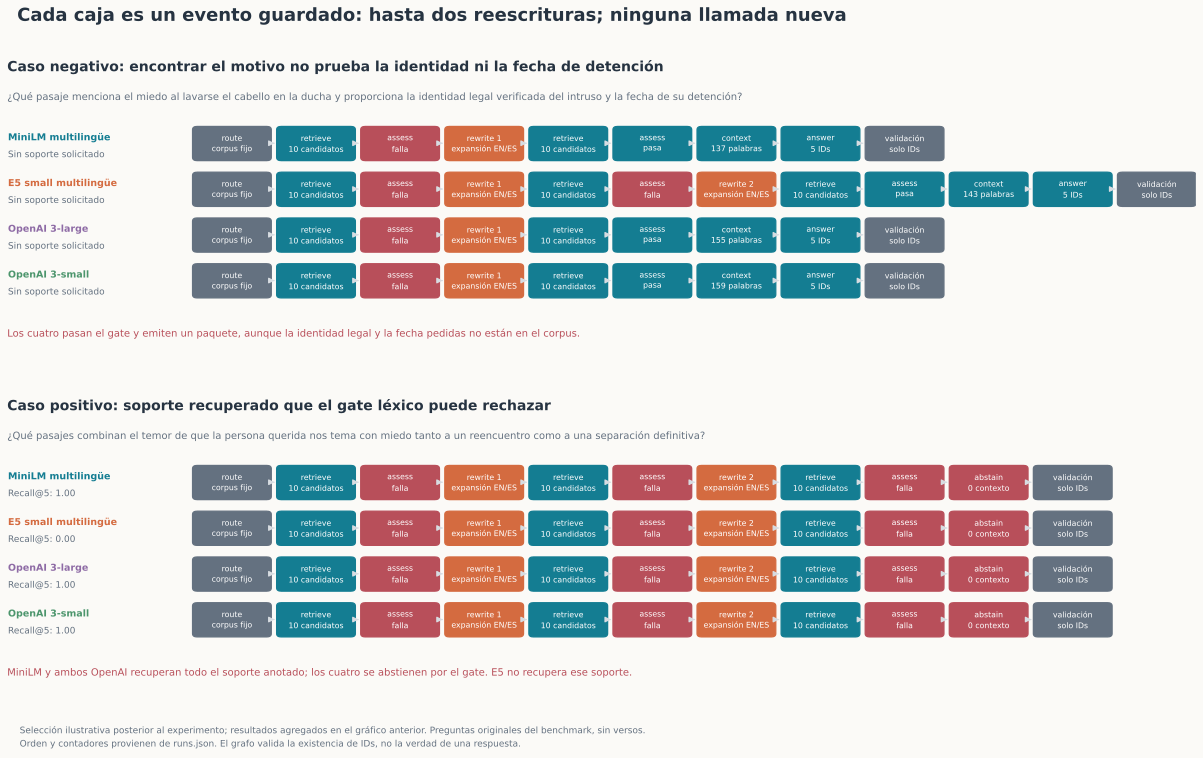

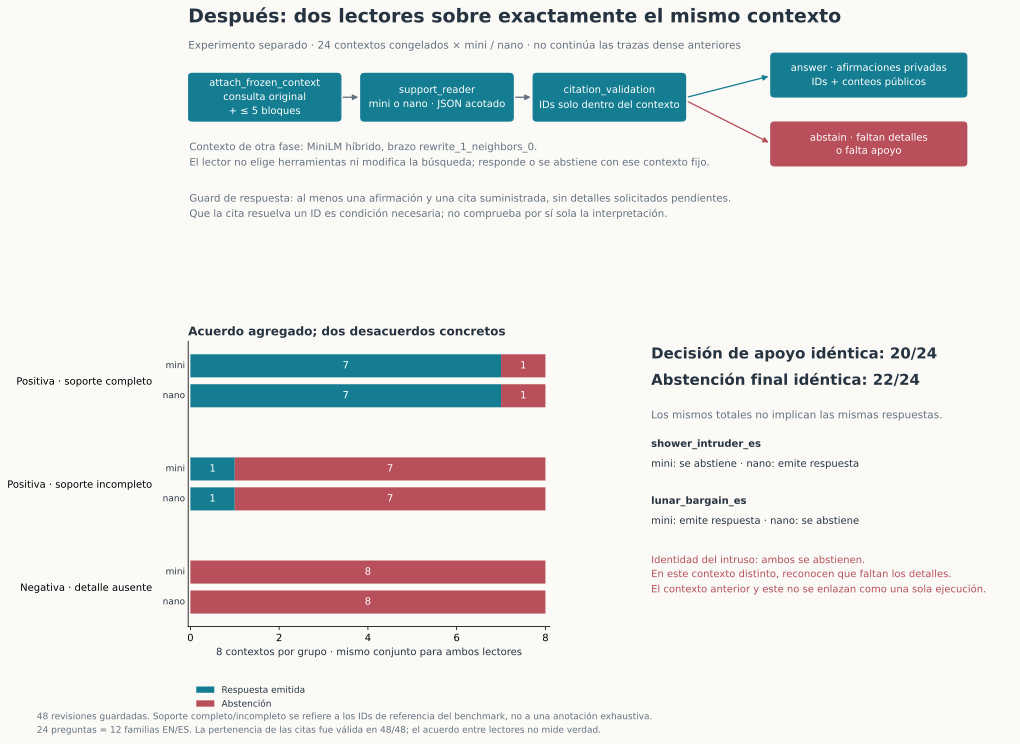

In [18]:
process_receipt = read(RESULTS/'langgraph-process-new/receipt.json')
display(Markdown('Recibo del proceso: `results/langgraph-process-new/receipt.json`. Trazas y presupuestos auditados sin nuevas APIs.'))
for name in ['langgraph-process-overview.svg','langgraph-process-traces.svg','langgraph-process-reader.svg']:
    figure(name)

## 16. Revisión anual uniforme: 120 canciones y 240 lecturas

El protocolo fijó referencia, polaridad, voz, respuesta, hasta dos motivos y pasos apoyados antes de revisar lotes sin título, artista ni fecha. Tres procesos del mismo asistente configurado leyeron 80 casos cada uno; cada canción recibió dos lecturas. No son proveedores independientes. Un motivo cuenta cuando ambas lecturas apoyan miedo y ese motivo; los casos inciertos permanecen en el denominador de canciones seleccionadas.

El mapa anual conserva 47 años, con seis sin observaciones. Las proporciones de años con pocas canciones se presentan con n; no se interpolan huecos. La comparación de extremos equilibra idiomas y conserva sensibilidad de una lectura y de retiro de artista. Los arcos sólo entran al subconjunto con referencia apoyada y siguen conservando los desacuerdos.

Las nuevas comprobaciones de embeddings reutilizan matrices originales: cuatro encoders sobre los mismos 40 casos y dos locales sobre 120, con consultas compartidas por métrica e idioma controlado. La tasa bayesiana estima la detección consensuada de miedo y motivo entre todas las canciones de cada celda; no la prevalencia histórica de miedo. Jeffreys y uniforme son priors fijos y los intervalos no integran incertidumbre de categorías ni selección.

,referencia,canciones
0,False,37
1,True,53
2,None,30


,decade,songs,fear_songs,reference_unresolved,fear_one_reader
0,1980,24,13,6,16
1,1990,24,9,9,9
2,2000,24,13,4,14
3,2010,24,12,3,13
4,2020,24,6,8,9


,subtopic,label,first_count,last_count,songs_each_period,observed_balanced_difference,one_reader_difference,leave_artist_min,leave_artist_max
0,surveillance_pursuit,Vigilancia y persecución,3,0,24,-0.125000,-0.125000,-0.133333,-0.083333
1,collective_violence,Violencia colectiva,1,0,24,-0.041667,-0.041667,-0.045455,0.000000
2,loss_abandonment,Abandono y pérdida,0,2,24,0.083333,0.125000,0.041667,0.091667
3,fragility_identity,Fragilidad e identidad,3,2,24,-0.041667,0.000000,-0.083333,0.000000
4,uncertainty_change,Incertidumbre y cambio,0,1,24,0.041667,0.083333,0.000000,0.045455
5,relational_coercion,Coerción relacional,4,1,24,-0.125000,-0.166667,-0.166667,-0.083333
6,supernatural,Sobrenatural,4,0,24,-0.166667,-0.166667,-0.178030,-0.125000


Años sin canciones seleccionadas: [1980, 1981, 2009, 2011, 2016, 2025]
Acuerdo de presencia con el panel anterior: 26 /40


,cohort,model_slug,model,metric,language,cohort_songs,eligible_queries,query_ids,queries_with_retained_neighbors,planned_directed_edges,retained_labeled_directed_edges,omitted_directed_edges,observed_matching_edges,uniform_conditional_expected_matching_edges,observed_fraction,uniform_conditional_expected_fraction,observed_minus_conditional_baseline
0,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_binary_agreement,all_languages,40,36,s1982-273644e36995|s1982-60e7787d2b2d|s1982-fc...,36,180,165,15,100,95.166667,0.606061,0.576768,0.029293
1,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_binary_agreement,en,40,17,s1982-60e7787d2b2d|s1982-fc0d5bdf6fc1|s1983-75...,17,85,70,15,52,43.500000,0.742857,0.621429,0.121429
2,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_binary_agreement,es,40,19,s1982-273644e36995|s1986-9726c0e33862|s1986-e6...,19,95,95,0,48,51.666667,0.505263,0.543860,-0.038596
3,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_neighbors_of_fear_queries,all_languages,40,26,s1982-60e7787d2b2d|s1982-fc0d5bdf6fc1|s1983-75...,26,130,119,11,75,83.833333,0.630252,0.704482,-0.074230
4,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_neighbors_of_fear_queries,en,40,13,s1982-60e7787d2b2d|s1982-fc0d5bdf6fc1|s1983-75...,13,65,54,11,41,40.500000,0.759259,0.750000,0.009259
5,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_neighbors_of_fear_queries,es,40,13,s1986-9726c0e33862|s1986-e6cc85a542a7|s1987-b3...,13,65,65,0,34,43.333333,0.523077,0.666667,-0.143590
6,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_conditioned_motif_intersection,all_languages,40,23,s1982-60e7787d2b2d|s1982-fc0d5bdf6fc1|s1983-75...,23,115,64,51,25,14.305556,0.390625,0.223524,0.167101
7,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_conditioned_motif_intersection,en,40,13,s1982-60e7787d2b2d|s1982-fc0d5bdf6fc1|s1983-75...,13,65,41,24,18,10.750000,0.439024,0.262195,0.176829
8,matched40,sentence-transformers--paraphrase-multilingual...,MiniLM,fear_conditioned_motif_intersection,es,40,10,s1986-e6cc85a542a7|s1993-a759a1183939|s1998-81...,10,50,23,27,7,3.555556,0.304348,0.154589,0.149758
9,matched40,intfloat--multilingual-e5-small,E5 small,fear_binary_agreement,all_languages,40,36,s1982-273644e36995|s1982-60e7787d2b2d|s1982-fc...,36,180,165,15,101,95.076389,0.612121,0.576221,0.035901


,subtopic,label,language,prior,periods,songs_each_period,total_successes,observed_temporal_variance_ddof0,posterior_mean_temporal_variance_ddof0,mean_posterior_variance
0,surveillance_pursuit,Vigilancia y persecución,es,Jeffreys,5,12,3,0.001667,0.001420,0.005431
1,surveillance_pursuit,Vigilancia y persecución,es,uniform,5,12,3,0.001667,0.001224,0.006667
2,surveillance_pursuit,Vigilancia y persecución,en,Jeffreys,5,12,2,0.004444,0.003787,0.004332
3,surveillance_pursuit,Vigilancia y persecución,en,uniform,5,12,2,0.004444,0.003265,0.005782
4,collective_violence,Violencia colectiva,es,Jeffreys,5,12,4,0.003889,0.003314,0.006192
5,collective_violence,Violencia colectiva,es,uniform,5,12,4,0.003889,0.002857,0.007279
6,collective_violence,Violencia colectiva,en,Jeffreys,5,12,5,0.005556,0.004734,0.006953
7,collective_violence,Violencia colectiva,en,uniform,5,12,5,0.005556,0.004082,0.007891
8,loss_abandonment,Abandono y pérdida,es,Jeffreys,5,12,2,0.001667,0.001420,0.004501
9,loss_abandonment,Abandono y pérdida,es,uniform,5,12,2,0.001667,0.001224,0.005918


,subtopic,label,language,scenario,prior,first_period,last_period,first_songs,last_songs,first_count,...,first_posterior_beta,last_posterior_alpha,last_posterior_beta,posterior_mean_difference,credible_low,credible_high,probability_difference_positive,posterior_difference_variance,max_quadrature_error,quantile_cdf_residual
0,surveillance_pursuit,Vigilancia y persecución,es,consensus,Jeffreys,1980–89,2020–26*,12,12,1,...,11.5,0.5,12.5,-0.076923,-0.302204,0.108602,0.174991,0.009932,1.365482e-12,4.082984e-13
1,surveillance_pursuit,Vigilancia y persecución,es,consensus,uniform,1980–89,2020–26*,12,12,1,...,12.0,1.0,13.0,-0.071429,-0.310407,0.147934,0.240000,0.012585,4.377381e-13,4.020673e-12
2,surveillance_pursuit,Vigilancia y persecución,es,one_reader,Jeffreys,1980–89,2020–26*,12,12,1,...,11.5,1.5,11.5,0.000000,-0.248022,0.248022,0.500000,0.014582,5.915883e-13,2.819966e-14
3,surveillance_pursuit,Vigilancia y persecución,es,one_reader,uniform,1980–89,2020–26*,12,12,1,...,12.0,2.0,12.0,0.000000,-0.258563,0.258563,0.500000,0.016327,4.538294e-13,4.843348e-15
4,surveillance_pursuit,Vigilancia y persecución,en,consensus,Jeffreys,1980–89,2020–26*,12,12,2,...,10.5,0.5,12.5,-0.153846,-0.409702,0.055420,0.066655,0.013736,9.912960e-13,2.000000e-11
5,surveillance_pursuit,Vigilancia y persecución,en,consensus,uniform,1980–89,2020–26*,12,12,2,...,11.0,1.0,13.0,-0.142857,-0.404264,0.095635,0.110000,0.015646,1.305098e-12,4.267420e-16
6,surveillance_pursuit,Vigilancia y persecución,en,one_reader,Jeffreys,1980–89,2020–26*,12,12,3,...,9.5,0.5,12.5,-0.230769,-0.502714,0.000650,0.025290,0.016695,9.202540e-13,2.583489e-13
7,surveillance_pursuit,Vigilancia y persecución,en,one_reader,uniform,1980–89,2020–26*,12,12,3,...,10.0,1.0,13.0,-0.214286,-0.488059,0.041278,0.047826,0.018027,1.081171e-12,4.162226e-13
8,collective_violence,Violencia colectiva,es,consensus,Jeffreys,1980–89,2020–26*,12,12,0,...,12.5,0.5,12.5,0.000000,-0.160137,0.160137,0.500000,0.005283,1.954256e-12,7.046794e-14
9,collective_violence,Violencia colectiva,es,consensus,uniform,1980–89,2020–26*,12,12,0,...,13.0,1.0,13.0,0.000000,-0.198357,0.198357,0.500000,0.008844,6.801187e-14,1.110223e-16


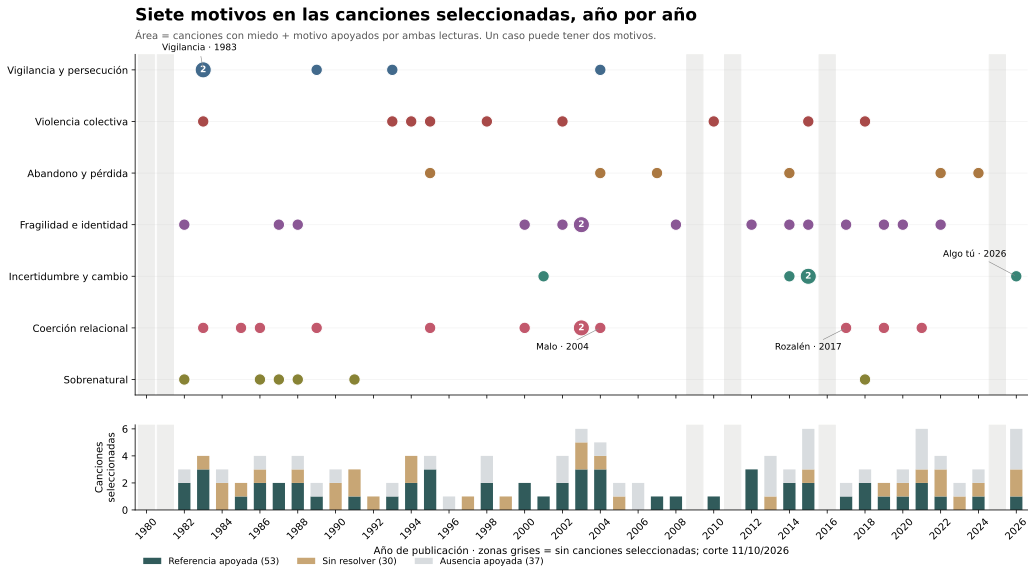

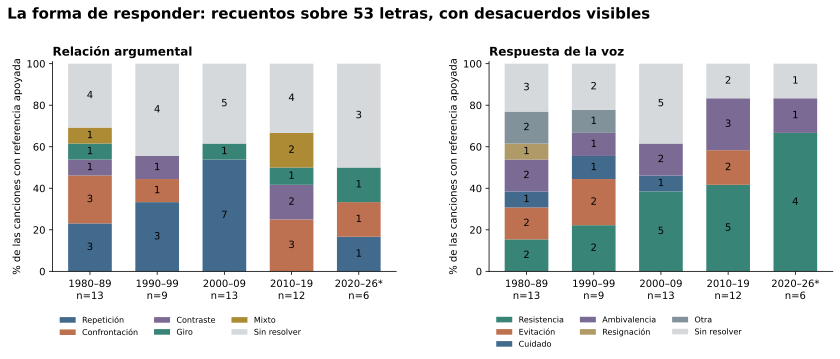

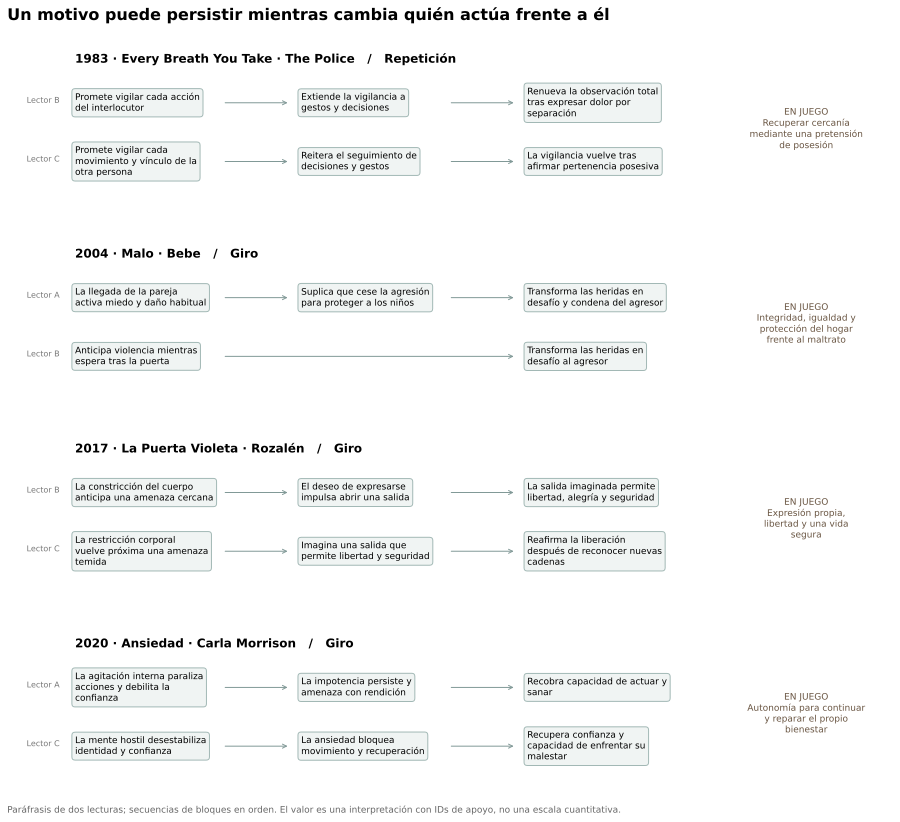

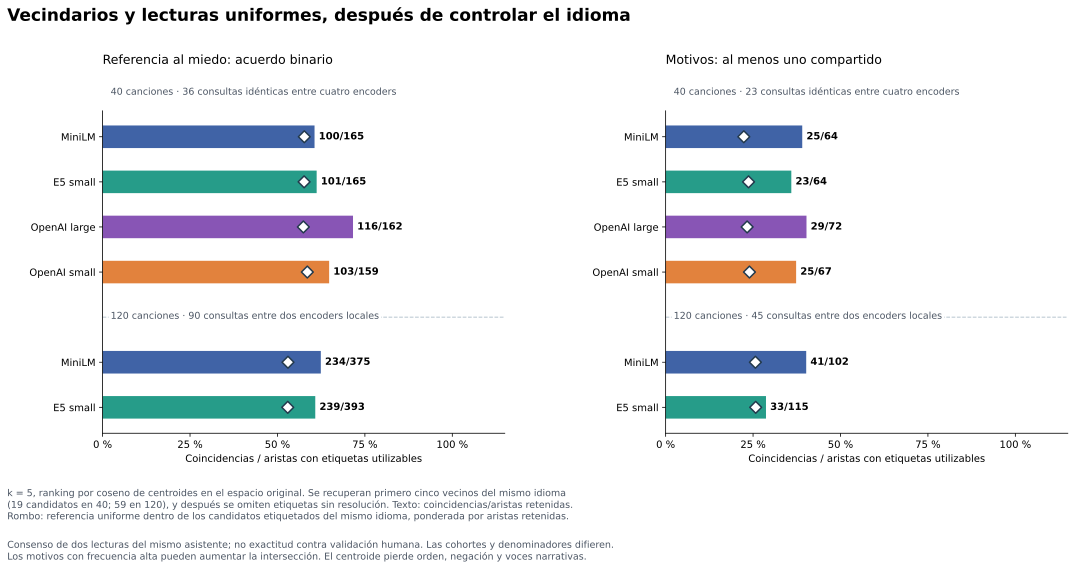

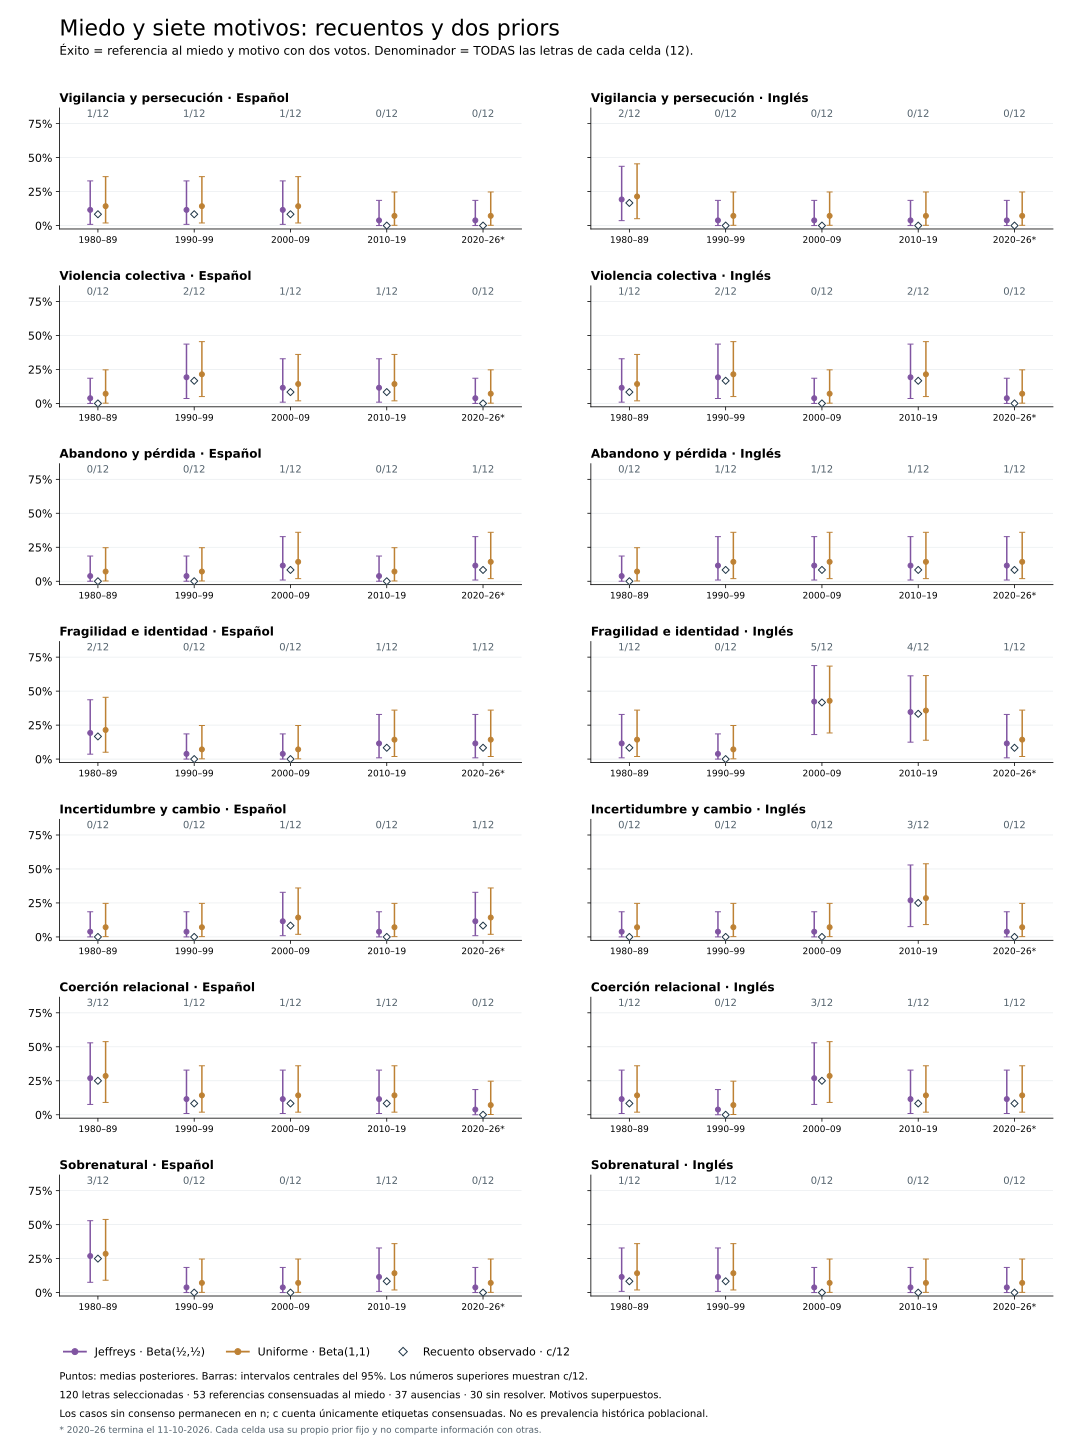

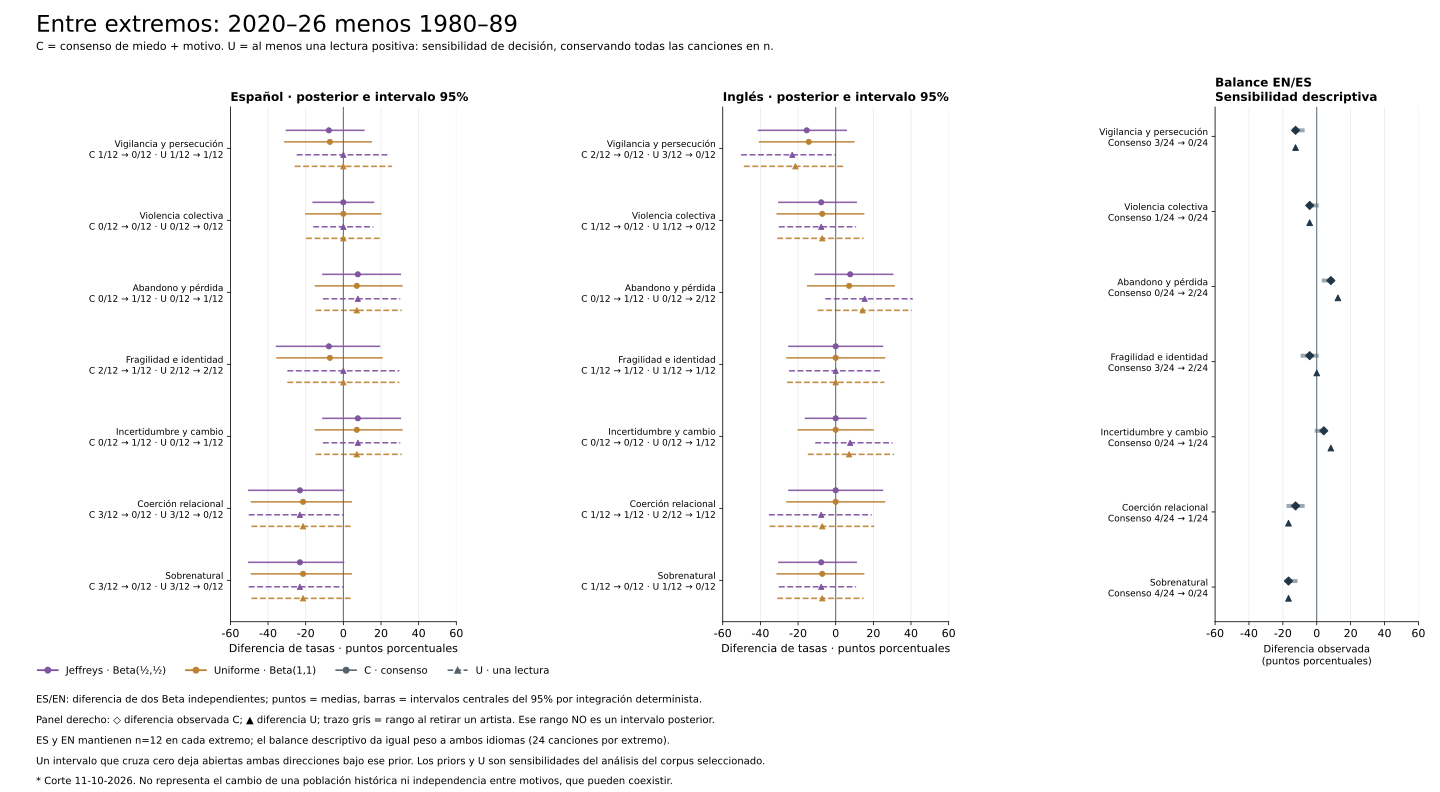

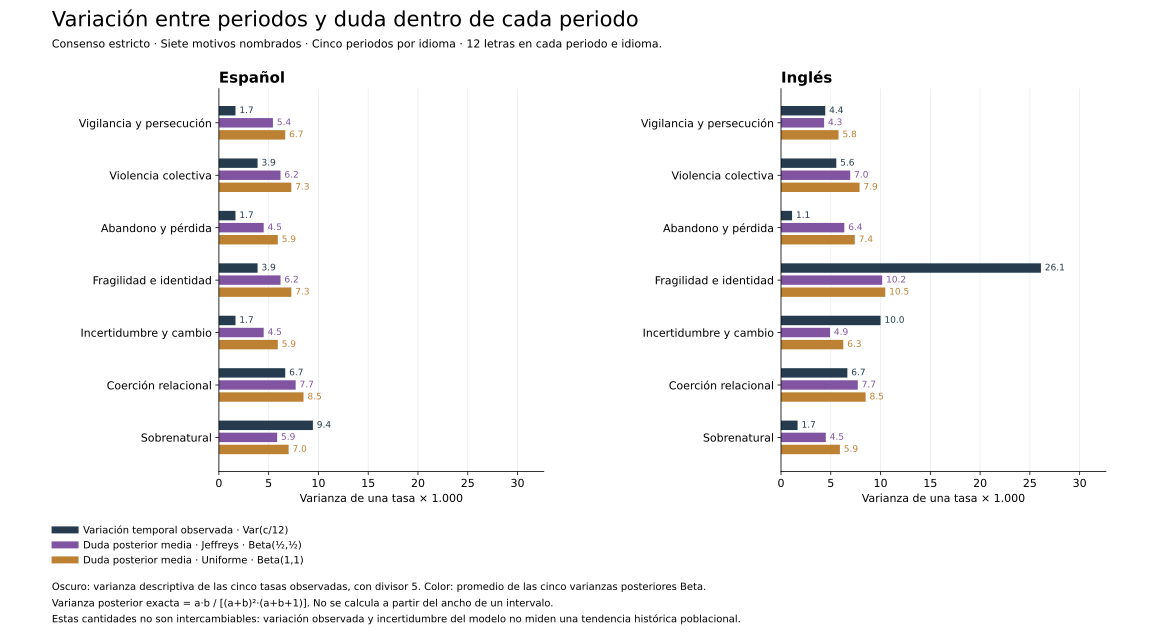

In [19]:
ANNUAL = RESULTS/'annual-120'
annual = read(ANNUAL/'summary.json')
annotations = pd.DataFrame(read(ANNUAL/'annotations.json'))
display(pd.DataFrame([{'referencia':k,'canciones':v} for k,v in annual['fear_reference_counts'].items()]))
display(frame(ANNUAL/'periods.csv'))
display(frame(ANNUAL/'endpoint_sensitivity.csv'))
assert annual['songs']==120 and annual['readings']==240
assert annual['schema_invalid_readings']==annual['arc_structure_invalid_readings']==0
assert annotations.song_id.is_unique
assert len(read(ANNUAL/'votes.json'))==2*len(annotations)
assert sum(annual['arcs_in_fear'].values())==53
print('Años sin canciones seleccionadas:', annual['empty_years'])
print('Acuerdo de presencia con el panel anterior:', annual['prior_panel_presence_agreement'], '/40')
embedding_checks = frame(ANNUAL/'embeddings/neighbor_checks.csv')
if not embedding_checks.empty: display(embedding_checks)
posterior_rates = frame(ANNUAL/'bayes/annual-bayes-posterior-rates.csv')
endpoint_posteriors = frame(ANNUAL/'bayes/annual-bayes-endpoint-posteriors.csv')
display(frame(ANNUAL/'bayes/annual-bayes-variance.csv'))
display(endpoint_posteriors)
for name in ['annual-subtopics-map.svg','annual-arcs-stances.svg','annual-argumental-cases.svg',
             'annual-embeddings-neighbor-checks.svg','annual-bayes-priors.svg',
             'annual-bayes-endpoints.svg','annual-bayes-variance.svg']:
    assert (FIGURES/name).exists(), name
    figure(name)

## 17. Conclusiones y trazabilidad

Las cuatro preguntas de lectura siguen separadas: qué relaciones preserva cada embedding, qué bloques agrupa cada tópico, qué casos componen cada período y qué afirmación sostiene el contexto recuperado. El espectro PCA cuantifica lo que queda fuera del mapa; los cambios de posterior explicitan dependencia del prior; los votos del panel dejan visibles interpretaciones y discrepancias.

La contribución es vincular búsqueda semántica, lectura del miedo y comparación temporal de preocupaciones y respuestas. Los vecindarios de OpenAI muestran concordancia con subtemas por encima de la referencia uniforme del diagnóstico controlado por idioma; sus centroides no conservan posiciones de bloques, de modo que los arcos requieren volver al orden y a las relaciones argumentales.

En la revisión anual de 53 referencias apoyadas hay 14 repeticiones, ocho confrontaciones, cuatro contrastes, cuatro giros, tres relaciones mixtas y veinte arcos inciertos. Fragilidad aparece en cuatro ventanas; coerción, en cinco. Los 28 intervalos estrictos de diferencias entre extremos por motivo, idioma y prior incluyen cero. La evidencia sostiene recurrencias y contrastes de historias, sin una dirección histórica uniforme.

Vigilancia en Every Breath You Take, desafío en Malo, salida en La Puerta Violeta y recuperación en Ansiedad sitúan distintas voces frente a amenazas relacionadas. Aperture queda incierta en la nueva revisión: la historia anterior no se conserva como hecho. Los valores son interpretaciones apoyadas de qué protege una voz, no puntuaciones ni afirmaciones de novedad histórica. Audio, mercados y respuesta de oyentes requieren preguntas y diseños propios.

In [20]:
# Comprobaciones de resultados y denominadores; no se imprimen letras.
assert all(r['results_status']=='executed' for r in model_receipts.values())
assert diag['songs_with_lyrics'] <= len(manifest)
assert set(manifest.language) == {'en','es'}
for directory in modeldirs:
    composition = frame(directory/'decade_composition.csv')
    if not composition.empty:
        totals = composition.groupby(['variant','decade','language']).song_normalized_share.sum()
        assert np.allclose(totals,1), 'Las proporciones no conservan el denominador.'
    projection_file = directory/'projections.json'
    if projection_file.exists():
        p = read(projection_file); r = p['receipt']
        assert r['seed'] is None and r['solver']=='full'
        assert len(p['points']) == r['input_documents']
        assert len(r.get('scree_explained_variance_ratio',r['explained_variance_ratio'])) == min(20,r['input_documents'],r['input_dimensions'])
        assert np.isclose(sum(r['explained_variance_ratio']),r['explained_variance_total'])
    print(directory.name,'✓ recibos, proporciones y proyección')
print('Resultados guardados inspeccionados. Las celdas no ejecutaron APIs ni descargaron letras.')

intfloat--multilingual-e5-small ✓ recibos, proporciones y proyección
openai--text-embedding-3-large ✓ recibos, proporciones y proyección
openai--text-embedding-3-small ✓ recibos, proporciones y proyección
sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2 ✓ recibos, proporciones y proyección
Resultados guardados inspeccionados. Las celdas no ejecutaron APIs ni descargaron letras.


## 18. Recalcular con el corpus privado autorizado

Esta celda permanece desactivada por defecto. Requiere una caché privada cuyo corpus coincida con el manifiesto final, pesos locales y bundles API ya calculados. No descarga letras ni genera nuevas llamadas de embeddings o de lectura. `FEAR_PRIVATE_CACHE` y `FEAR_PRIVATE_CORPUS` permiten señalar la caché de la corrida final.

In [21]:
if RERUN_EXPERIMENTS:
    default_corpus = PRIVATE/'pilot-40/corpus.jsonl' if len(manifest)==40 else PRIVATE/'corpus.jsonl'
    corpus_path = Path(os.environ.get('FEAR_PRIVATE_CORPUS', default_corpus))
    if not corpus_path.exists(): raise FileNotFoundError('Se requiere el corpus privado autorizado de esta corrida.')
    private_rows = [json.loads(line) for line in corpus_path.read_text().splitlines() if line.strip()]
    private_ids = {r['song_id'] for r in private_rows}
    assert private_ids <= set(manifest.song_id) and len(private_ids) == diag['songs_with_lyrics'], 'El corpus privado no coincide con esta edición.'
    bundles = []
    for path in sorted(PRIVATE.rglob('*.npz'), key=lambda p:(p.parent.name!='pilot-comparison',str(p))):
        sidecar = path.with_suffix('.json')
        if sidecar.exists():
            metadata = read(sidecar)
            if set(metadata.get('document_ids',[])) == set(inventory[inventory.document_id.eq(inventory.canonical_id)].document_id):
                bundles.append((path,sidecar,metadata.get('model_id')))
    projection_bundles = []
    for directory in modeldirs:
        encoder = model_receipts[directory.name]['encoder']; model_id = encoder['model_id']
        match = next((b for b in bundles if b[2] in [model_id,model_id.split('/',1)[-1]]),None)
        if match is not None: projection_bundles += ['--bundle',model_id+'='+str(match[0])]
        command = [sys.executable,str(STUDY/'analyze.py'),'--input',str(corpus_path),'--output',str(RESULTS),
                   '--private-cache',str(PRIVATE),'--model-cache',str(PRIVATE/'model-cache'),'--offline']
        if encoder.get('input_type') == 'verified_external_embedding_bundle':
            if match is None: raise FileNotFoundError('No existe un bundle local verificado para '+model_id)
            command += ['--embedding-file',str(match[0]),'--embedding-metadata',str(match[1]),'--model-label',model_id]
        else: command += ['--models',model_id]
        subprocess.run(command,cwd=ROOT,check=True)
    ids = [r['encoder']['model_id'] for r in model_receipts.values()]
    subprocess.run([sys.executable,str(STUDY/'projections.py'),'--results',str(RESULTS),
                    '--manifest',str(STUDY/'corpus-manifest.json'),'--cache',str(PRIVATE),*projection_bundles],cwd=ROOT,check=True)
    subprocess.run([sys.executable,str(STUDY/'bayes.py'),'--results',str(RESULTS),
                    '--private-cache',str(PRIVATE),'--models',*ids],cwd=ROOT,check=True)
    subprocess.run([sys.executable,str(STUDY/'evaluate.py')],cwd=ROOT,check=True)
    subprocess.run([sys.executable,str(STUDY/'visualize.py')],cwd=ROOT,check=True)
    subprocess.run([sys.executable,str(STUDY/'atlas_v2.py')],cwd=ROOT,check=True)
else: print('Reejecución desactivada: se conservaron resultados y presupuestos.')

Reejecución desactivada: se conservaron resultados y presupuestos.


## Apéndice A. Controles originales de alcance y formato

Los controles ficticios distinguen lo que una voz reporta de lo que un registro estipulado como autoritativo establece sobre un performer ficticio. Sus cuatro familias de slots se cruzan con tres alcances y permanecen congeladas. Su autoridad sólo existe dentro de ese escenario.

Los IDs de estos controles nombran el alcance: la prueba mide seguir una estipulación explícita, no autenticar documentos reales.

La revisión de formato V2 explicita cinco claves JSON para todos los modelos; OpenAI añade un esquema estricto y Anthropic sigue la restricción textual. Esa diferencia de interfaz permanece documentada. Las decisiones, las citas existentes y la fidelidad del contenido son objetos distintos. Las doce condiciones inglesas son controles de mecanismo, dependientes dentro de cada familia.

In [22]:
control_dir = RESULTS/'llm-comparison-detail-controls-v2'
if (control_dir/'summary.json').exists():
    summary = read(control_dir/'summary.json')
    table = pd.DataFrame(public_rows(summary))
    columns = [c for c in ['model_id','requested','valid','assistant_expected_matches','expected_constraints',
        'voice_report_supported','authoritative_supported','verified_missing_safe_abstentions',
        'supported_expected_id_cited','invalid_citation_reviews'] if c in table]
    display(table[columns])
    display(Markdown('La reparación de interfaz conserva los casos y sus expectativas; no constituye un conjunto independiente.'))
synthetic_dir = RESULTS/'llm-comparison-synthetic'
if (synthetic_dir/'summary.json').exists():
    summary = read(synthetic_dir/'summary.json')
    table = pd.DataFrame(public_rows(summary))
    columns = [c for c in ['model_id','requested','valid','core_assistant_constraints',
        'core_constraint_matches','coexistence_false_contradictions'] if c in table]
    display(table[columns])
    if summary.get('pairwise'): display(pd.DataFrame(summary['pairwise']))

,model_id,requested,valid,assistant_expected_matches,expected_constraints,voice_report_supported,authoritative_supported,verified_missing_safe_abstentions,supported_expected_id_cited,invalid_citation_reviews
0,openai/gpt-5.4-mini,12,12,12,12,4,4,4,8,0
1,openai/gpt-5.4-nano,12,12,12,12,4,4,4,8,0
2,anthropic/claude-sonnet-4-6,12,12,11,12,4,3,4,8,0
3,anthropic/claude-haiku-4-5-20251001,12,12,12,12,4,4,4,8,0


La reparación de interfaz conserva los casos y sus expectativas; no constituye un conjunto independiente.

,model_id,requested,valid,core_assistant_constraints,core_constraint_matches,coexistence_false_contradictions
0,openai/gpt-5.4-mini,20,20,9,9,0
1,openai/gpt-5.4-nano,20,20,9,9,0
2,anthropic/claude-sonnet-4-6,20,20,9,7,2
3,anthropic/claude-haiku-4-5-20251001,20,20,9,9,0


,left,right,common_triplets,pair_judgments,agreement_count,agreement_fraction,limitation
0,openai/gpt-5.4-mini,openai/gpt-5.4-nano,20,40,31,0.775,Agreement is not correctness; paired language/...
1,openai/gpt-5.4-mini,anthropic/claude-sonnet-4-6,20,40,28,0.700,Agreement is not correctness; paired language/...
2,openai/gpt-5.4-mini,anthropic/claude-haiku-4-5-20251001,20,40,29,0.725,Agreement is not correctness; paired language/...
3,openai/gpt-5.4-nano,anthropic/claude-sonnet-4-6,20,40,28,0.700,Agreement is not correctness; paired language/...
4,openai/gpt-5.4-nano,anthropic/claude-haiku-4-5-20251001,20,40,31,0.775,Agreement is not correctness; paired language/...
5,anthropic/claude-sonnet-4-6,anthropic/claude-haiku-4-5-20251001,20,40,34,0.850,Agreement is not correctness; paired language/...
